# [기초-실습] 통계 101×데이터 분석: (9-10장) 가설검정의 주의점/인과와 상관

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비

### 1단계 · 한글 폰트 설치

- 그래프에 한글이 깨지지 않도록 나눔 폰트를 설치합니다.

- 실행 후 **[런타임] - [세션 다시 시작]**을 한 번 눌러야 폰트가 적용됩니다.

In [1]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!pip install statsmodels scikit-learn
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Fetched 10.3 MB in 0s (32.9 MB/s)
Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and directories curr

### 2단계 · 라이브러리 불러오기

- 이번 실습에서 쓰는 도구입니다. **한 번만 실행**해 두면 끝까지 사용합니다.

- `TTestIndPower`는 검정력·표본크기를 계산하는 클래스, `NearestNeighbors`는 경향점수가 가장 가까운
  짝을 찾아주는 도구입니다.

In [2]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.power import TTestIndPower
from sklearn.neighbors import NearestNeighbors
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

---

# 가설검정의 주의점

> p-값 하나로 결론을 내리면 무엇을 놓치는지, 그리고 "유의한 결과"가 어떻게 **만들어질 수 있는지**를 봅니다.

## 문제 1 · 펭귄 두 종의 몸무게는 정말 다를까?

`난이도 하` · `예상 20분`

**📖 상황**

- 7장에서 Adelie 수컷만 골라 회귀했을 때 p-값이 0.05를 넘어 **기각에 실패**했습니다.
  그때 우리는 "표본이 작아서"라고 정리했습니다.

- 이제 반대편에서 물어봅니다. **표본을 아주 크게 만들면 어떤 일이 벌어질까요?**

- 실제 팔머 기지 데이터에서 Adelie와 Chinstrap의 몸무게는 평균 **32g**밖에 차이나지 않습니다.
  펭귄 한 마리 몸무게(약 3,700g)의 **1%도 안 되는** 차이입니다.

- 이 32g을 붙잡고 표본만 늘려 가면, p-값은 어디까지 내려갈까요?

**🎯 이 문제로 배우는 것**

- **"표본크기 n이 커지면 p-값은 작아진다"**는 강의 9장의 명제를 실제 데이터로 확인하고,
  그래서 **효과크기(Effect Size)**를 함께 봐야 하는 이유를 숫자로 이해합니다.

In [3]:
# 문제 1 · 데이터 준비 — 실행만 하세요
penguins = sns.load_dataset('penguins')
mass = penguins.dropna(subset=['body_mass_g', 'species'])

adelie    = mass.loc[mass['species'] == 'Adelie',    'body_mass_g']
chinstrap = mass.loc[mass['species'] == 'Chinstrap', 'body_mass_g']

print("Adelie    n=%3d   평균 %.1f g   표준편차 %.1f g" % (len(adelie),    adelie.mean(),    adelie.std(ddof=1)))
print("Chinstrap n=%3d   평균 %.1f g   표준편차 %.1f g" % (len(chinstrap), chinstrap.mean(), chinstrap.std(ddof=1)))

diff_g = adelie.mean() - chinstrap.mean()
print("\n두 종의 평균 차이: %.1f g  (Adelie 몸무게의 약 %.1f%%)" % (diff_g, abs(diff_g) / adelie.mean() * 100))

Adelie    n=151   평균 3700.7 g   표준편차 458.6 g
Chinstrap n= 68   평균 3733.1 g   표준편차 384.3 g

두 종의 평균 차이: -32.4 g  (Adelie 몸무게의 약 0.9%)


### Q1 · 두 종의 몸무게를 t-검정으로 비교해 봅시다

- `adelie`와 `chinstrap`의 몸무게에 대해 **이표본 t-검정(Two-sample t-Test)**을 수행하세요.
  5-6장 실습에서 쓴 그 검정입니다.

- 유의수준 0.05를 기준으로 **"기각한다 / 기각하지 못한다"까지 문장으로 출력**하세요.

- `💡 힌트` `stats.ttest_ind(x, y)`는 통계량과 p-값을 함께 돌려줍니다.

 가설 설정
▸귀무가설 H0 (Null hypothesis)
   두 종의 평균 몸무게는 같다.        μ_Adelie = μ_Chinstrap
   → '차이가 없다'는 기본 가정. 검정은 이 가정을 의심할 증거가 있는지 본다.
▸대립가설 H1 (Alternative hypothesis)
   두 종의 평균 몸무게는 다르다.      μ_Adelie ≠ μ_Chinstrap  (양측검정)
   → 연구자가 보이고 싶은 주장. H0가 기각될 때 채택한다.
▸판단 기준: 유의수준 α = 0.05
   p < α  → H0 기각 (차이가 있다고 결론)
   p ≥ α  → H0 기각 못함 (차이가 있다고 말할 근거 부족 ≠ 차이가 없다는 증명)

[검정 결과]
t-통계량 = -0.5081
p-값     = 0.6119

p-값(0.6119) ≥ 유의수준(0.05) → 귀무가설을 기각하지 못한다.
→ 두 종의 평균 몸무게가 다르다고 말할 근거가 부족하다.


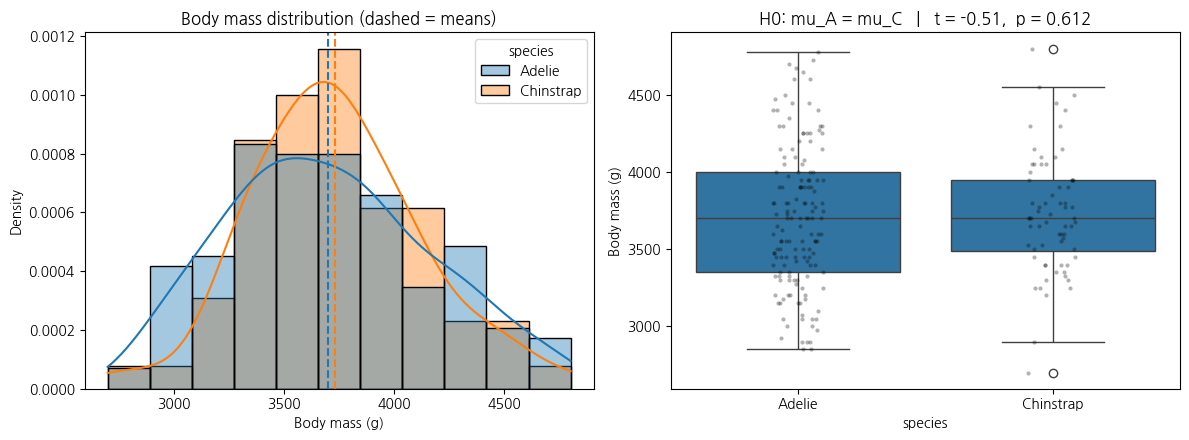

In [17]:
# 문제 1 · Q1 · 두 종의 몸무게를 t-검정으로 비교
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# 0) 가설 정의
print("=" * 64)
print(" 가설 설정")
print("=" * 64)
print("▸귀무가설 H0 (Null hypothesis)")
print("   두 종의 평균 몸무게는 같다.        μ_Adelie = μ_Chinstrap")
print("   → '차이가 없다'는 기본 가정. 검정은 이 가정을 의심할 증거가 있는지 본다.")
print("▸대립가설 H1 (Alternative hypothesis)")
print("   두 종의 평균 몸무게는 다르다.      μ_Adelie ≠ μ_Chinstrap  (양측검정)")
print("   → 연구자가 보이고 싶은 주장. H0가 기각될 때 채택한다.")
print("▸판단 기준: 유의수준 α = 0.05")
print("   p < α  → H0 기각 (차이가 있다고 결론)")
print("   p ≥ α  → H0 기각 못함 (차이가 있다고 말할 근거 부족 ≠ 차이가 없다는 증명)")
print("=" * 64)
print()

# 1) 이표본 t-검정 (힌트대로 stats.ttest_ind 사용, 기본값 equal_var=True)
t_stat, p_value = stats.ttest_ind(adelie, chinstrap)

print("[검정 결과]")
print("t-통계량 = %.4f" % t_stat)
print("p-값     = %.4f" % p_value)

# 2) 유의수준 0.05 기준 판단
alpha = 0.05
if p_value < alpha:
    print("\np-값(%.4f) < 유의수준(%.2f) → 귀무가설을 기각한다." % (p_value, alpha))
    print("→ 대립가설 채택: 두 종의 평균 몸무게에는 통계적으로 유의한 차이가 있다.")
else:
    print("\np-값(%.4f) ≥ 유의수준(%.2f) → 귀무가설을 기각하지 못한다." % (p_value, alpha))
    print("→ 두 종의 평균 몸무게가 다르다고 말할 근거가 부족하다.")

# 3) 그래프: 분포 비교 (히스토그램 + 박스플롯)
two = mass[mass['species'].isin(['Adelie', 'Chinstrap'])]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(data=two, x='body_mass_g', hue='species', kde=True,
             stat='density', common_norm=False, alpha=0.4, ax=axes[0])
axes[0].axvline(adelie.mean(), color='C0', linestyle='--')
axes[0].axvline(chinstrap.mean(), color='C1', linestyle='--')
axes[0].set_title('Body mass distribution (dashed = means)')
axes[0].set_xlabel('Body mass (g)')

sns.boxplot(data=two, x='species', y='body_mass_g', ax=axes[1])
sns.stripplot(data=two, x='species', y='body_mass_g', color='black',
              alpha=0.3, size=3, ax=axes[1])
axes[1].set_title('H0: mu_A = mu_C   |   t = %.2f,  p = %.3f' % (t_stat, p_value))
axes[1].set_ylabel('Body mass (g)')

plt.tight_layout()
plt.show()

### Q2 · 효과크기(Cohen's d)를 직접 계산해 봅시다

- 강의 9장의 공식대로 `cohen_d(x, y)` **함수를 직접 만드세요. Q3에서 계속 씁니다.**
  - 분자: 두 집단 평균의 차이
  - 분모: 통합 표준편차 $s = \sqrt{\dfrac{(n_A-1)s_A^2 + (n_B-1)s_B^2}{n_A + n_B - 2}}$

- 만든 함수로 `adelie`와 `chinstrap`의 효과크기를 계산해 출력하세요.

- Cohen의 관례적 기준(0.2 작음 / 0.5 중간 / 0.8 큼)에서 어디에 놓이는지도 함께 적으세요.

- `💡 힌트` 표본표준편차는 `np.std(x, ddof=1)`, 표본 수는 `len(x)`입니다.

▸Cohen's d: 두 평균 차이가 '표준편차 몇 개'인지 나타내는 효과크기
▸공식 d = (x̄A − x̄B) / s   분자: 평균 차이 / 분모: 통합 표준편차
▸쓰임: t-검정 결과 보고, 연구 간 비교, 표본수 설계
▸기준(|d|): <0.2 무시 / 0.2 작음(92% 겹침) / 0.5 중간(80%) / 0.8 큼(69%)

분자 -32.4 g / 분모 437.0 g = d -0.0742
겹침 97.0% → |d| 0.074: 무시할 수준


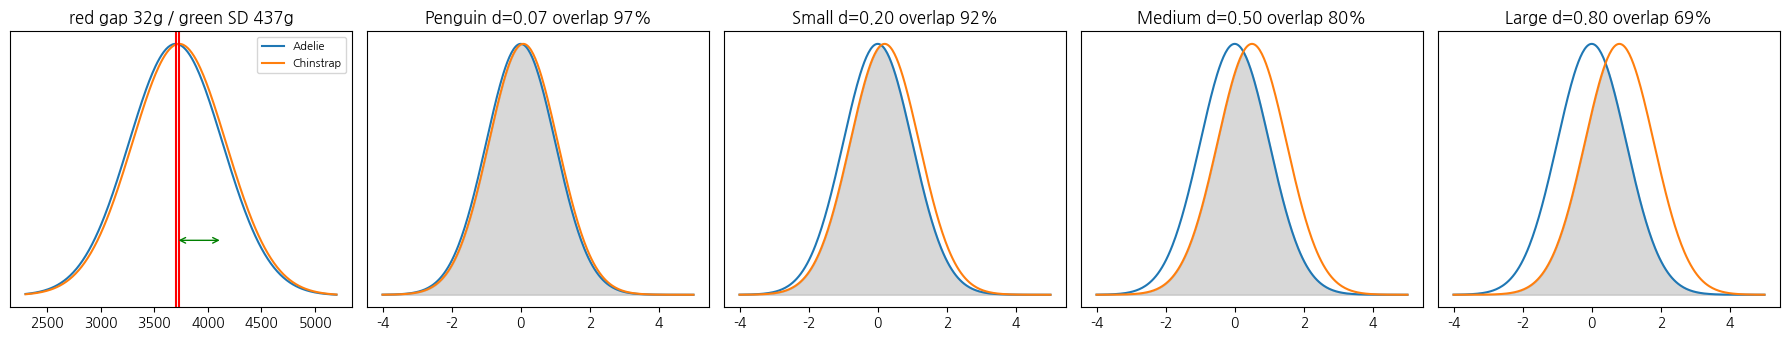

In [18]:
# 문제 1 · Q2 · Cohen's d
import numpy as np, matplotlib.pyplot as plt
from scipy import stats

print("▸Cohen's d: 두 평균 차이가 '표준편차 몇 개'인지 나타내는 효과크기")
print("▸공식 d = (x̄A − x̄B) / s   분자: 평균 차이 / 분모: 통합 표준편차")
print("▸쓰임: t-검정 결과 보고, 연구 간 비교, 표본수 설계")
print("▸기준(|d|): <0.2 무시 / 0.2 작음(92% 겹침) / 0.5 중간(80%) / 0.8 큼(69%)\n")

def cohen_d(x, y):
    nA, nB = len(x), len(y)
    s = np.sqrt(((nA-1)*np.var(x, ddof=1) + (nB-1)*np.var(y, ddof=1)) / (nA+nB-2))
    return (np.mean(x) - np.mean(y)) / s

mA, mB = np.mean(adelie), np.mean(chinstrap)
s = (mA - mB) / cohen_d(adelie, chinstrap)
d = cohen_d(adelie, chinstrap)
ov = lambda x: 2 * stats.norm.cdf(-abs(x) / 2) * 100
lv = "무시할 수준" if abs(d) < .2 else "작음" if abs(d) < .5 else "중간" if abs(d) < .8 else "큼"
print("분자 %.1f g / 분모 %.1f g = d %.4f" % (mA - mB, s, d))
print("겹침 %.1f%% → |d| %.3f: %s" % (ov(d), abs(d), lv))

fig, ax = plt.subplots(1, 5, figsize=(18, 3.5))
x = np.linspace(2300, 5200, 300)
ax[0].plot(x, stats.norm.pdf(x, mA, s), label='Adelie')
ax[0].plot(x, stats.norm.pdf(x, mB, s), label='Chinstrap')
ax[0].annotate('', (mA + s, 2e-4), (mA, 2e-4), arrowprops=dict(arrowstyle='<->', color='g'))
ax[0].set_title('red gap %.0fg / green SD %.0fg' % (abs(mA - mB), s))
ax[0].axvline(mA, color='r'); ax[0].axvline(mB, color='r'); ax[0].legend(fontsize=8)
z = np.linspace(-4, 5, 300)
for i, (v, n) in enumerate([(abs(d), 'Penguin'), (.2, 'Small'), (.5, 'Medium'), (.8, 'Large')]):
    p0, p1 = stats.norm.pdf(z), stats.norm.pdf(z, v)
    ax[i+1].plot(z, p0); ax[i+1].plot(z, p1)
    ax[i+1].fill_between(z, np.minimum(p0, p1), color='gray', alpha=.3)
    ax[i+1].set_title('%s d=%.2f overlap %.0f%%' % (n, v, ov(v)))
for a in ax: a.set_yticks([])
plt.tight_layout(); plt.show()

### Q3 · 표본을 늘려 가며 p-값과 효과크기를 함께 추적해 봅시다

- Q1에서 본 두 종의 평균과 통합 표준편차를 **모집단 참값**으로 삼습니다.
  즉 "실제로 32g 차이가 나는 두 집단"에서 표본을 뽑는 상황을 만듭니다.

- `n = 30, 150, 1000, 5000, 20000` 각각에 대해, 두 집단에서 n마리씩 뽑아
  **t-검정과 Cohen's d를 400번 반복**하세요.

- 각 n마다 다음 세 값을 표로 정리해 출력하세요.
  **① p-값의 중위수 ② p < 0.05가 나온 비율(%) ③ Cohen's d의 평균**

- `💡 힌트` 모집단 참값은 이렇게 잡습니다.

  ```
  MU_A, MU_C = adelie.mean(), chinstrap.mean()
  SIGMA = np.sqrt(((len(adelie)-1)*adelie.std(ddof=1)**2 + (len(chinstrap)-1)*chinstrap.std(ddof=1)**2)
                  / (len(adelie) + len(chinstrap) - 2))
  ```

- `💡 힌트` 표본 추출은 `rng = np.random.default_rng(7)`로 시작해 `rng.normal(MU_A, SIGMA, n)`.
  결과는 리스트에 모아 `pd.DataFrame`으로 만들면 보기 좋습니다.

 표본 크기에 따른 p-값과 효과크기 추적
▸모집단 참값: Q1의 두 종 평균과 통합 표준편차
   → '실제로 약 32g 차이가 나는 두 집단'에서 표본을 뽑는 상황
▸n = 30, 150, 1000, 5000, 20000 마다 400번 반복
   ▸매번 두 집단에서 n마리씩 뽑아 t-검정과 Cohen's d 계산
▸정리할 값: ① p-값의 중위수  ② p < 0.05 비율(%)  ③ Cohen's d 평균

[모집단 참값]
▸MU_A = 3700.7 g,  MU_C = 3733.1 g,  SIGMA = 437.0 g
▸참 효과크기 d = -0.0742

[시뮬레이션 결과 (각 n마다 400번 반복)]
    n ① p-값 중위수 ② p<0.05 비율(%) ③ Cohen's d 평균
   30      4.67e-01              5.8          -0.0807
  150      4.42e-01              9.5          -0.0686
 1000      8.41e-02             39.2          -0.0755
 5000      1.58e-04             95.5          -0.0749
20000      1.31e-13            100.0          -0.0740

▸해석
   ▸n이 커질수록 p-값은 0에 가까워지고, 유의한 비율은 100%로 올라간다
   ▸하지만 Cohen's d 평균은 n과 상관없이 참값(-0.074) 근처에 머문다
   ▸즉 '유의하다'가 '차이가 크다'는 뜻은 아니다 → 효과크기를 함께 봐야 한다

 [그래프 설명] 아래 그래프 4개가 각각 보여주는 것
▸1) p-값의 중위수 (세로축 로그 눈금)
   가로축: 종마다 뽑은 마리 수 n / 세로축: 400번 검정한 p-값의 가운데 값
   빨간 점선: 유의수준 0.05. 점이 이 선 아래면 400번 중 절반 넘게 유의했다는 뜻
   → n이 커질수록 p-값이 0을 향해 급격히 떨어지는 것을

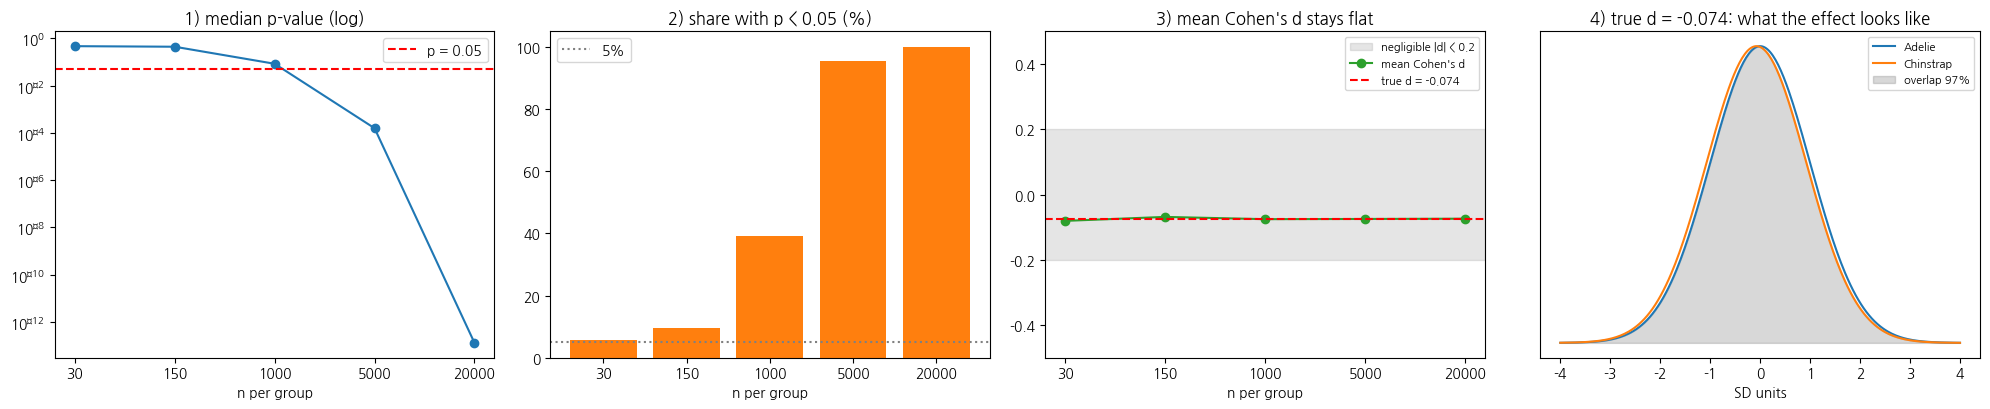

In [19]:
# Q3 · 표본을 늘려 가며 p-값과 효과크기를 함께 추적해 봅시다
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

print("=" * 60)
print(" 표본 크기에 따른 p-값과 효과크기 추적")
print("=" * 60)
print("▸모집단 참값: Q1의 두 종 평균과 통합 표준편차")
print("   → '실제로 약 32g 차이가 나는 두 집단'에서 표본을 뽑는 상황")
print("▸n = 30, 150, 1000, 5000, 20000 마다 400번 반복")
print("   ▸매번 두 집단에서 n마리씩 뽑아 t-검정과 Cohen's d 계산")
print("▸정리할 값: ① p-값의 중위수  ② p < 0.05 비율(%)  ③ Cohen's d 평균")
print("=" * 60)
print()

def cohen_d(x, y):
    nA, nB = len(x), len(y)
    sA, sB = np.std(x, ddof=1), np.std(y, ddof=1)
    s_pooled = np.sqrt(((nA - 1) * sA**2 + (nB - 1) * sB**2) / (nA + nB - 2))
    return (np.mean(x) - np.mean(y)) / s_pooled

MU_A, MU_C = adelie.mean(), chinstrap.mean()
SIGMA = np.sqrt(((len(adelie)-1)*adelie.std(ddof=1)**2 + (len(chinstrap)-1)*chinstrap.std(ddof=1)**2)
                / (len(adelie) + len(chinstrap) - 2))
TRUE_D = (MU_A - MU_C) / SIGMA

print("[모집단 참값]")
print("▸MU_A = %.1f g,  MU_C = %.1f g,  SIGMA = %.1f g" % (MU_A, MU_C, SIGMA))
print("▸참 효과크기 d = %.4f" % TRUE_D)
print()

rng = np.random.default_rng(7)
n_list = [30, 150, 1000, 5000, 20000]
REPS = 400
alpha = 0.05

results = []
for n in n_list:
    p_values = []
    d_values = []
    for _ in range(REPS):
        a = rng.normal(MU_A, SIGMA, n)
        c = rng.normal(MU_C, SIGMA, n)
        t_stat, p = stats.ttest_ind(a, c)
        p_values.append(p)
        d_values.append(cohen_d(a, c))
    p_values = np.array(p_values)
    row = {}
    row['n'] = n
    row['p_median'] = np.median(p_values)
    row['sig_pct'] = np.mean(p_values < alpha) * 100
    row['d_mean'] = np.mean(d_values)
    results.append(row)

df = pd.DataFrame(results)

show = df.copy()
show['p_median'] = show['p_median'].map(lambda v: "%.2e" % v)
show['sig_pct'] = show['sig_pct'].map(lambda v: "%.1f" % v)
show['d_mean'] = show['d_mean'].map(lambda v: "%.4f" % v)
show.columns = ['n', '① p-값 중위수', '② p<0.05 비율(%)', "③ Cohen's d 평균"]

print("[시뮬레이션 결과 (각 n마다 %d번 반복)]" % REPS)
print(show.to_string(index=False))
print()
print("▸해석")
print("   ▸n이 커질수록 p-값은 0에 가까워지고, 유의한 비율은 100%로 올라간다")
print("   ▸하지만 Cohen's d 평균은 n과 상관없이 참값(%.3f) 근처에 머문다" % TRUE_D)
print("   ▸즉 '유의하다'가 '차이가 크다'는 뜻은 아니다 → 효과크기를 함께 봐야 한다")

# ---------- 그래프 설명 ----------
print()
print("=" * 60)
print(" [그래프 설명] 아래 그래프 4개가 각각 보여주는 것")
print("=" * 60)
print("▸1) p-값의 중위수 (세로축 로그 눈금)")
print("   가로축: 종마다 뽑은 마리 수 n / 세로축: 400번 검정한 p-값의 가운데 값")
print("   빨간 점선: 유의수준 0.05. 점이 이 선 아래면 400번 중 절반 넘게 유의했다는 뜻")
print("   → n이 커질수록 p-값이 0을 향해 급격히 떨어지는 것을 본다")
print("▸2) p < 0.05가 나온 비율(%)")
print("   막대: 400번 중 '유의하다'고 결론 난 비율 / 회색 점선: 5% (우연 수준)")
print("   → n이 작을 땐 5% 근처라 거의 못 잡지만, n이 커지면 100%까지 올라간다")
print("▸3) Cohen's d의 평균")
print("   초록 점: 400번 계산한 d의 평균 / 빨간 점선: 참값 d / 회색 띠: |d| < 0.2 (무시할 수준)")
print("   → 1)·2)와 달리 n이 바뀌어도 d는 참값 위에 평평하게, 회색 띠 안에 머문다")
print("▸4) 참 d = %.3f인 두 집단의 실제 모습" % TRUE_D)
print("   가로축: 표준편차 단위 / 파랑·주황: 두 종의 분포 / 회색: 겹치는 부분")
print("   → 두 분포가 약 %.0f%% 겹친다. 표본을 늘려 '유의'해져도 실제 차이는 이 정도로 작다"
      % (2 * stats.norm.cdf(-abs(TRUE_D) / 2) * 100))
print("▸한 줄 요약: 1)·2)는 n에 따라 크게 변하지만, 3)의 효과크기는 변하지 않는다")
print("   → p-값은 표본 크기에 좌우되고, 효과크기는 차이 자체의 크기를 보여준다")
print("=" * 60)

# ---------- 그래프 ----------
ns = [str(n) for n in df['n']]
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))

ax[0].plot(ns, df['p_median'], 'o-')
ax[0].axhline(0.05, color='red', ls='--', label='p = 0.05')
ax[0].set_yscale('log'); ax[0].set_title('1) median p-value (log)'); ax[0].legend()

ax[1].bar(ns, df['sig_pct'], color='C1')
ax[1].axhline(5, color='gray', ls=':', label='5%')
ax[1].set_ylim(0, 105); ax[1].set_title('2) share with p < 0.05 (%)'); ax[1].legend()

ax[2].axhspan(-0.2, 0.2, color='gray', alpha=0.2, label='negligible |d| < 0.2')
ax[2].plot(ns, df['d_mean'], 'o-', color='C2', label="mean Cohen's d")
ax[2].axhline(TRUE_D, color='red', ls='--', label='true d = %.3f' % TRUE_D)
ax[2].set_ylim(-0.5, 0.5); ax[2].set_title("3) mean Cohen's d stays flat"); ax[2].legend(fontsize=8)
for a in ax[:3]:
    a.set_xlabel('n per group')

z = np.linspace(-4, 4, 300)
p0, p1 = stats.norm.pdf(z, 0, 1), stats.norm.pdf(z, TRUE_D, 1)
ov = 2 * stats.norm.cdf(-abs(TRUE_D) / 2) * 100
ax[3].plot(z, p0, label='Adelie'); ax[3].plot(z, p1, label='Chinstrap')
ax[3].fill_between(z, np.minimum(p0, p1), color='gray', alpha=0.3, label='overlap %.0f%%' % ov)
ax[3].set_yticks([]); ax[3].set_xlabel('SD units')
ax[3].set_title('4) true d = %.3f: what the effect looks like' % TRUE_D); ax[3].legend(fontsize=8)

plt.tight_layout()
plt.show()

### Q4 · 결과를 그래프로 그려 봅시다

- 가로축을 **표본크기 n**으로, 두 그림을 **나란히** 그리세요.
  - 왼쪽: n에 따른 **p < 0.05 비율(%)**
  - 오른쪽: n에 따른 **Cohen's d 평균**

- n이 30에서 20,000까지 넓게 퍼져 있으니 **가로축을 로그 스케일**로 두면 잘 보입니다.

- `💡 힌트` `fig, ax = plt.subplots(1, 2, figsize=(12, 4))` / `ax[0].set_xscale('log')`

 Q3 결과 그래프: 표본 크기 n에 따른 변화
▸가로축: 표본 크기 n (30 ~ 20,000, 로그 스케일)
   ▸값이 넓게 퍼져 있어 로그 스케일로 두면 간격이 고르게 보임
▸왼쪽: n에 따른 p < 0.05 비율(%)
▸오른쪽: n에 따른 Cohen's d 평균

    n  sig_pct  d_mean
   30     5.75 -0.0807
  150     9.50 -0.0686
 1000    39.25 -0.0755
 5000    95.50 -0.0749
20000   100.00 -0.0740
▸해석
   ▸왼쪽: n이 커질수록 p < 0.05 비율이 5% 근처에서 거의 100%까지 치솟는다
   ▸오른쪽: Cohen's d 평균은 n과 상관없이 참값(-0.074) 근처에서 거의 평평하다
   ▸결론: 표본이 크면 아주 작은 차이도 '유의'해지지만, 차이의 크기 자체는 그대로다


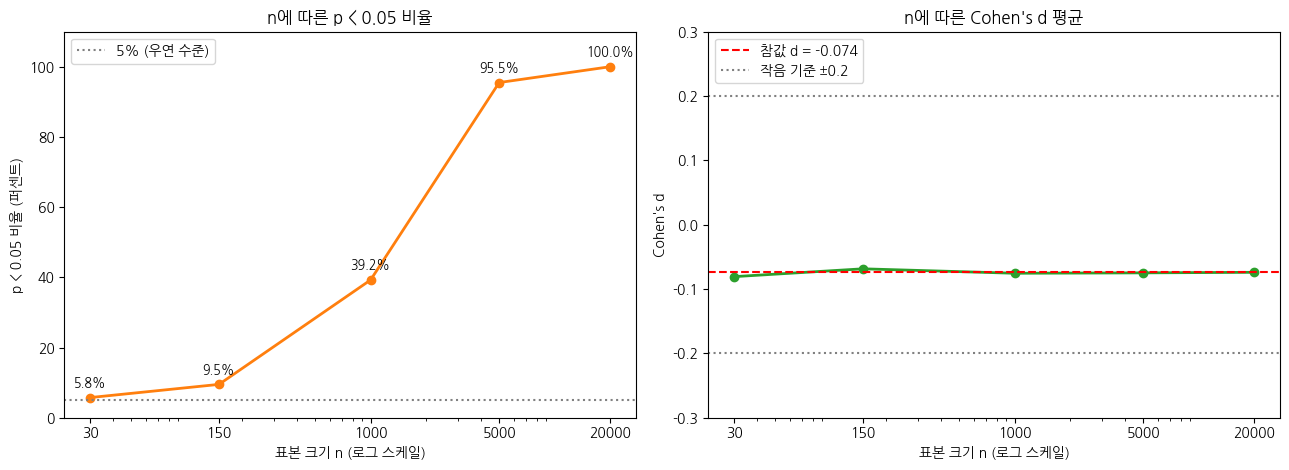

In [4]:
# Q4 · 결과를 그래프로 그려 봅시다
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

print("=" * 60)
print(" Q3 결과 그래프: 표본 크기 n에 따른 변화")
print("=" * 60)
print("▸가로축: 표본 크기 n (30 ~ 20,000, 로그 스케일)")
print("   ▸값이 넓게 퍼져 있어 로그 스케일로 두면 간격이 고르게 보임")
print("▸왼쪽: n에 따른 p < 0.05 비율(%)")
print("▸오른쪽: n에 따른 Cohen's d 평균")
print("=" * 60)
print()
print(df[['n', 'sig_pct', 'd_mean']].round(4).to_string(index=False))

# 한글 폰트 찾기
installed = {f.name for f in fm.fontManager.ttflist}
found = None
for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'NanumBarunGothic']:
    if f in installed:
        found = f
        break
if found:
    plt.rc('font', family=found)
    plt.rcParams['axes.unicode_minus'] = False

def T(ko, en):
    if found:
        return ko
    return en

ns = df['n'].values
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# (왼쪽) p < 0.05 비율
axes[0].plot(ns, df['sig_pct'], marker='o', color='C1', linewidth=2)
axes[0].axhline(5, color='gray', linestyle=':', label=T('5% (우연 수준)', '5% (chance)'))
for x, y in zip(ns, df['sig_pct']):
    axes[0].text(x, y + 3, '%.1f%%' % y, ha='center', fontsize=9)
axes[0].set_xscale('log')
axes[0].set_xticks(ns)
axes[0].set_xticklabels([str(n) for n in ns])
axes[0].set_ylim(0, 110)
axes[0].set_xlabel(T('표본 크기 n (로그 스케일)', 'Sample size n (log scale)'))
axes[0].set_ylabel(T('p < 0.05 비율 (퍼센트)', 'Share with p < 0.05 (pct)'))
axes[0].set_title(T('n에 따른 p < 0.05 비율', 'Share of p < 0.05 by n'))
axes[0].legend(loc='upper left')

# (오른쪽) Cohen's d 평균
axes[1].plot(ns, df['d_mean'], marker='o', color='C2', linewidth=2)
axes[1].axhline(TRUE_D, color='red', linestyle='--', label=T('참값 d = %.3f' % TRUE_D, 'true d = %.3f' % TRUE_D))
axes[1].axhline(-0.2, color='gray', linestyle=':', label=T('작음 기준 ±0.2', 'small ±0.2'))
axes[1].axhline(0.2, color='gray', linestyle=':')
axes[1].set_xscale('log')
axes[1].set_xticks(ns)
axes[1].set_xticklabels([str(n) for n in ns])
axes[1].set_ylim(-0.3, 0.3)
axes[1].set_xlabel(T('표본 크기 n (로그 스케일)', 'Sample size n (log scale)'))
axes[1].set_ylabel("Cohen's d")
axes[1].set_title(T("n에 따른 Cohen's d 평균", "Mean Cohen's d by n"))
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

print("▸해석")
print("   ▸왼쪽: n이 커질수록 p < 0.05 비율이 5% 근처에서 거의 100%까지 치솟는다")
print("   ▸오른쪽: Cohen's d 평균은 n과 상관없이 참값(%.3f) 근처에서 거의 평평하다" % TRUE_D)
print("   ▸결론: 표본이 크면 아주 작은 차이도 '유의'해지지만, 차이의 크기 자체는 그대로다")

### 💬 정리 · 결과를 말로 설명해 보기

- Q1에서 두 종의 몸무게는 통계적으로 유의한 차이가 **없었습니다.** 그런데 Q3에서 n=5,000일 때는
  95% 이상 유의하게 나왔습니다. **같은 32g인데 결론이 갈린 이유**는 무엇인가요?

- Q3의 표에서 n이 커질 때 **p-값**은 어떻게 변했나요? **Cohen's d**는 어떻게 변했나요?
  이 대비가 뜻하는 바를 한 문장으로 정리해 보세요.

- "통계적으로 유의하다"와 "실질적으로 의미 있다"는 같은 말인가요? 펭귄 32g을 예로 설명해 보세요.

- A/B 테스트에서 버튼 색을 바꿨더니 클릭률이 0.1%p 올랐고 p-값은 0.001이었습니다.
  이 결과만으로 버튼을 바꿔야 한다고 말할 수 있을까요?

- 논문이나 보고서에 **p-값만** 적는 것이 왜 부족한가요? 무엇을 함께 적어야 할까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 강의 9장은 이렇게 적었습니다 — _"표본크기 𝓃이 커지면 𝑝값은 작아지므로 검출하고자 하는 효과크기를
  사전에 설정하고 표본크기 𝓃을 설계해야 합니다."_ Q3의 표가 이 문장을 그림으로 옮긴 것입니다.

- p-값은 **"차이가 있는가"**에 답하고, 효과크기는 **"그 차이가 얼마나 큰가"**에 답합니다.
  Q3의 표에서 어느 열이 어느 질문에 답하는지 나눠 보세요. 한 열은 n에 따라 움직이고, 다른 한 열은 꼼짝하지 않습니다.

- 32g은 Adelie 몸무게의 0.9%입니다. 저울의 눈금 하나 차이를 두고 "종에 따라 몸무게가 다르다"고
  보고서에 쓸 수 있을지 생각해 보세요.

- 마지막 질문의 답을 미국통계협회(ASA)는 2016년에 성명으로 내놓았습니다.
  요지는 "p-값 하나로 과학적 결론을 대신하지 말라"는 것이었습니다.

</details>

 ① 같은 32g인데 Q1과 Q3(n=5,000)의 결론이 갈린 이유는?
▸t-통계량 = 평균 차이 / 표준오차,  표준오차 = s × √(1/nA + 1/nB)
▸평균 차이(분자)는 그대로지만, n이 커지면 표준오차(분모)가 작아진다
   구분            n(각 집단)    표준오차     t        p-값
   Q1 실제 데이터   151 / 68       63.8 g    -0.51   0.6119
   Q3 n=5,000      5000 / 5000     8.7 g    -3.71   0.000208
▸답: 차이(32g)가 달라진 게 아니라 '측정의 정밀도'가 달라졌기 때문이다.
   Q1은 표준오차가 약 64g → 32g은 우연한 흔들림과 구분되지 않았다.
   n=5,000은 표준오차가 약 9g → 32g이 우연으로 보기 어려운 크기가 됐다.
   즉 p-값은 '차이의 크기'와 '표본 크기'를 함께 반영하므로 결론이 갈렸다.
 ② n이 커질 때 p-값은? Cohen's d는? 이 대비가 뜻하는 바는?
    n     p_median    d_mean
   30 4.668099e-01 -0.080738
  150 4.421423e-01 -0.068576
 1000 8.407337e-02 -0.075479
 5000 1.578511e-04 -0.074863
20000 1.312322e-13 -0.074020
▸p-값: 중위수가 0.467 → 1.3e-13 로, n이 커질수록 0을 향해 급격히 작아졌다
▸Cohen's d: n과 상관없이 약 -0.075 근처에 거의 그대로 머물렀다
▸한 문장 정리: p-값은 표본만 늘리면 얼마든지 작아지지만 Cohen's d는 변하지 않으므로,
   p-값은 '차이가 있는가'를, Cohen's d는 '차이가 얼마나 큰가'를 알려준다.
 ③ '통계적으로 유의하다' = '실질적으로 의미 있다'?  (펭귄 32g 예시)
▸답: 같은 말이 아니다. 둘은 서로 다른 질문에 대한 답이다.
   ▸통계적 유의성:

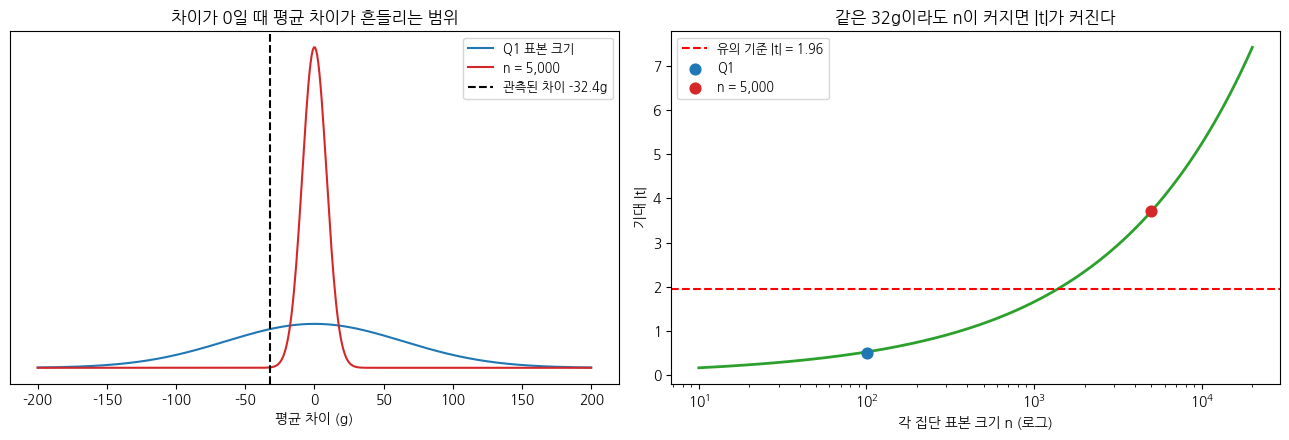

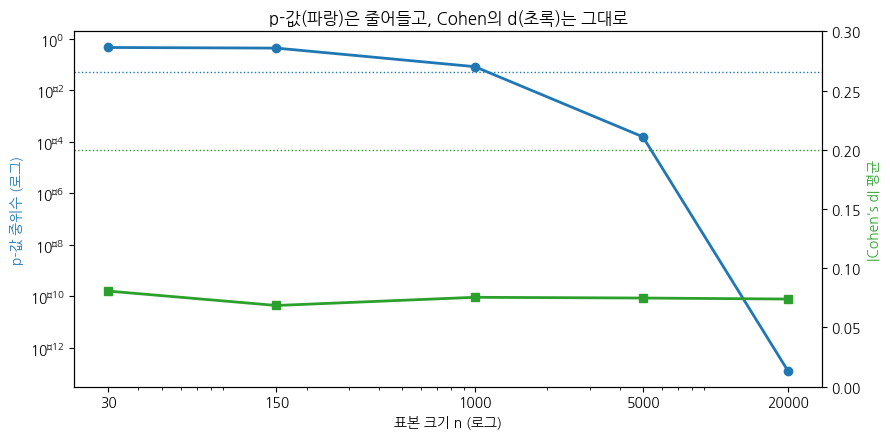

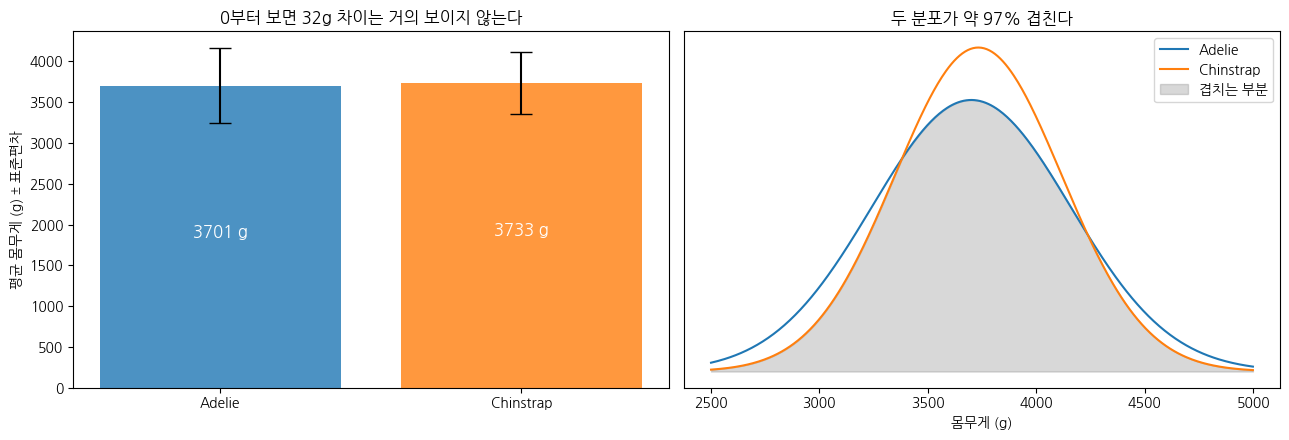

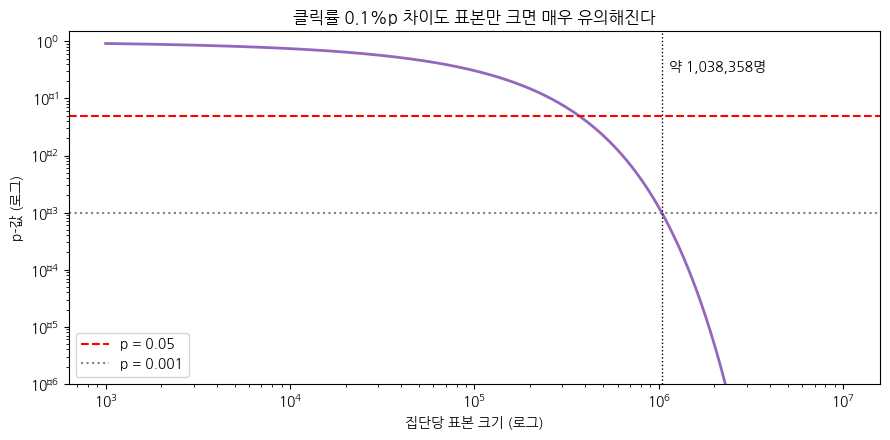

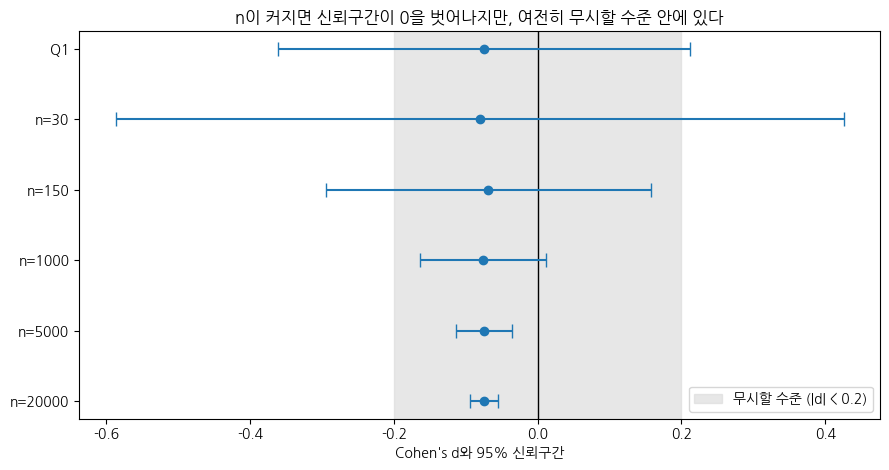

In [5]:
# 💬 정리 · 결과를 말로 설명해 보기 (①~⑤ 통합)
# 실행 방법 (노트북 셀에서):  %run -i summary_answers.py
# Q1~Q3 코드가 먼저 실행되어 adelie, chinstrap, df 가 있어야 합니다.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import stats

# ---------- 공통 준비 ----------
installed = {f.name for f in fm.fontManager.ttflist}
found = None
for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'NanumBarunGothic']:
    if f in installed:
        found = f
        break
if found:
    plt.rc('font', family=found)
    plt.rcParams['axes.unicode_minus'] = False

def T(ko, en):
    if found:
        return ko
    return en

nA, nB = len(adelie), len(chinstrap)
mA, mB = np.mean(adelie), np.mean(chinstrap)
sdA, sdB = np.std(adelie, ddof=1), np.std(chinstrap, ddof=1)
diff = mA - mB
s = np.sqrt(((nA-1)*sdA**2 + (nB-1)*sdB**2) / (nA + nB - 2))
d_real = diff / s

se_q1 = s * np.sqrt(1/nA + 1/nB)
t_q1 = diff / se_q1
p_q1 = stats.ttest_ind(adelie, chinstrap).pvalue
se_5k = s * np.sqrt(2/5000)
t_5k = diff / se_5k
p_5k = 2 * stats.t.sf(abs(t_5k), 5000 + 5000 - 2)
ns = df['n'].values


# ==================== ① ====================
print("=" * 64)
print(" ① 같은 32g인데 Q1과 Q3(n=5,000)의 결론이 갈린 이유는?")
print("=" * 64)
print("▸t-통계량 = 평균 차이 / 표준오차,  표준오차 = s × √(1/nA + 1/nB)")
print("▸평균 차이(분자)는 그대로지만, n이 커지면 표준오차(분모)가 작아진다")
print("   구분            n(각 집단)    표준오차     t        p-값")
print("   Q1 실제 데이터   %d / %d     %6.1f g   %6.2f   %.4f" % (nA, nB, se_q1, t_q1, p_q1))
print("   Q3 n=5,000      5000 / 5000  %6.1f g   %6.2f   %.6f" % (se_5k, t_5k, p_5k))
print("▸답: 차이(32g)가 달라진 게 아니라 '측정의 정밀도'가 달라졌기 때문이다.")
print("   Q1은 표준오차가 약 %.0fg → 32g은 우연한 흔들림과 구분되지 않았다." % se_q1)
print("   n=5,000은 표준오차가 약 %.0fg → 32g이 우연으로 보기 어려운 크기가 됐다." % se_5k)
print("   즉 p-값은 '차이의 크기'와 '표본 크기'를 함께 반영하므로 결론이 갈렸다.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
xs = np.linspace(-200, 200, 500)
axes[0].plot(xs, stats.norm.pdf(xs, 0, se_q1), color='C0', label=T('Q1 표본 크기', 'Q1 sample size'))
axes[0].plot(xs, stats.norm.pdf(xs, 0, se_5k), color='C3', label='n = 5,000')
axes[0].axvline(diff, color='black', linestyle='--', label=T('관측된 차이 %.1fg' % diff, 'observed %.1fg' % diff))
axes[0].set_xlabel(T('평균 차이 (g)', 'Mean difference (g)'))
axes[0].set_yticks([])
axes[0].set_title(T('차이가 0일 때 평균 차이가 흔들리는 범위', 'Spread of mean difference if true diff = 0'))
axes[0].legend(fontsize=9)
n_grid = np.logspace(1, np.log10(20000), 200)
axes[1].plot(n_grid, abs(diff) / (s * np.sqrt(2 / n_grid)), color='C2', linewidth=2)
axes[1].axhline(1.96, color='red', linestyle='--', label=T('유의 기준 |t| = 1.96', 'significance |t| = 1.96'))
axes[1].scatter([np.sqrt(nA*nB)], [abs(t_q1)], color='C0', s=60, zorder=3, label='Q1')
axes[1].scatter([5000], [abs(t_5k)], color='C3', s=60, zorder=3, label='n = 5,000')
axes[1].set_xscale('log')
axes[1].set_xlabel(T('각 집단 표본 크기 n (로그)', 'Sample size per group (log)'))
axes[1].set_ylabel(T('기대 |t|', 'Expected |t|'))
axes[1].set_title(T('같은 32g이라도 n이 커지면 |t|가 커진다', 'Same 32g, larger n gives larger |t|'))
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()


# ==================== ② ====================
print("=" * 64)
print(" ② n이 커질 때 p-값은? Cohen's d는? 이 대비가 뜻하는 바는?")
print("=" * 64)
print(df[['n', 'p_median', 'd_mean']].to_string(index=False))
print("▸p-값: 중위수가 %.3f → %.1e 로, n이 커질수록 0을 향해 급격히 작아졌다"
      % (df['p_median'].iloc[0], df['p_median'].iloc[-1]))
print("▸Cohen's d: n과 상관없이 약 %.3f 근처에 거의 그대로 머물렀다" % df['d_mean'].mean())
print("▸한 문장 정리: p-값은 표본만 늘리면 얼마든지 작아지지만 Cohen's d는 변하지 않으므로,")
print("   p-값은 '차이가 있는가'를, Cohen's d는 '차이가 얼마나 큰가'를 알려준다.")

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(ns, df['p_median'], marker='o', color='C0', linewidth=2)
ax1.axhline(0.05, color='C0', linestyle=':', linewidth=1)
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xticks(ns)
ax1.set_xticklabels([str(n) for n in ns])
ax1.set_xlabel(T('표본 크기 n (로그)', 'Sample size n (log)'))
ax1.set_ylabel(T('p-값 중위수 (로그)', 'Median p (log)'), color='C0')
ax2 = ax1.twinx()
ax2.plot(ns, df['d_mean'].abs(), marker='s', color='C2', linewidth=2)
ax2.axhline(0.2, color='C2', linestyle=':', linewidth=1)
ax2.set_ylim(0, 0.3)
ax2.set_ylabel(T("|Cohen's d| 평균", "Mean |d|"), color='C2')
ax1.set_title(T('p-값(파랑)은 줄어들고, Cohen의 d(초록)는 그대로', 'p (blue) shrinks, d (green) stays'))
plt.tight_layout()
plt.show()


# ==================== ③ ====================
rel = abs(diff) / mA * 100
ovl = 2 * stats.norm.cdf(-abs(d_real) / 2) * 100
print("=" * 64)
print(" ③ '통계적으로 유의하다' = '실질적으로 의미 있다'?  (펭귄 32g 예시)")
print("=" * 64)
print("▸답: 같은 말이 아니다. 둘은 서로 다른 질문에 대한 답이다.")
print("   ▸통계적 유의성: 차이가 0이 아니라고 볼 근거가 있는가 (표본 크기에 좌우됨)")
print("   ▸실질적 의미: 그 차이가 현실에서 중요할 만큼 큰가 (효과크기와 맥락으로 판단)")
print("▸펭귄 32g 예시")
print("   ▸32g은 Adelie 평균 몸무게(%.0fg)의 약 %.1f%%에 불과하다" % (mA, rel))
print("   ▸Cohen's d ≈ %.3f로 '작음(0.2)'에도 못 미치고, 두 분포가 약 %.0f%% 겹친다" % (d_real, ovl))
print("   ▸n=5,000으로 재면 '유의'하게 나오지만, 몸무게로 두 종을 구분하거나")
print("     생태적으로 의미 있는 차이라고 보기는 어렵다")
print("▸결론: 유의하지만 실질적 의미는 거의 없는 차이다")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(['Adelie', 'Chinstrap'], [mA, mB], yerr=[sdA, sdB], capsize=8, color=['C0', 'C1'], alpha=0.8)
axes[0].text(0, mA / 2, '%.0f g' % mA, ha='center', color='white', fontsize=12)
axes[0].text(1, mB / 2, '%.0f g' % mB, ha='center', color='white', fontsize=12)
axes[0].set_ylabel(T('평균 몸무게 (g) ± 표준편차', 'Mean mass (g) ± SD'))
axes[0].set_title(T('0부터 보면 32g 차이는 거의 보이지 않는다', 'From zero, 32g is barely visible'))
xs = np.linspace(2500, 5000, 400)
pa = stats.norm.pdf(xs, mA, sdA)
pc = stats.norm.pdf(xs, mB, sdB)
axes[1].plot(xs, pa, color='C0', label='Adelie')
axes[1].plot(xs, pc, color='C1', label='Chinstrap')
axes[1].fill_between(xs, np.minimum(pa, pc), color='gray', alpha=0.3, label=T('겹치는 부분', 'overlap'))
axes[1].set_xlabel(T('몸무게 (g)', 'Body mass (g)'))
axes[1].set_yticks([])
axes[1].set_title(T('두 분포가 약 %.0f%% 겹친다' % ovl, 'Distributions overlap ~%.0f%%' % ovl))
axes[1].legend()
plt.tight_layout()
plt.show()


# ==================== ④ ====================
base = 0.05          # 가정: 기존 클릭률 5%
new = base + 0.001   # 0.1%p 상승
pbar = (base + new) / 2
n_needed = 2 * pbar * (1 - pbar) * (stats.norm.isf(0.001 / 2) / (new - base))**2
h = 2 * np.arcsin(np.sqrt(new)) - 2 * np.arcsin(np.sqrt(base))
print("=" * 64)
print(" ④ 클릭률 0.1%p 상승, p = 0.001 → 이것만으로 버튼을 바꿔야 할까?")
print("=" * 64)
print("▸내 의견: 이 결과만으로는 바꿔야 한다고 말할 수 없다.")
print("▸이유 1: p = 0.001은 '차이가 0은 아닐 것'이라는 뜻일 뿐, 차이가 크다는 뜻이 아니다")
print("▸이유 2: 효과크기가 매우 작다 (기존 클릭률 5%로 가정)")
print("   ▸5.0%% → 5.1%%, 상대적으로 약 %.0f%% 개선" % ((new - base) / base * 100))
print("   ▸비율용 효과크기 Cohen's h ≈ %.4f → '작음(0.2)'에 한참 못 미침" % h)
print("▸이유 3: p = 0.001이 나오려면 집단당 약 %s명이 필요 → 표본이 커서 유의해졌을 뿐"
      % format(int(n_needed), ','))
print("▸함께 따져볼 것")
print("   ▸0.1%p가 매출·전환에서 실제로 얼마의 가치인지, 바꾸는 비용은 얼마인지")
print("   ▸신뢰구간: 실제 상승폭이 0.02%p일 수도, 0.2%p일 수도 있는지")
print("   ▸여러 색을 동시에 시험했는지(다중 비교), 새로움 효과로 잠깐 오른 건 아닌지")
print("▸결론: 유의성은 출발점일 뿐, 효과크기·신뢰구간·비용 대비 효과를 보고 결정해야 한다")

n_grid2 = np.logspace(3, 7, 200)
p_grid2 = 2 * stats.norm.sf((new - base) / np.sqrt(2 * pbar * (1 - pbar) / n_grid2))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(n_grid2, p_grid2, color='C4', linewidth=2)
ax.axhline(0.05, color='red', linestyle='--', label='p = 0.05')
ax.axhline(0.001, color='gray', linestyle=':', label='p = 0.001')
ax.axvline(n_needed, color='black', linestyle=':', linewidth=1)
ax.text(n_needed * 1.1, 0.3, T('약 %s명' % format(int(n_needed), ','), '~%s' % format(int(n_needed), ',')), fontsize=10)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-6, 1.5)
ax.set_xlabel(T('집단당 표본 크기 (로그)', 'Sample size per group (log)'))
ax.set_ylabel(T('p-값 (로그)', 'p-value (log)'))
ax.set_title(T('클릭률 0.1%p 차이도 표본만 크면 매우 유의해진다', '0.1pp lift becomes highly significant with large n'))
ax.legend()
plt.tight_layout()
plt.show()


# ==================== ⑤ ====================
print("=" * 64)
print(" ⑤ 논문·보고서에 p-값만 적는 것이 왜 부족한가? 무엇을 함께 적어야 하나?")
print("=" * 64)
print("▸p-값은 '차이가 0이 아니라고 볼 근거'만 알려줄 뿐")
print("   ▸차이가 얼마나 큰지, 어느 방향인지, 얼마나 정확한지는 알려주지 않는다")
print("   ▸표본 크기에 따라 같은 차이도 유의/비유의가 바뀐다 (Q1 vs Q3)")
print("▸함께 적어야 할 것")
print("   ▸기술통계: 각 집단의 표본 수, 평균, 표준편차")
print("   ▸효과크기: Cohen's d 등 차이의 크기")
print("   ▸신뢰구간: 효과크기(또는 평균 차이)가 어느 범위에 있을지")
print("   ▸검정 방법과 가정: 어떤 t-검정인지(등분산 가정 여부 등)")
print("▸예시 문장")
print("   Adelie(n=%d, M=%.1f, SD=%.1f)와 Chinstrap(n=%d, M=%.1f, SD=%.1f)의 몸무게는"
      % (nA, mA, sdA, nB, mB, sdB))
print("   유의한 차이가 없었다, t = %.2f, p = %.3f, d = %.2f." % (t_q1, p_q1, d_real))

labels = ['Q1']
d_vals = [d_real]
se_vals = [np.sqrt((nA + nB) / (nA * nB) + d_real**2 / (2 * (nA + nB)))]
for i in range(len(df)):
    n = int(df['n'].iloc[i])
    dm = df['d_mean'].iloc[i]
    labels.append('n=%d' % n)
    d_vals.append(dm)
    se_vals.append(np.sqrt(2 / n + dm**2 / (4 * n)))
ci = 1.96 * np.array(se_vals)
ypos = np.arange(len(labels))[::-1]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.axvspan(-0.2, 0.2, color='#dddddd', alpha=0.7, label=T('무시할 수준 (|d| < 0.2)', 'negligible (|d| < 0.2)'))
ax.axvline(0, color='black', linewidth=1)
ax.errorbar(d_vals, ypos, xerr=ci, fmt='o', color='C0', capsize=5)
ax.set_yticks(ypos)
ax.set_yticklabels(labels)
ax.set_xlabel(T("Cohen's d와 95% 신뢰구간", "Cohen's d with 95% CI"))
ax.set_title(T('n이 커지면 신뢰구간이 0을 벗어나지만, 여전히 무시할 수준 안에 있다',
               'With large n the CI excludes 0 but stays in the negligible zone'))
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 문제 2 · 그럼 몇 마리를 재야 할까?

`난이도 중` · `예상 25분`

**📖 상황**

- 문제 1은 "n을 늘리면 유의해진다"를 보여줬습니다. 뒤집어 읽으면 무서운 말입니다 —
  **n이 모자라면 진짜 있는 차이도 놓친다.**

- 진짜 차이가 있는데 놓치는 잘못을 **제2종 오류(β)**라 하고, 놓치지 않을 확률 **1 − β**를
  **검정력(Power)**이라 부릅니다. 관례적으로 80%를 목표로 삼습니다.

- 강의 9장은 이렇게 못박습니다 — _"미리 검출하고자 하는 효과크기를 정하고, 설정한 𝛼와 𝛽에 따라
  필요한 표본크기 𝓃을 결정해야 합니다."_

- 이번 문제는 그 계산을 **직접** 해 봅니다. 실험을 **시작하기 전에** 하는 계산입니다.

**🎯 이 문제로 배우는 것**

- 제1종·제2종 오류를 구분하고, **효과크기 → 필요 표본수**를 산출하는 검정력 분석을 익힙니다.
  문제 1의 시뮬레이션 결과가 이론값과 맞는지도 확인합니다.

In [6]:
# 문제 2 · 데이터 준비 — 실행만 하세요
# 문제 1의 Q2·Q3를 먼저 완료해야 이 문제를 풀 수 있습니다.

analysis = TTestIndPower()   # 검정력 분석 도구

print("검정력 분석에 쓰이는 네 개의 값")
print("  ① 유의수준 alpha  — 제1종 오류를 허용하는 한계 (보통 0.05)")
print("  ② 검정력 power    — 1 - beta, 진짜 차이를 잡아낼 확률 (보통 0.80)")
print("  ③ 효과크기 d      — 검출하고자 하는 차이의 크기")
print("  ④ 표본크기 nobs1  — 집단당 표본 수")
print("\n→ 이 중 셋을 정하면 나머지 하나가 결정됩니다.")

검정력 분석에 쓰이는 네 개의 값
  ① 유의수준 alpha  — 제1종 오류를 허용하는 한계 (보통 0.05)
  ② 검정력 power    — 1 - beta, 진짜 차이를 잡아낼 확률 (보통 0.80)
  ③ 효과크기 d      — 검출하고자 하는 차이의 크기
  ④ 표본크기 nobs1  — 집단당 표본 수

→ 이 중 셋을 정하면 나머지 하나가 결정됩니다.


### Q1 · 두 가지 오류를 표로 정리해 봅시다

- 강의 9장의 신약 예시를 씁니다. **H₀: "신약은 효과가 없다"**

- 아래 네 칸을 채우세요. 각 칸에 **오류의 이름**과 **무엇을 잃는가**를 함께 적으세요.

- 코드가 아니라 **말로** 채우는 문제입니다.

[기본 개념]
▸H0: 효과가 없다 / H1: 효과가 있다
▸α: H0가 참인데 기각할 확률 (보통 0.05)
▸β: 진짜 효과가 있는데 놓칠 확률
▸검정력 1-β: 진짜 효과를 찾아낼 확률 (보통 80% 목표)
▸α를 낮추면 β가 커지고, n을 늘리면 β가 줄어든다

[판단 결과 표]
+----------------+-----------------------+--------------------------+
|                | H0 기각함 (효과 있다) | H0 기각 못함 (효과 없다) |
+----------------+-----------------------+--------------------------+
| 실제 효과 없음 | 제1종 오류 (α)        | 올바른 결론 (1-α)        |
| 실제 효과 있음 | 검정력 (1-β)          | 제2종 오류 (β)           |
+----------------+-----------------------+--------------------------+

[질문 답]
▸제1종 오류(α)를 범하면 무엇을 잃나요?
   없는 효과를 있다고 결론 내려, 효과 없는 약·정책에 돈과 시간을 쓰고 신뢰를 잃는다.
▸제2종 오류(β)를 범하면 무엇을 잃나요?
   있는 효과를 놓쳐, 좋은 약·정책을 버리고 실험에 들인 노력이 헛수고가 된다.
▸검정력(1-β)을 한 문장으로 정의하면?
   실제로 효과가 있을 때 귀무가설을 올바르게 기각해 그 효과를 찾아낼 확률이다.

▸그래프 2 해석: d=0.5, 집단당 30마리면 검정력 0.49, β 0.51
   → 진짜 효과가 있어도 약 절반은 놓친다. n을 늘리면 H1 분포가 오른쪽으로 가서 검정력이 커진다.


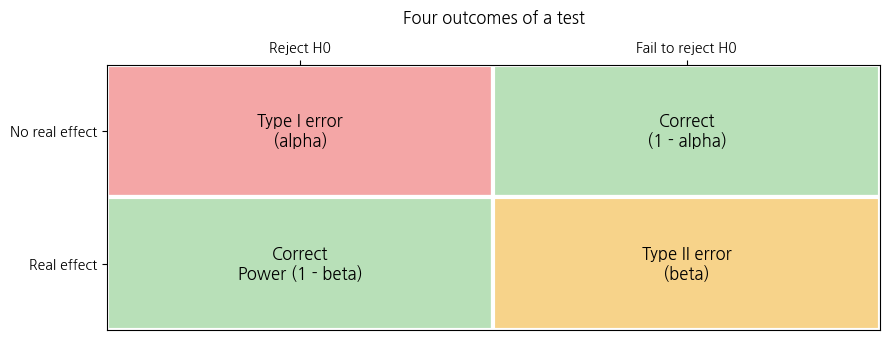

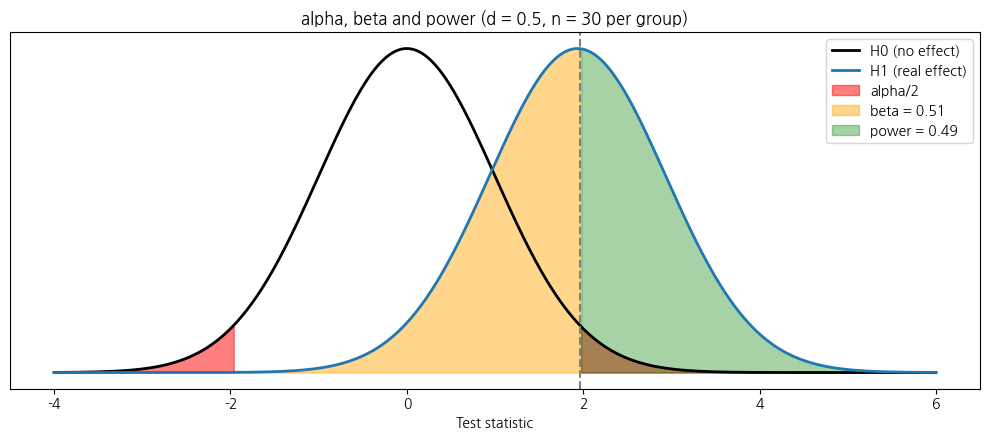

In [7]:
# 문제 2 · Q1 · 제1종 오류, 제2종 오류, 검정력
import numpy as np
import unicodedata
import matplotlib.pyplot as plt
from scipy import stats

print("[기본 개념]")
print("▸H0: 효과가 없다 / H1: 효과가 있다")
print("▸α: H0가 참인데 기각할 확률 (보통 0.05)")
print("▸β: 진짜 효과가 있는데 놓칠 확률")
print("▸검정력 1-β: 진짜 효과를 찾아낼 확률 (보통 80% 목표)")
print("▸α를 낮추면 β가 커지고, n을 늘리면 β가 줄어든다\n")

# 판단 결과 표 (한글 폭을 계산해 칸을 맞춘 텍스트 표)
def width(s):
    return sum(2 if unicodedata.east_asian_width(c) in 'WF' else 1 for c in s)

def pad(s, w):
    return s + ' ' * (w - width(s))

header = ["", "H0 기각함 (효과 있다)", "H0 기각 못함 (효과 없다)"]
body = [["실제 효과 없음", "제1종 오류 (α)", "올바른 결론 (1-α)"],
        ["실제 효과 있음", "검정력 (1-β)", "제2종 오류 (β)"]]
W = [max(width(r[k]) for r in [header] + body) + 2 for k in range(3)]
line = "+" + "+".join("-" * w for w in W) + "+"

print("[판단 결과 표]")
print(line)
print("|" + "|".join(pad(" " + header[k], W[k]) for k in range(3)) + "|")
print(line)
for r in body:
    print("|" + "|".join(pad(" " + r[k], W[k]) for k in range(3)) + "|")
print(line)

print("\n[질문 답]")
print("▸제1종 오류(α)를 범하면 무엇을 잃나요?")
print("   없는 효과를 있다고 결론 내려, 효과 없는 약·정책에 돈과 시간을 쓰고 신뢰를 잃는다.")
print("▸제2종 오류(β)를 범하면 무엇을 잃나요?")
print("   있는 효과를 놓쳐, 좋은 약·정책을 버리고 실험에 들인 노력이 헛수고가 된다.")
print("▸검정력(1-β)을 한 문장으로 정의하면?")
print("   실제로 효과가 있을 때 귀무가설을 올바르게 기각해 그 효과를 찾아낼 확률이다.\n")

# 그래프 1: 판단 결과 4가지
fig, ax = plt.subplots(figsize=(9, 3.5))
txt = [['Type I error\n(alpha)', 'Correct\n(1 - alpha)'],
       ['Correct\nPower (1 - beta)', 'Type II error\n(beta)']]
col = [['#f4a6a6', '#b8e0b8'], ['#b8e0b8', '#f7d38a']]
for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, facecolor=col[i][j], edgecolor='white', lw=3))
        ax.text(j + 0.5, 1.5 - i, txt[i][j], ha='center', va='center', fontsize=12)
ax.set_xlim(0, 2)
ax.set_ylim(0, 2)
ax.set_xticks([0.5, 1.5])
ax.set_xticklabels(['Reject H0', 'Fail to reject H0'])
ax.set_yticks([1.5, 0.5])
ax.set_yticklabels(['No real effect', 'Real effect'])
ax.xaxis.tick_top()
ax.set_title('Four outcomes of a test', pad=30)
plt.tight_layout()
plt.show()

# 그래프 2: alpha, beta, power (예시 d=0.5, 집단당 n=30)
alpha, d, n = 0.05, 0.5, 30
shift = d * np.sqrt(n / 2)
crit = stats.norm.isf(alpha / 2)
power = stats.norm.sf(crit - shift)
beta = 1 - power
z = np.linspace(-4, 6, 600)
h0 = stats.norm.pdf(z)
h1 = stats.norm.pdf(z, shift)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(z, h0, 'k', lw=2, label='H0 (no effect)')
ax.plot(z, h1, 'C0', lw=2, label='H1 (real effect)')
ax.fill_between(z, h0, where=z >= crit, color='red', alpha=0.5, label='alpha/2')
ax.fill_between(z, h0, where=z <= -crit, color='red', alpha=0.5)
ax.fill_between(z, h1, where=z < crit, color='orange', alpha=0.45, label='beta = %.2f' % beta)
ax.fill_between(z, h1, where=z >= crit, color='green', alpha=0.35, label='power = %.2f' % power)
ax.axvline(crit, color='gray', ls='--')
ax.set_yticks([])
ax.set_xlabel('Test statistic')
ax.set_title('alpha, beta and power (d = 0.5, n = 30 per group)')
ax.legend()
plt.tight_layout()
plt.show()

print("▸그래프 2 해석: d=0.5, 집단당 30마리면 검정력 %.2f, β %.2f" % (power, beta))
print("   → 진짜 효과가 있어도 약 절반은 놓친다. n을 늘리면 H1 분포가 오른쪽으로 가서 검정력이 커진다.")

### Q2 · 문제 1의 시뮬레이션이 이론과 맞는지 확인해 봅시다

- 문제 1에서 구한 펭귄의 효과크기(d ≈ 0.074)에 대해, `n = 30, 150, 1000, 5000, 20000`
  각각의 **이론적 검정력**을 계산하세요.

- 이 값을 문제 1 Q3의 **'p < 0.05 비율'과 나란히 출력**해 두 값이 일치하는지 눈으로 확인하세요.

- `💡 힌트` `analysis.power(effect_size=..., nobs1=..., alpha=0.05, ratio=1)`
  — `effect_size`에는 효과크기의 **절대값**을 넣습니다.

 1) 이론적 검정력 계산
▸검정력: 진짜 효과가 있을 때 t-검정이 p < 0.05를 내서 그 효과를 찾아낼 확률
▸공식(근사):  검정력 ≈ Φ( d·√(n/2) − 1.96 )
   d·√(n/2): n마리씩 뽑았을 때 예상되는 t값 / 1.96: 유의 기준 / Φ: 표준정규 누적확률
▸코드: analysis.power(effect_size=|d|, nobs1=n, alpha=0.05, ratio=1)  (정확한 비중심 t 사용)
▸펭귄의 |d| = 0.0742

    n    예상 t   이론 검정력
    30     0.29         5.9%
   150     0.64         9.8%
  1000     1.66        38.2%
  5000     3.71        96.0%
 20000     7.42       100.0%
→ 예상 t가 1.96에 가까워질수록 검정력이 50%에 가까워지고, 넘어서면 100%로 올라간다

 2) 이론 vs 문제 1 Q3 시뮬레이션 ('p < 0.05 비율')
▸시뮬레이션 = 400번 중 p < 0.05가 나온 횟수 / 400 × 100
▸오차범위 = 1.96 × √(검정력 × (1 − 검정력) / 400)  ← 400번만 반복해서 생기는 우연한 흔들림

    n   이론(%)   시뮬레이션(%)   차이(%p)   오차범위(±%p)   일치?
    30      5.9         5.8         -0.2          2.3          O
   150      9.8         9.5         -0.3          2.9          O
  1000     38.2        39.2         +1.1          4.8          O
  5000     96.0        95.5         -0.5          1.9          O
 20000    100.0       100.0         +0.0         

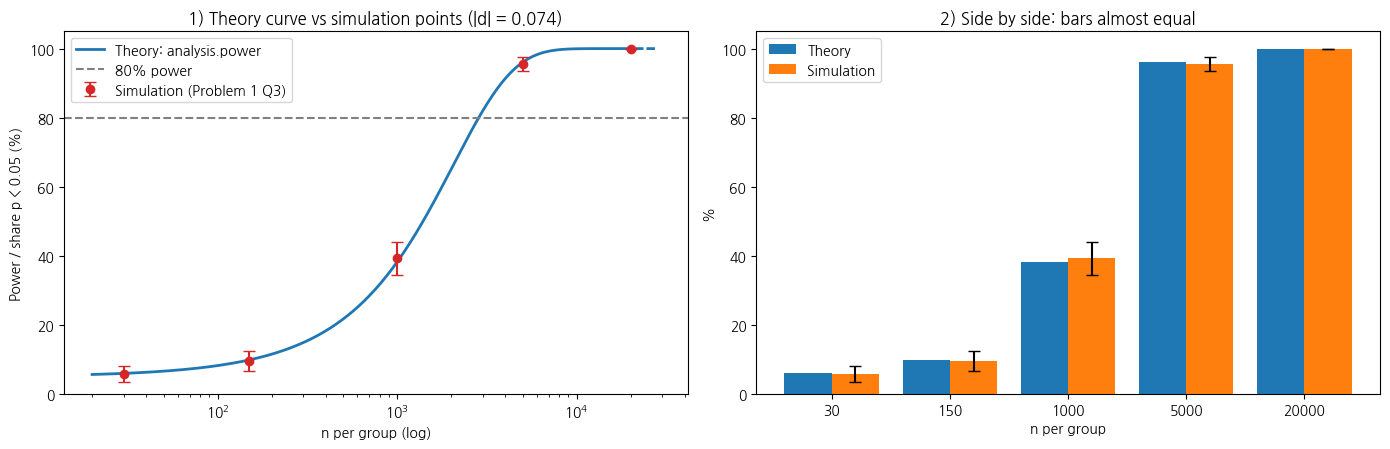

In [20]:
# 문제 2 · Q2 · 문제 1의 시뮬레이션이 이론과 맞는지 확인
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import TTestIndPower

analysis = TTestIndPower()
nA, nB = len(adelie), len(chinstrap)
s = np.sqrt(((nA-1)*np.var(adelie, ddof=1) + (nB-1)*np.var(chinstrap, ddof=1)) / (nA+nB-2))
d_abs = abs(np.mean(adelie) - np.mean(chinstrap)) / s
ns = [30, 150, 1000, 5000, 20000]

# ---------- 1) 이론적 검정력 ----------
print("=" * 64)
print(" 1) 이론적 검정력 계산")
print("=" * 64)
print("▸검정력: 진짜 효과가 있을 때 t-검정이 p < 0.05를 내서 그 효과를 찾아낼 확률")
print("▸공식(근사):  검정력 ≈ Φ( d·√(n/2) − 1.96 )")
print("   d·√(n/2): n마리씩 뽑았을 때 예상되는 t값 / 1.96: 유의 기준 / Φ: 표준정규 누적확률")
print("▸코드: analysis.power(effect_size=|d|, nobs1=n, alpha=0.05, ratio=1)  (정확한 비중심 t 사용)")
print("▸펭귄의 |d| = %.4f\n" % d_abs)

theory = [analysis.power(effect_size=d_abs, nobs1=n, alpha=0.05, ratio=1) * 100 for n in ns]
exp_t = [d_abs * np.sqrt(n / 2) for n in ns]
print("    n    예상 t   이론 검정력")
for n, t, p in zip(ns, exp_t, theory):
    print("%6d   %6.2f      %6.1f%%" % (n, t, p))
print("→ 예상 t가 1.96에 가까워질수록 검정력이 50%에 가까워지고, 넘어서면 100%로 올라간다\n")

# ---------- 2) 문제 1 Q3 시뮬레이션과 나란히 ----------
sim = [float(df.loc[df['n'] == n, 'sig_pct'].iloc[0]) for n in ns]
err = [1.96 * np.sqrt(p/100 * (1 - p/100) / 400) * 100 for p in theory]
print("=" * 64)
print(" 2) 이론 vs 문제 1 Q3 시뮬레이션 ('p < 0.05 비율')")
print("=" * 64)
print("▸시뮬레이션 = 400번 중 p < 0.05가 나온 횟수 / 400 × 100")
print("▸오차범위 = 1.96 × √(검정력 × (1 − 검정력) / 400)  ← 400번만 반복해서 생기는 우연한 흔들림")
print()
print("    n   이론(%)   시뮬레이션(%)   차이(%p)   오차범위(±%p)   일치?")
for n, t, m, e in zip(ns, theory, sim, err):
    ok = "O" if abs(m - t) <= e else "X"
    print("%6d   %6.1f      %6.1f       %+6.1f        %5.1f          %s" % (n, t, m, m - t, e, ok))
print("\n▸결론: 다섯 n 모두 차이가 오차범위 안이면, 시뮬레이션이 이론과 일치한다는 뜻")
print("   → 문제 1에서 n을 늘릴수록 유의 비율이 오른 것은 우연이 아니라 검정력이 커졌기 때문이다")

# ---------- 그래프 ----------
grid = np.logspace(np.log10(20), np.log10(30000), 200)
curve = [analysis.power(effect_size=d_abs, nobs1=g, alpha=0.05, ratio=1) * 100 for g in grid]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))

ax[0].plot(grid, curve, 'C0', lw=2, label='Theory: analysis.power')
ax[0].errorbar(ns, sim, yerr=err, fmt='o', color='C3', capsize=4, label='Simulation (Problem 1 Q3)')
ax[0].axhline(80, color='gray', ls='--', label='80% power')
ax[0].set_xscale('log'); ax[0].set_ylim(0, 105)
ax[0].set_xlabel('n per group (log)'); ax[0].set_ylabel('Power / share p < 0.05 (%)')
ax[0].set_title('1) Theory curve vs simulation points (|d| = %.3f)' % d_abs); ax[0].legend()

x = np.arange(len(ns))
ax[1].bar(x - 0.2, theory, 0.4, label='Theory')
ax[1].bar(x + 0.2, sim, 0.4, yerr=err, capsize=4, label='Simulation')
ax[1].set_xticks(x); ax[1].set_xticklabels([str(n) for n in ns])
ax[1].set_xlabel('n per group'); ax[1].set_ylabel('%')
ax[1].set_title('2) Side by side: bars almost equal'); ax[1].legend()

plt.tight_layout()
plt.show()

print("▸그래프 1: 파란 곡선(이론) 위에 빨간 점(시뮬레이션)이 올라가 있으면 일치")
print("▸그래프 2: n마다 이론(파랑)과 시뮬레이션(주황) 막대 높이가 거의 같으면 일치")

 검정력(Power) 공식
▸검정력 = 진짜 효과가 있을 때, t-검정이 p < α를 내서 그 효과를 찾아낼 확률 (= 1 − β)
▸재료 3가지: 효과크기 d, 종마다 표본 수 n, 유의수준 α

▸공식:  검정력 ≈ Φ( d·√(n/2) − z ) + Φ( −d·√(n/2) − z )
   ▸d·√(n/2) : 예상 t값(δ). 진짜 차이가 d일 때 t-통계량이 평균적으로 놓이는 위치
               n이 커질수록 √n에 비례해 커진다
   ▸z        : 유의 기준선. α = 0.05(양측)이면 z = 1.96
               표준정규분포에서 가운데 95%를 감싸는 경계 (α를 바꾸면 이 값이 바뀜)
   ▸Φ( )     : 표준정규 누적확률. '예상 t값이 기준선을 얼마나 넘는가'를 확률로 바꿈
   ▸둘째 항  : 반대쪽 기준선(−z) 밖으로 나갈 확률. 양측검정이라 더함 (δ가 작을 때만 의미 있음)

▸원리: 진짜 차이가 d면 t-통계량은 δ = d·√(n/2)를 중심으로 흩어진다(표준편차 약 1)
       이 t가 기준선 z를 넘을 확률 = P(t > z) = Φ(δ − z) = 검정력
       δ = z 이면 약 50%, δ가 z보다 0.84 크면 약 80%, 2.3 크면 약 99%

▸손계산 예시 (n = 1000)
   δ = 0.0742 × √(1000/2) = 1.66
   검정력 ≈ Φ(1.66 − 1.96) + Φ(−1.66 − 1.96) = 0.382 + 0.000 = 38.2%
▸코드의 analysis.power()는 같은 원리를 t분포(비중심 t)로 정확히 계산한 것

[1) 이론적 검정력]  |d| = 0.0742, α = 0.05
    n   δ=d√(n/2)   δ−1.96   공식 근사(%)   analysis.power(%)
    30      0.29      -1.67         6.0             5.9
   150      0.64      -1.32      

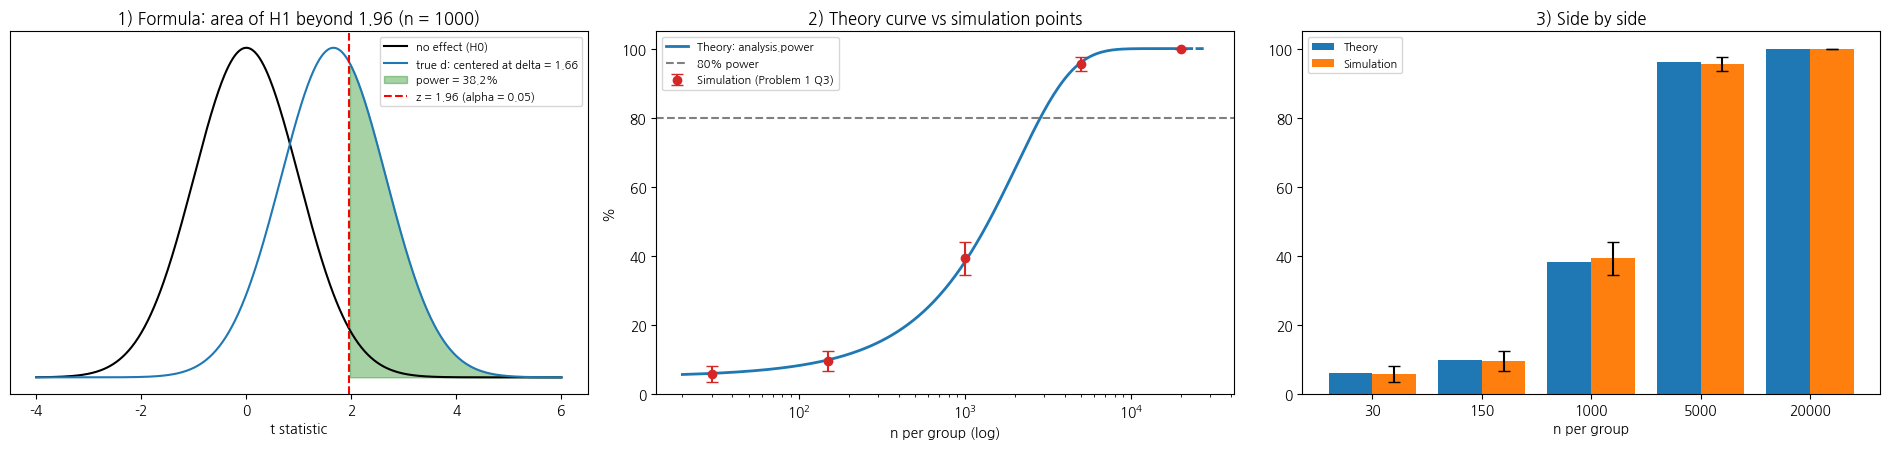

In [21]:
# 문제 2 · Q2 · 문제 1의 시뮬레이션이 이론과 맞는지 확인
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import TTestIndPower

analysis = TTestIndPower()
nA, nB = len(adelie), len(chinstrap)
s = np.sqrt(((nA-1)*np.var(adelie, ddof=1) + (nB-1)*np.var(chinstrap, ddof=1)) / (nA+nB-2))
d_abs = abs(np.mean(adelie) - np.mean(chinstrap)) / s
ns = [30, 150, 1000, 5000, 20000]
z_crit = stats.norm.isf(0.05 / 2)                 # α = 0.05 양측 → 1.96

# ---------- 0) 검정력 공식 설명 ----------
print("=" * 66)
print(" 검정력(Power) 공식")
print("=" * 66)
print("▸검정력 = 진짜 효과가 있을 때, t-검정이 p < α를 내서 그 효과를 찾아낼 확률 (= 1 − β)")
print("▸재료 3가지: 효과크기 d, 종마다 표본 수 n, 유의수준 α")
print()
print("▸공식:  검정력 ≈ Φ( d·√(n/2) − z ) + Φ( −d·√(n/2) − z )")
print("   ▸d·√(n/2) : 예상 t값(δ). 진짜 차이가 d일 때 t-통계량이 평균적으로 놓이는 위치")
print("               n이 커질수록 √n에 비례해 커진다")
print("   ▸z        : 유의 기준선. α = 0.05(양측)이면 z = %.2f" % z_crit)
print("               표준정규분포에서 가운데 95%를 감싸는 경계 (α를 바꾸면 이 값이 바뀜)")
print("   ▸Φ( )     : 표준정규 누적확률. '예상 t값이 기준선을 얼마나 넘는가'를 확률로 바꿈")
print("   ▸둘째 항  : 반대쪽 기준선(−z) 밖으로 나갈 확률. 양측검정이라 더함 (δ가 작을 때만 의미 있음)")
print()
print("▸원리: 진짜 차이가 d면 t-통계량은 δ = d·√(n/2)를 중심으로 흩어진다(표준편차 약 1)")
print("       이 t가 기준선 z를 넘을 확률 = P(t > z) = Φ(δ − z) = 검정력")
print("       δ = z 이면 약 50%, δ가 z보다 0.84 크면 약 80%, 2.3 크면 약 99%")
print()
n_ex = 1000
delta_ex = d_abs * np.sqrt(n_ex / 2)
print("▸손계산 예시 (n = %d)" % n_ex)
print("   δ = %.4f × √(%d/2) = %.2f" % (d_abs, n_ex, delta_ex))
print("   검정력 ≈ Φ(%.2f − %.2f) + Φ(−%.2f − %.2f) = %.3f + %.3f = %.1f%%"
      % (delta_ex, z_crit, delta_ex, z_crit, stats.norm.cdf(delta_ex - z_crit),
         stats.norm.cdf(-delta_ex - z_crit),
         (stats.norm.cdf(delta_ex - z_crit) + stats.norm.cdf(-delta_ex - z_crit)) * 100))
print("▸코드의 analysis.power()는 같은 원리를 t분포(비중심 t)로 정확히 계산한 것")
print("=" * 66 + "\n")

# ---------- 1) 이론적 검정력 ----------
theory = [analysis.power(effect_size=d_abs, nobs1=n, alpha=0.05, ratio=1) * 100 for n in ns]
delta = [d_abs * np.sqrt(n / 2) for n in ns]
approx = [(stats.norm.cdf(dl - z_crit) + stats.norm.cdf(-dl - z_crit)) * 100 for dl in delta]
print("[1) 이론적 검정력]  |d| = %.4f, α = 0.05" % d_abs)
print("    n   δ=d√(n/2)   δ−1.96   공식 근사(%)   analysis.power(%)")
for n, dl, a, t in zip(ns, delta, approx, theory):
    print("%6d    %6.2f     %+6.2f      %6.1f          %6.1f" % (n, dl, dl - z_crit, a, t))
print("→ δ가 1.96보다 작으면 검정력이 낮고, 넘어서면 빠르게 100%로 올라간다\n")

# ---------- 2) 시뮬레이션과 나란히 ----------
sim = [float(df.loc[df['n'] == n, 'sig_pct'].iloc[0]) for n in ns]
err = [1.96 * np.sqrt(p/100 * (1 - p/100) / 400) * 100 for p in theory]
i_ex = ns.index(n_ex)
print("[2) 이론 vs 문제 1 Q3 시뮬레이션]")
print("▸시뮬레이션(400번)으로 구한 것 = '실험으로 구한 검정력'")
print("   검정력은 확률이라 한 번 실험으로는 알 수 없다 → 같은 실험을 400번 반복해 유의한 횟수를 센다")
print("   예) n = %d: 가상 펭귄을 종마다 %d마리씩 뽑아 t-검정 → 400번 중 %d번 p < 0.05"
      % (n_ex, n_ex, round(sim[i_ex] * 4)))
print("       → 시뮬레이션 검정력 = %d / 400 = %.1f%%" % (round(sim[i_ex] * 4), sim[i_ex]))
print()
print("▸아래 표의 '차이'와 '오차범위'는 모두 검정력(유의한 비율)에 대한 숫자다")
print("   ▸차이(%p)     = 시뮬레이션 검정력 − 이론 검정력   → 두 값이 얼마나 어긋났나")
print("   ▸오차범위(±%p) = 1.96 × √(검정력 × (1 − 검정력) / 400)")
print("                   → 400번만 실험해서 우연히 생길 수 있는 흔들림의 폭 (동전을 400번 던지면")
print("                     정확히 50%가 아니라 47~53%쯤 나오는 것과 같은 원리)")
print("   ▸차이의 부호(+ / −)가 뜻하는 것")
print("      + (양수): 시뮬레이션이 이론보다 높게 나옴 → 400번 중 우연히 '조금 더 많이' 유의했다")
print("      − (음수): 시뮬레이션이 이론보다 낮게 나옴 → 400번 중 우연히 '조금 더 적게' 유의했다")
print("      0       : 둘이 정확히 같음 (예: 검정력이 100%면 400번 모두 유의해서 흔들림이 없음)")
print("      → 부호는 '어느 쪽으로 어긋났나'일 뿐, 좋고 나쁨이 아니다. 오차범위 안이면 +든 −든 우연")
print("      → 만약 모든 n에서 한쪽 부호만 크게 나온다면, 우연이 아니라 시뮬레이션이나 공식에 문제가 있다는 신호")
print("   ▸판단: 차이가 오차범위 안이면 '우연한 흔들림일 뿐 → 이론과 일치(O)'")
print("          차이가 오차범위 밖이면 '우연으로 보기엔 너무 다름 → 불일치(X)'")
print("   예) n = %d: 차이 %+.1f%%p, 오차범위 ±%.1f%%p → |%.1f| %s %.1f → %s"
      % (n_ex, sim[i_ex] - theory[i_ex], err[i_ex], sim[i_ex] - theory[i_ex],
         "≤" if abs(sim[i_ex] - theory[i_ex]) <= err[i_ex] else ">", err[i_ex],
         "일치" if abs(sim[i_ex] - theory[i_ex]) <= err[i_ex] else "불일치"))
print()
print("    n   이론(%)   시뮬레이션(%)   차이(%p)   방향            오차범위(±%p)   일치?")
for n, t, m, e in zip(ns, theory, sim, err):
    dd = m - t
    way = "시뮬레이션↑" if dd > 0.05 else ("시뮬레이션↓" if dd < -0.05 else "같음       ")
    print("%6d   %6.1f      %6.1f       %+6.1f     %s       %5.1f          %s"
          % (n, t, m, dd, way, e, "O" if abs(dd) <= e else "X"))
n_pos = sum(1 for t, m in zip(theory, sim) if m - t > 0.05)
n_neg = sum(1 for t, m in zip(theory, sim) if m - t < -0.05)
print("\n▸부호 확인: + %d개, − %d개 → 한쪽으로 쏠리지 않고 섞여 있으면 우연한 흔들림이라는 증거" % (n_pos, n_neg))
print("\n▸결론: 차이가 오차범위 안이면 시뮬레이션이 이론과 일치한다")
print("   → 문제 1에서 n을 늘릴수록 유의 비율이 오른 것은 검정력 공식대로 움직인 결과다")

# ---------- 그래프 ----------
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))

z = np.linspace(-4, 6, 500)
h0, h1 = stats.norm.pdf(z), stats.norm.pdf(z, delta_ex)
ax[0].plot(z, h0, 'k', label='no effect (H0)')
ax[0].plot(z, h1, 'C0', label='true d: centered at delta = %.2f' % delta_ex)
ax[0].fill_between(z, h1, where=z >= z_crit, color='green', alpha=0.35, label='power = %.1f%%' % theory[2])
ax[0].axvline(z_crit, color='red', ls='--', label='z = 1.96 (alpha = 0.05)')
ax[0].set_yticks([]); ax[0].set_xlabel('t statistic')
ax[0].set_title('1) Formula: area of H1 beyond 1.96 (n = %d)' % n_ex); ax[0].legend(fontsize=8)

grid = np.logspace(np.log10(20), np.log10(30000), 200)
curve = [analysis.power(effect_size=d_abs, nobs1=g, alpha=0.05, ratio=1) * 100 for g in grid]
ax[1].plot(grid, curve, 'C0', lw=2, label='Theory: analysis.power')
ax[1].errorbar(ns, sim, yerr=err, fmt='o', color='C3', capsize=4, label='Simulation (Problem 1 Q3)')
ax[1].axhline(80, color='gray', ls='--', label='80% power')
ax[1].set_xscale('log'); ax[1].set_ylim(0, 105)
ax[1].set_xlabel('n per group (log)'); ax[1].set_ylabel('%')
ax[1].set_title('2) Theory curve vs simulation points'); ax[1].legend(fontsize=8)

x = np.arange(len(ns))
ax[2].bar(x - 0.2, theory, 0.4, label='Theory')
ax[2].bar(x + 0.2, sim, 0.4, yerr=err, capsize=4, label='Simulation')
ax[2].set_xticks(x); ax[2].set_xticklabels([str(n) for n in ns])
ax[2].set_xlabel('n per group'); ax[2].set_title('3) Side by side'); ax[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("▸그래프 1: 공식의 그림 버전. 파란 분포(진짜 효과)에서 빨간 기준선 오른쪽 초록 면적이 검정력")
print("▸그래프 2: 파란 곡선(이론) 위에 빨간 점(시뮬레이션)이 올라가 있으면 일치")
print("▸그래프 3: n마다 이론과 시뮬레이션 막대 높이가 거의 같으면 일치")

### Q3 · 80% 검정력에 필요한 표본수를 구해 봅시다

- 유의수준 0.05, 검정력 0.80을 목표로 할 때 **집단당 필요한 표본수**를 구하세요.

- 효과크기 네 가지에 대해 각각 계산해 표로 출력하세요.
  **① 펭귄의 d ≈ 0.074 ② 0.2(작음) ③ 0.5(중간) ④ 0.8(큼)**

- `💡 힌트` `analysis.solve_power(effect_size=..., alpha=0.05, power=0.8)`
  — 사람 수는 소수점이 될 수 없으니 `np.ceil()`로 올림하세요.

[개념]
▸표본수 설계: 실험 전에 효과크기 d, 유의수준 α, 목표 검정력 1-β를 정하고 필요한 n을 역산한다
▸여기서는 α = 0.05, 검정력 = 0.80 (진짜 효과가 있으면 80% 확률로 찾아냄)
▸효과가 작을수록 '신호'가 약하므로 더 많은 표본이 필요하다 (대략 n ∝ 1/d²)

[α = 0.05, 검정력 0.80에 필요한 표본수 (np.ceil로 올림)]
+----------+-------+--------+----------+--------+
| 효과크기 |     d | 계산값 | 집단당 n | 전체 n |
+----------+-------+--------+----------+--------+
|   ① 펭귄 | 0.074 | 2852.0 |    2,852 |  5,704 |
|   ② 작음 | 0.200 |  393.4 |      394 |    788 |
|   ③ 중간 | 0.500 |   63.8 |       64 |    128 |
|     ④ 큼 | 0.800 |   25.5 |       26 |     52 |
+----------+-------+--------+----------+--------+

[해석]
▸큰 효과(0.8)는 집단당 26마리면 충분하지만, 작은 효과(0.2)는 394마리가 필요하다
▸펭귄의 d ≈ 0.074는 집단당 약 2,852마리가 필요하다
   → 실제 데이터(Adelie 151, Chinstrap 68)는 이에 한참 못 미쳐, 문제 1 Q1에서 유의하지 않은 것이 당연하다
▸d가 절반이 되면 필요한 n은 약 4배가 된다 (0.4 → 0.2일 때 100 → 394)


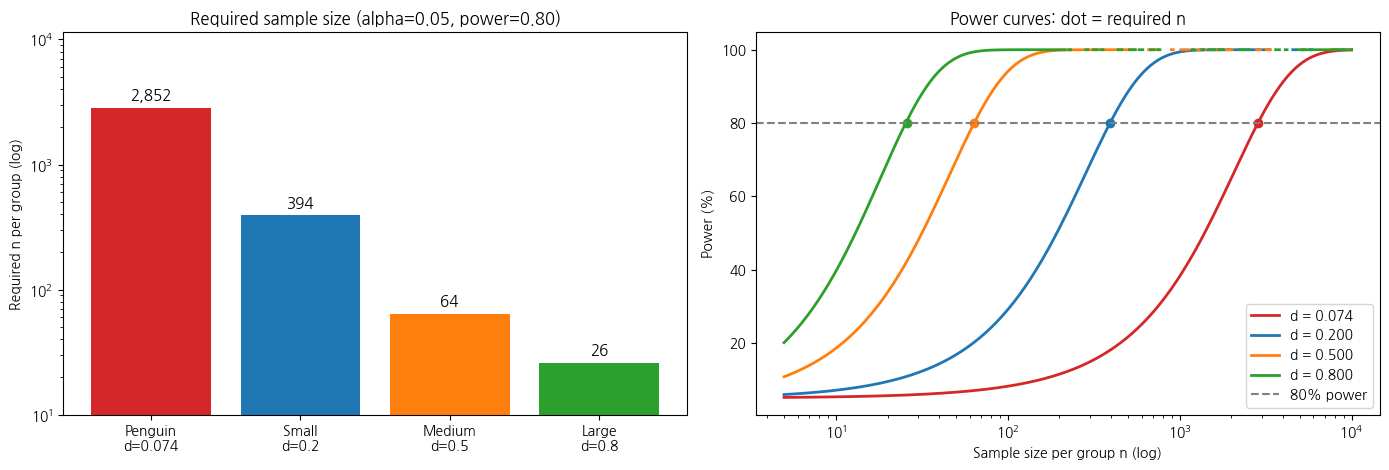

In [8]:
# 문제 2 · Q3 · 80% 검정력에 필요한 표본수
import numpy as np
import unicodedata
import matplotlib.pyplot as plt
from statsmodels.stats.power import TTestIndPower

analysis = TTestIndPower()
d_peng = abs(np.mean(adelie) - np.mean(chinstrap)) / np.sqrt(
    ((len(adelie)-1)*np.var(adelie, ddof=1) + (len(chinstrap)-1)*np.var(chinstrap, ddof=1))
    / (len(adelie) + len(chinstrap) - 2))

print("[개념]")
print("▸표본수 설계: 실험 전에 효과크기 d, 유의수준 α, 목표 검정력 1-β를 정하고 필요한 n을 역산한다")
print("▸여기서는 α = 0.05, 검정력 = 0.80 (진짜 효과가 있으면 80% 확률로 찾아냄)")
print("▸효과가 작을수록 '신호'가 약하므로 더 많은 표본이 필요하다 (대략 n ∝ 1/d²)\n")

names = ["① 펭귄", "② 작음", "③ 중간", "④ 큼"]
ds = [d_peng, 0.2, 0.5, 0.8]
raw = [analysis.solve_power(effect_size=d, alpha=0.05, power=0.8, ratio=1) for d in ds]
need = [int(np.ceil(r)) for r in raw]

def width(s):
    return sum(2 if unicodedata.east_asian_width(c) in 'WF' else 1 for c in s)

def pad(s, w):
    return ' ' * (w - width(s)) + s

head = ["효과크기", "d", "계산값", "집단당 n", "전체 n"]
rows = []
for i in range(4):
    rows.append([names[i], "%.3f" % ds[i], "%.1f" % raw[i], format(need[i], ','), format(need[i] * 2, ',')])
W = [max(width(r[k]) for r in [head] + rows) + 2 for k in range(5)]
line = "+" + "+".join("-" * w for w in W) + "+"
print("[α = 0.05, 검정력 0.80에 필요한 표본수 (np.ceil로 올림)]")
print(line)
print("|" + "|".join(pad(head[k] + " ", W[k]) for k in range(5)) + "|")
print(line)
for r in rows:
    print("|" + "|".join(pad(r[k] + " ", W[k]) for k in range(5)) + "|")
print(line)

print("\n[해석]")
print("▸큰 효과(0.8)는 집단당 %d마리면 충분하지만, 작은 효과(0.2)는 %d마리가 필요하다" % (need[3], need[1]))
print("▸펭귄의 d ≈ %.3f는 집단당 약 %s마리가 필요하다" % (d_peng, format(need[0], ',')))
print("   → 실제 데이터(Adelie %d, Chinstrap %d)는 이에 한참 못 미쳐, 문제 1 Q1에서 유의하지 않은 것이 당연하다"
      % (len(adelie), len(chinstrap)))
print("▸d가 절반이 되면 필요한 n은 약 4배가 된다 (0.4 → 0.2일 때 %d → %d)"
      % (int(np.ceil(analysis.solve_power(effect_size=0.4, alpha=0.05, power=0.8))), need[1]))

# 그래프
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
labels = ['Penguin\nd=%.3f' % d_peng, 'Small\nd=0.2', 'Medium\nd=0.5', 'Large\nd=0.8']
bars = axes[0].bar(labels, need, color=['C3', 'C0', 'C1', 'C2'])
for b, v in zip(bars, need):
    axes[0].text(b.get_x() + b.get_width() / 2, v * 1.15, format(v, ','), ha='center', fontsize=11)
axes[0].set_yscale('log')
axes[0].set_ylim(10, max(need) * 4)
axes[0].set_ylabel('Required n per group (log)')
axes[0].set_title('Required sample size (alpha=0.05, power=0.80)')

grid = np.logspace(np.log10(5), np.log10(10000), 300)
colors = ['C3', 'C0', 'C1', 'C2']
for i in range(4):
    pw = analysis.power(effect_size=ds[i], nobs1=grid, alpha=0.05, ratio=1)
    axes[1].plot(grid, pw * 100, color=colors[i], lw=2, label='d = %.3f' % ds[i])
    if need[i] <= 10000:
        axes[1].plot(need[i], 80, 'o', color=colors[i])
axes[1].axhline(80, color='gray', ls='--', label='80% power')
axes[1].set_xscale('log')
axes[1].set_xlabel('Sample size per group n (log)')
axes[1].set_ylabel('Power (%)')
axes[1].set_title('Power curves: dot = required n')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

### Q4 · 검정력 곡선을 그려 봅시다

- 효과크기를 **d = 0.5로 고정**하고, 집단당 표본수 n을 5부터 200까지 바꿔가며
  **검정력 곡선**을 그리세요.

- **80% 기준선**을 수평선으로 함께 그려, 곡선이 이 선을 넘는 지점이 Q3에서 구한 값과
  맞는지 확인하세요.

- `💡 힌트` `n_list = np.arange(5, 201, 5)` / `plt.axhline(0.8, color='red', linestyle='--')`

[개념]
▸검정력 곡선: 효과크기와 α를 고정하고, 표본수 n에 따라 검정력이 어떻게 변하는지 그린 곡선
▸n이 커질수록 검정력은 올라가다가 1에 가까워지며 완만해진다 (S자 모양)
▸곡선이 80% 선을 처음 넘는 n이 '필요한 최소 표본수'다

[d = 0.5일 때 n별 검정력 (일부)]
+----------+--------+----------+
| 집단당 n | 검정력 | 80% 달성 |
+----------+--------+----------+
|        5 |  0.108 |        X |
|       10 |  0.185 |        X |
|       20 |  0.338 |        X |
|       30 |  0.478 |        X |
|       50 |  0.697 |        X |
|       60 |  0.775 |        X |
|       65 |  0.808 |        O |
|      100 |  0.940 |        O |
|      150 |  0.991 |        O |
|      200 |  0.999 |        O |
+----------+--------+----------+

[Q3와 비교]
▸Q3 solve_power 결과: 집단당 64명 (검정력 0.801)
▸곡선(5 간격)에서 80%를 처음 넘는 n: 65 (바로 앞 n=60의 검정력 0.775)
▸n을 5씩 바꿨기 때문에 60과 65 사이에서 80%를 넘고, 그 사이의 정확한 값이 64이다
▸결론: 곡선이 80% 선을 넘는 지점은 Q3에서 구한 64명과 일치한다.


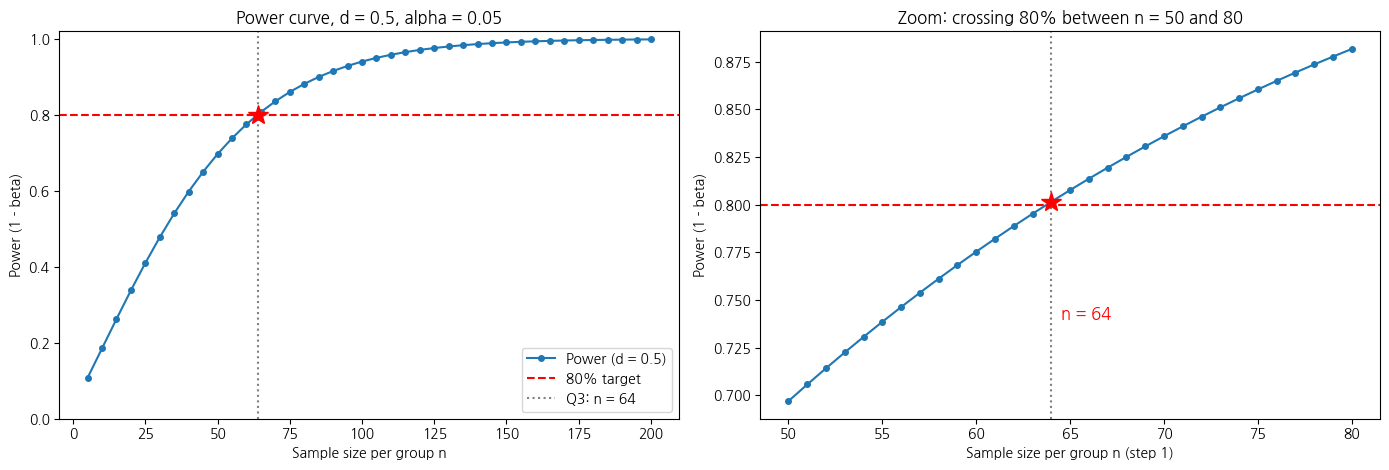

In [9]:
# 문제 2 · Q4 · 검정력 곡선 (d = 0.5)
import numpy as np
import unicodedata
import matplotlib.pyplot as plt
from statsmodels.stats.power import TTestIndPower

analysis = TTestIndPower()
d = 0.5
n_list = np.arange(5, 201, 5)
power = analysis.power(effect_size=d, nobs1=n_list, alpha=0.05, ratio=1)
n_q3 = int(np.ceil(analysis.solve_power(effect_size=d, alpha=0.05, power=0.8, ratio=1)))
first = n_list[np.argmax(power >= 0.8)]

print("[개념]")
print("▸검정력 곡선: 효과크기와 α를 고정하고, 표본수 n에 따라 검정력이 어떻게 변하는지 그린 곡선")
print("▸n이 커질수록 검정력은 올라가다가 1에 가까워지며 완만해진다 (S자 모양)")
print("▸곡선이 80% 선을 처음 넘는 n이 '필요한 최소 표본수'다\n")

def width(s):
    return sum(2 if unicodedata.east_asian_width(c) in 'WF' else 1 for c in s)

def pad(s, w):
    return ' ' * (w - width(s)) + s

show = [5, 10, 20, 30, 50, 60, 65, 100, 150, 200]
head = ["집단당 n", "검정력", "80% 달성"]
rows = []
for n in show:
    p = power[list(n_list).index(n)]
    rows.append(["%d" % n, "%.3f" % p, "O" if p >= 0.8 else "X"])
W = [max(width(r[k]) for r in [head] + rows) + 2 for k in range(3)]
line = "+" + "+".join("-" * w for w in W) + "+"
print("[d = 0.5일 때 n별 검정력 (일부)]")
print(line)
print("|" + "|".join(pad(head[k] + " ", W[k]) for k in range(3)) + "|")
print(line)
for r in rows:
    print("|" + "|".join(pad(r[k] + " ", W[k]) for k in range(3)) + "|")
print(line)

print("\n[Q3와 비교]")
print("▸Q3 solve_power 결과: 집단당 %d명 (검정력 %.3f)" % (n_q3, analysis.power(effect_size=d, nobs1=n_q3, alpha=0.05)))
print("▸곡선(5 간격)에서 80%%를 처음 넘는 n: %d (바로 앞 n=%d의 검정력 %.3f)"
      % (first, first - 5, power[list(n_list).index(first - 5)]))
print("▸n을 5씩 바꿨기 때문에 60과 65 사이에서 80%%를 넘고, 그 사이의 정확한 값이 %d이다" % n_q3)
print("▸결론: 곡선이 80%% 선을 넘는 지점은 Q3에서 구한 %d명과 일치한다." % n_q3)

# 그래프
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(n_list, power, 'o-', color='C0', ms=4, label='Power (d = 0.5)')
axes[0].axhline(0.8, color='red', linestyle='--', label='80% target')
axes[0].axvline(n_q3, color='gray', linestyle=':', label='Q3: n = %d' % n_q3)
axes[0].plot(n_q3, 0.8, 'r*', ms=15)
axes[0].set_xlabel('Sample size per group n')
axes[0].set_ylabel('Power (1 - beta)')
axes[0].set_ylim(0, 1.02)
axes[0].set_title('Power curve, d = 0.5, alpha = 0.05')
axes[0].legend(loc='lower right')

zoom = np.arange(50, 81)
pz = analysis.power(effect_size=d, nobs1=zoom, alpha=0.05, ratio=1)
axes[1].plot(zoom, pz, 'o-', color='C0', ms=4)
axes[1].axhline(0.8, color='red', linestyle='--')
axes[1].axvline(n_q3, color='gray', linestyle=':')
axes[1].plot(n_q3, analysis.power(effect_size=d, nobs1=n_q3, alpha=0.05), 'r*', ms=15)
axes[1].text(n_q3 + 0.5, 0.74, 'n = %d' % n_q3, color='red', fontsize=12)
axes[1].set_xlabel('Sample size per group n (step 1)')
axes[1].set_ylabel('Power (1 - beta)')
axes[1].set_title('Zoom: crossing 80% between n = 50 and 80')

plt.tight_layout()
plt.show()

### 💬 정리 · 결과를 말로 설명해 보기

- Q3에서 펭귄의 32g 차이(d ≈ 0.074)를 80% 검정력으로 잡으려면 집단당 몇 마리가 필요했나요?
  팔머 기지 데이터는 **전체가 344마리**입니다. 이 연구는 애초에 가능했을까요?

- 검정력이 낮은 연구에서 "유의한 차이가 없었다"는 결과가 나왔을 때, 우리는 무엇을 알 수 있고
  **무엇을 알 수 없나요?** (7장 문제 4 Q5의 Adelie 수컷 회귀를 떠올려 보세요)

- 실험을 **시작하기 전에** 표본수를 정해야 하는 이유는 무엇인가요?
  데이터를 본 **뒤에** 정하면 무엇이 잘못될까요?

- 유의수준 alpha를 0.05에서 0.01로 낮추면 필요한 n은 늘어날까요, 줄어들까요?
  Q3의 코드를 고쳐 **직접 계산해** 확인해 보세요.

- "검출하고자 하는 효과크기를 얼마로 정할 것인가"는 **통계 문제**인가요, **도메인 문제**인가요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 네 개 값(alpha, beta, 효과크기, n) 중 **셋을 정하면 나머지 하나가 결정됩니다.**
  `solve_power`가 하는 일이 바로 이 방정식을 푸는 것입니다. 무엇을 미지수로 둘지 바꿔 보세요.

- **"유의한 차이 없음"은 "차이 없음"이 아닙니다.** 검정력이 20%인 연구라면, 진짜 차이가 있어도
  5번 중 4번은 놓칩니다. 그런 연구의 "차이 없음"은 증거라기보다 **정보 부족**입니다.

- 세 번째 질문의 답이 곧 다음 문제(p-해킹)의 출발점입니다. 표본수를 데이터를 보고 정한다는 것은
  곧 **결과를 보고 규칙을 바꾼다**는 뜻입니다.

- 마지막 질문 — 고혈압 치료제에서 "혈압을 몇 mmHg 낮추면 임상적으로 의미 있는가"를 정하는 사람은
  통계학자인가요, 의사인가요? 통계는 그 숫자를 **받아서** n을 계산해 줄 뿐입니다.

</details>

① 펭귄 32g을 80% 검정력으로 잡으려면?
   집단당 2,852마리, 두 종 합쳐 5,704마리가 필요하다.
   팔머 기지 전체가 344마리(실제 비교 대상은 151+68=219마리)이므로 필요량의 약 6%뿐이다.
   → 이 크기의 차이를 검출하는 연구는 애초에 불가능했다.

② 검정력이 낮은 연구의 '유의한 차이 없음'에서 알 수 있는 것과 없는 것
   실제 데이터의 검정력은 8.0%뿐 → 진짜 차이가 있어도 92%는 놓치는 설계였다.
   알 수 있는 것: 이 표본으로 80% 잡을 수 있는 최소 효과는 d ≈ 0.41 → 그보다 큰 차이는 없을 가능성이 높다.
   알 수 없는 것: 그보다 작은 차이가 '없다'는 것. 증거가 없다 ≠ 없다는 증거다.
   7장 Adelie 수컷 회귀처럼 일부 집단만 뽑아 표본이 작으면, 유의하지 않아도 '관계가 없다'고 결론 내릴 수 없다.

③ 표본수를 미리 정해야 하는 이유
   n을 미리 정해야 α(5%)와 검정력이 약속대로 지켜진다.
   데이터를 보면서 '유의할 때까지' 모으면, 차이가 전혀 없어도 기각될 확률이 커진다.
   시뮬레이션: 효과 0인데 10마리마다 확인하며 p<0.05면 멈추면 거짓 양성이 20.0% (5%의 약 4배)

④ α를 0.05 → 0.01로 낮추면?  (Q3 코드에서 alpha만 바꿔 계산)
     d       α=0.05     α=0.01    증가율
   0.074     2,852      4,244    1.49배
   0.200       394        586    1.49배
   0.500        64         96    1.50배
   0.800        26         39    1.50배
   → 필요한 n이 약 1.5배로 늘어난다. 기각 기준이 엄격해져 같은 검정력을 얻으려면 표본이 더 필요하다.

⑤ 검출할 효과크기는 통계 문제인가, 도메인 문제인가?
   주로 도메인 문제다. '몇 g 차이부터 생물학적으로 의미 있나', '클릭

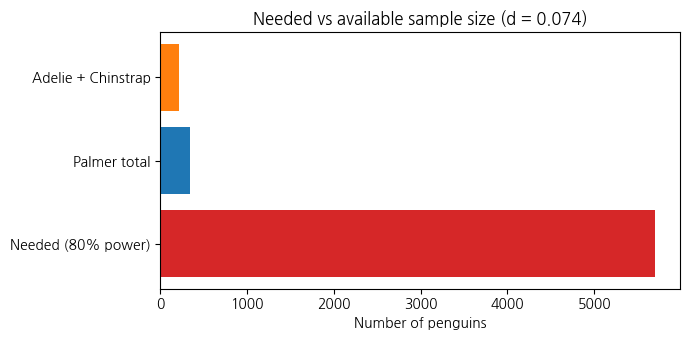

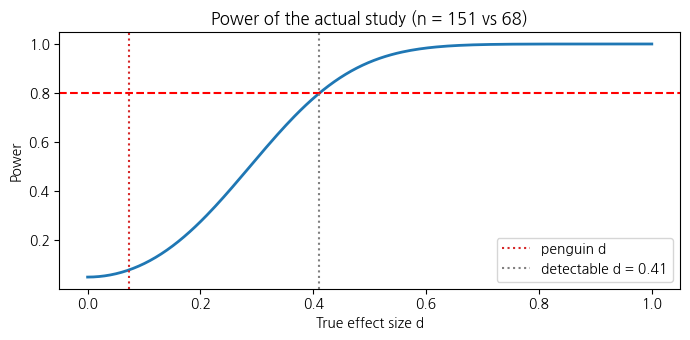

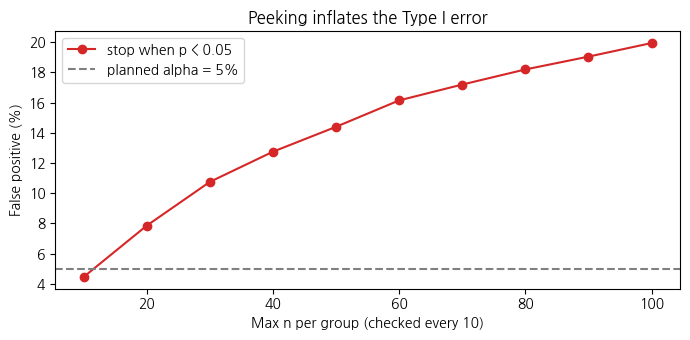

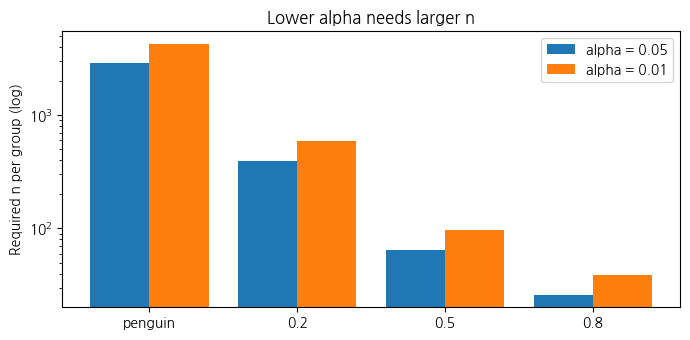

In [10]:
# 문제 2 · 💬 정리 (①~⑤ 통합)
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import TTestIndPower

an = TTestIndPower()
nA, nB = len(adelie), len(chinstrap)
s = np.sqrt(((nA-1)*np.var(adelie, ddof=1) + (nB-1)*np.var(chinstrap, ddof=1)) / (nA+nB-2))
d = abs(np.mean(adelie) - np.mean(chinstrap)) / s
need = int(np.ceil(an.solve_power(effect_size=d, alpha=0.05, power=0.8)))

print("① 펭귄 32g을 80% 검정력으로 잡으려면?")
print("   집단당 %s마리, 두 종 합쳐 %s마리가 필요하다." % (format(need, ','), format(need*2, ',')))
print("   팔머 기지 전체가 344마리(실제 비교 대상은 %d+%d=%d마리)이므로 필요량의 약 %.0f%%뿐이다." % (nA, nB, nA+nB, 344/(need*2)*100))
print("   → 이 크기의 차이를 검출하는 연구는 애초에 불가능했다.\n")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(['Needed (80% power)', 'Palmer total', 'Adelie + Chinstrap'], [need*2, 344, nA+nB], color=['C3', 'C0', 'C1'])
ax.set_xlabel('Number of penguins')
ax.set_title('Needed vs available sample size (d = %.3f)' % d)
plt.tight_layout(); plt.show()

pw = an.power(effect_size=d, nobs1=nA, alpha=0.05, ratio=nB/nA)
mde = an.solve_power(nobs1=nA, alpha=0.05, power=0.8, ratio=nB/nA)
print("② 검정력이 낮은 연구의 '유의한 차이 없음'에서 알 수 있는 것과 없는 것")
print("   실제 데이터의 검정력은 %.1f%%뿐 → 진짜 차이가 있어도 %.0f%%는 놓치는 설계였다." % (pw*100, (1-pw)*100))
print("   알 수 있는 것: 이 표본으로 80%% 잡을 수 있는 최소 효과는 d ≈ %.2f → 그보다 큰 차이는 없을 가능성이 높다." % mde)
print("   알 수 없는 것: 그보다 작은 차이가 '없다'는 것. 증거가 없다 ≠ 없다는 증거다.")
print("   7장 Adelie 수컷 회귀처럼 일부 집단만 뽑아 표본이 작으면, 유의하지 않아도 '관계가 없다'고 결론 내릴 수 없다.\n")
dd = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(dd, an.power(effect_size=dd + 1e-9, nobs1=nA, alpha=0.05, ratio=nB/nA), lw=2)
ax.axhline(0.8, color='red', ls='--'); ax.axvline(d, color='C3', ls=':', label='penguin d')
ax.axvline(mde, color='gray', ls=':', label='detectable d = %.2f' % mde)
ax.set_xlabel('True effect size d'); ax.set_ylabel('Power')
ax.set_title('Power of the actual study (n = %d vs %d)' % (nA, nB)); ax.legend()
plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
x, y = rng.normal(size=(2000, 100)), rng.normal(size=(2000, 100))
looks = np.arange(10, 101, 10)
hit = np.zeros(2000, bool); rate = []
for k in looks:
    hit |= stats.ttest_ind(x[:, :k], y[:, :k], axis=1).pvalue < 0.05
    rate.append(hit.mean() * 100)
print("③ 표본수를 미리 정해야 하는 이유")
print("   n을 미리 정해야 α(5%)와 검정력이 약속대로 지켜진다.")
print("   데이터를 보면서 '유의할 때까지' 모으면, 차이가 전혀 없어도 기각될 확률이 커진다.")
print("   시뮬레이션: 효과 0인데 10마리마다 확인하며 p<0.05면 멈추면 거짓 양성이 %.1f%% (5%%의 약 %.0f배)\n" % (rate[-1], rate[-1]/5))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(looks, rate, 'o-', color='C3', label='stop when p < 0.05')
ax.axhline(5, color='gray', ls='--', label='planned alpha = 5%')
ax.set_xlabel('Max n per group (checked every 10)'); ax.set_ylabel('False positive (%)')
ax.set_title('Peeking inflates the Type I error'); ax.legend()
plt.tight_layout(); plt.show()

ds = [d, 0.2, 0.5, 0.8]
n05 = [int(np.ceil(an.solve_power(effect_size=v, alpha=0.05, power=0.8))) for v in ds]
n01 = [int(np.ceil(an.solve_power(effect_size=v, alpha=0.01, power=0.8))) for v in ds]
print("④ α를 0.05 → 0.01로 낮추면?  (Q3 코드에서 alpha만 바꿔 계산)")
print("     d       α=0.05     α=0.01    증가율")
for i in range(4):
    print("   %.3f  %8s  %9s   %5.2f배" % (ds[i], format(n05[i], ','), format(n01[i], ','), n01[i]/n05[i]))
print("   → 필요한 n이 약 1.5배로 늘어난다. 기각 기준이 엄격해져 같은 검정력을 얻으려면 표본이 더 필요하다.\n")
fig, ax = plt.subplots(figsize=(7, 3.5))
lab = ['penguin', '0.2', '0.5', '0.8']; xi = np.arange(4)
ax.bar(xi - 0.2, n05, 0.4, label='alpha = 0.05'); ax.bar(xi + 0.2, n01, 0.4, label='alpha = 0.01')
ax.set_xticks(xi); ax.set_xticklabels(lab); ax.set_yscale('log')
ax.set_ylabel('Required n per group (log)'); ax.set_title('Lower alpha needs larger n'); ax.legend()
plt.tight_layout(); plt.show()

print("⑤ 검출할 효과크기는 통계 문제인가, 도메인 문제인가?")
print("   주로 도메인 문제다. '몇 g 차이부터 생물학적으로 의미 있나', '클릭률 몇 %p부터 돈이 되나'는")
print("   그 분야의 지식, 비용, 목적이 정한다. 통계는 그 값이 정해진 뒤 필요한 n을 계산해 줄 뿐이다.")
print("   다만 효과크기를 d로 바꾸고 α·β와 연결하는 일은 통계의 몫이라, 두 분야가 함께 정한다.")

## 문제 3 · 유의한 결과는 '만들어질' 수 있다

`난이도 중` · `예상 25분`

**📖 상황**

- 심리학 분야의 과거 연구 100건을 재실험한 결과, 원래 유의했던 97건 중 **36건만** 다시
  유의했습니다(강의 9장). 이것이 **재현성 위기(Reproducibility Crisis)**입니다.

- 원인 중 하나는 **p-해킹** — 의도했든 아니든 p-값을 0.05 아래로 밀어 넣는 행위입니다.

- 이번 문제는 **아무 차이도 없는 두 집단**을 놓고, 분석 방식만 바꿔가며
  "유의한 결과"를 얼마나 만들어낼 수 있는지 **직접 세어 봅니다.**

- 진짜 차이가 없으므로 유의하다는 결론은 **전부 제1종 오류**입니다.
  절차를 지켰다면 5%여야 합니다.

**🎯 이 문제로 배우는 것**

- **정직한 분석 / 표본 추가형 / 다중비교형** 세 가지의 제1종 오류율을 직접 세어 비교하고,
  다중비교 보정이 왜 필요한지 확인합니다.

In [11]:
# 문제 3 · 데이터 준비 — 실행만 하세요
N_SIM = 1000     # 시뮬레이션 반복 횟수
SEED  = 777      # 난수 시드 — Q1~Q4에서 각각 이 값으로 시작하면 몇 번 재실행해도 같은 결과가 나옵니다

print("이번 문제의 전제")
print("  두 집단 A, B는 모두 N(0, 1)에서 나옵니다 → 진짜 차이는 정확히 0")
print("  즉 귀무가설이 '참'인 상황이며, 유의하다는 결론은 모두 제1종 오류입니다.")
print("  절차를 지켰다면 오류율은 유의수준 5% 근처여야 합니다.")
print("\n각 조건마다 %d번씩 반복해 '유의하다고 결론 내린 비율'을 셉니다." % N_SIM)

이번 문제의 전제
  두 집단 A, B는 모두 N(0, 1)에서 나옵니다 → 진짜 차이는 정확히 0
  즉 귀무가설이 '참'인 상황이며, 유의하다는 결론은 모두 제1종 오류입니다.
  절차를 지켰다면 오류율은 유의수준 5% 근처여야 합니다.

각 조건마다 1000번씩 반복해 '유의하다고 결론 내린 비율'을 셉니다.


### Q1 · 정직한 분석의 제1종 오류율을 확인해 봅시다

- **기준선**을 먼저 만듭니다. 각 집단에서 **20명씩 뽑아 딱 한 번만** t-검정하세요.

- 이것을 `N_SIM`번 반복해 **p < 0.05가 나온 비율**을 출력하세요.

- 이 값이 유의수준 0.05와 가까운지 확인하세요.

- `💡 힌트` 셀 맨 위에서 `rng = np.random.default_rng(SEED)`로 시작하세요.
  이렇게 하면 셀을 몇 번 다시 실행해도 같은 결과가 나옵니다. **Q2~Q4도 모두 이렇게 시작합니다.**

- `💡 힌트` `rng.normal(0, 1, 20)`으로 표본을 만들고, `for`문으로 반복해 세면 됩니다.

[개념]
▸진짜 차이가 0이므로 'p < 0.05'는 모두 제1종 오류(거짓 양성)다
▸절차를 정직하게 지키면(표본 크기 고정, 검정 한 번) 오류율은 α = 5% 근처여야 한다
▸이 값이 Q2~Q4에서 비교할 '기준선'이 된다

[결과]  집단당 20명, 한 번만 t-검정, 1000번 반복
+-------------------------+------------+
| 항목                    |         값 |
+-------------------------+------------+
| 유의하다고 결론 낸 횟수 |  49 / 1000 |
| 제1종 오류율            |       4.9% |
| 목표 유의수준 α         |       5.0% |
| 우연 허용 범위 (95%)    | 3.6 ~ 6.4% |
+-------------------------+------------+

▸결론: 오류율 4.9%는 α = 5%와 우연한 흔들림 범위 안에서 일치한다.
   → 정직한 분석은 약속한 만큼(5%)만 틀린다. 이것이 기준선이다.


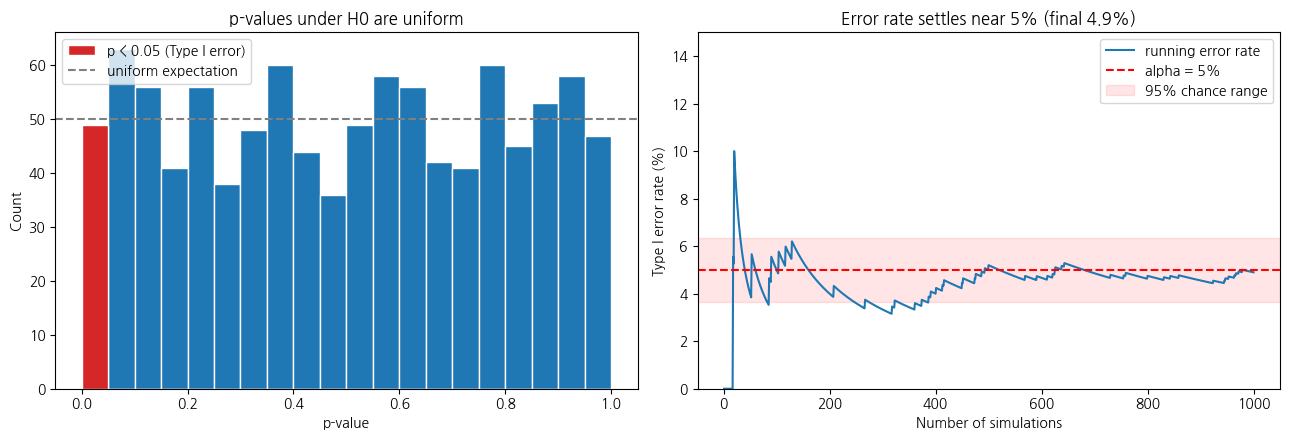

In [12]:
# 문제 3 · Q1 · 정직한 분석의 제1종 오류율 (기준선)
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import unicodedata

rng = np.random.default_rng(SEED)
n, alpha = 20, 0.05

p_values = []
for _ in range(N_SIM):
    a = rng.normal(0, 1, n)
    b = rng.normal(0, 1, n)
    p_values.append(stats.ttest_ind(a, b).pvalue)
p_values = np.array(p_values)

sig = p_values < alpha
rate = sig.mean()
se = np.sqrt(alpha * (1 - alpha) / N_SIM)          # 반복 1000번의 우연한 흔들림
lo, hi = alpha - 1.96 * se, alpha + 1.96 * se

print("[개념]")
print("▸진짜 차이가 0이므로 'p < 0.05'는 모두 제1종 오류(거짓 양성)다")
print("▸절차를 정직하게 지키면(표본 크기 고정, 검정 한 번) 오류율은 α = 5% 근처여야 한다")
print("▸이 값이 Q2~Q4에서 비교할 '기준선'이 된다\n")

def width(t):
    return sum(2 if unicodedata.east_asian_width(c) in 'WF' else 1 for c in t)

rows = [["항목", "값"],
        ["유의하다고 결론 낸 횟수", "%d / %d" % (sig.sum(), N_SIM)],
        ["제1종 오류율", "%.1f%%" % (rate * 100)],
        ["목표 유의수준 α", "%.1f%%" % (alpha * 100)],
        ["우연 허용 범위 (95%)", "%.1f ~ %.1f%%" % (lo * 100, hi * 100)]]
W = [max(width(r[k]) for r in rows) + 2 for k in range(2)]
line = "+" + "+".join("-" * w for w in W) + "+"
print("[결과]  집단당 %d명, 한 번만 t-검정, %d번 반복" % (n, N_SIM))
print(line)
for i, r in enumerate(rows):
    print("| " + r[0] + " " * (W[0] - width(r[0]) - 1) + "|" + " " * (W[1] - width(r[1]) - 1) + r[1] + " |")
    if i == 0:
        print(line)
print(line)

if lo <= rate <= hi:
    print("\n▸결론: 오류율 %.1f%%는 α = 5%%와 우연한 흔들림 범위 안에서 일치한다." % (rate * 100))
    print("   → 정직한 분석은 약속한 만큼(5%)만 틀린다. 이것이 기준선이다.")
else:
    print("\n▸결론: 오류율 %.1f%%가 허용 범위를 벗어났다 (반복 수가 적어 생긴 우연일 수 있음)." % (rate * 100))

# 그래프
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(p_values, bins=20, range=(0, 1), color='C0', edgecolor='white')
axes[0].hist(p_values[sig], bins=20, range=(0, 1), color='C3', edgecolor='white', label='p < 0.05 (Type I error)')
axes[0].axhline(N_SIM / 20, color='gray', ls='--', label='uniform expectation')
axes[0].set_xlabel('p-value')
axes[0].set_ylabel('Count')
axes[0].set_title('p-values under H0 are uniform')
axes[0].legend()

running = np.cumsum(sig) / np.arange(1, N_SIM + 1) * 100
axes[1].plot(np.arange(1, N_SIM + 1), running, color='C0', lw=1.5, label='running error rate')
axes[1].axhline(5, color='red', ls='--', label='alpha = 5%')
axes[1].axhspan(lo * 100, hi * 100, color='red', alpha=0.1, label='95% chance range')
axes[1].set_ylim(0, 15)
axes[1].set_xlabel('Number of simulations')
axes[1].set_ylabel('Type I error rate (%)')
axes[1].set_title('Error rate settles near 5%% (final %.1f%%)' % (rate * 100))
axes[1].legend()

plt.tight_layout()
plt.show()

### Q2 · 해킹 ① — 결과를 보고 표본을 더 모으면

- 강의 9장이 첫 번째로 꼽은 p-해킹입니다 — _"결과를 보며 표본크기를 늘려서는 안 됨"_

- 다음 규칙을 따르는 'p-해커'를 만드세요.
  1. 각 집단 **20명**으로 시작해 t-검정
  2. **p < 0.05면 "찾았다!"** 하고 즉시 멈춤
  3. **p ≥ 0.05면 각 집단에 10명씩 추가**해 다시 검정
  4. 이 과정을 **최대 5번**까지 반복

- `N_SIM`번 반복해 **한 번이라도 p < 0.05를 얻은 비율**을 출력하고, Q1의 값과 비교하세요.

- `💡 힌트` `rng = np.random.default_rng(SEED)`로 시작하세요.
  '해커 한 명'을 함수로 만들어 두면 반복이 깔끔해집니다.
  표본을 `list`로 두면 `.extend()`로 이어붙일 수 있습니다.

[개념]
▸진짜 차이는 0 → '찾았다!'는 전부 제1종 오류
▸p-해커 규칙: 20명으로 검정 → 유의하면 멈춤, 아니면 10명씩 추가해 다시 검정 (최대 5번)
▸검정을 여러 번 하면 그중 한 번이라도 우연히 p < 0.05가 나올 기회가 늘어난다

[p-해커 1000명의 결과]
+-----------+----------+-------------+-------------+
| 검정 차례 | 집단당 n | 여기서 멈춤 | 누적 오류율 |
+-----------+----------+-------------+-------------+
|     1번째 |       20 |        57명 |        5.7% |
|     2번째 |       30 |        23명 |        8.0% |
|     3번째 |       40 |        30명 |       11.0% |
|     4번째 |       50 |        16명 |       12.6% |
|     5번째 |       60 |         9명 |       13.5% |
+-----------+----------+-------------+-------------+

[Q1과 비교]
▸Q1 정직한 분석 (20명, 검정 1번)     : 4.9%
▸Q2 p-해커 (보면서 추가, 최대 5번)  : 13.5%
▸오류율이 약 2.8배로 부풀었다.
▸결론: 데이터를 조작하지 않아도 '결과를 보며 n을 늘리는' 절차만으로 α = 5% 약속이 깨진다.
   그래서 표본크기는 실험 전에 정하고, 중간에 결과를 보고 늘리면 안 된다.


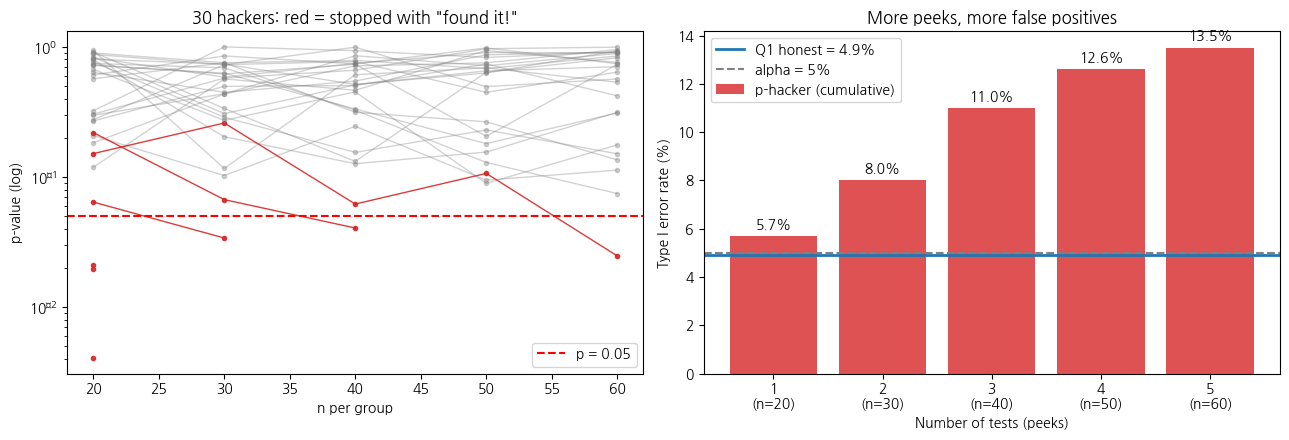

In [13]:
# 문제 3 · Q2 · 해킹 ① — 결과를 보고 표본을 더 모으면
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import unicodedata

rng = np.random.default_rng(SEED)
START, ADD, MAX_TRIES, alpha = 20, 10, 5, 0.05   # 20명 시작, 10명씩 추가, 검정 최대 5번

def p_hacker():
    """p < 0.05가 나오면 멈추는 해커 한 명. (몇 번째 검정에서 찾았는지, p-값 기록)을 돌려줌"""
    a = list(rng.normal(0, 1, START))
    b = list(rng.normal(0, 1, START))
    history = []
    for k in range(1, MAX_TRIES + 1):
        p = stats.ttest_ind(a, b).pvalue
        history.append(p)
        if p < alpha:
            return k, history          # "찾았다!" → 즉시 멈춤
        a.extend(rng.normal(0, 1, ADD))
        b.extend(rng.normal(0, 1, ADD))
    return 0, history                  # 끝까지 못 찾음

found_at, histories = [], []
for _ in range(N_SIM):
    k, h = p_hacker()
    found_at.append(k)
    histories.append(h)
found_at = np.array(found_at)
hack_rate = np.mean(found_at > 0)
base_rate = rate if 'rate' in globals() else 0.05   # Q1 결과 (없으면 0.05)

print("[개념]")
print("▸진짜 차이는 0 → '찾았다!'는 전부 제1종 오류")
print("▸p-해커 규칙: 20명으로 검정 → 유의하면 멈춤, 아니면 10명씩 추가해 다시 검정 (최대 %d번)" % MAX_TRIES)
print("▸검정을 여러 번 하면 그중 한 번이라도 우연히 p < 0.05가 나올 기회가 늘어난다\n")

def width(t):
    return sum(2 if unicodedata.east_asian_width(c) in 'WF' else 1 for c in t)

rows = [["검정 차례", "집단당 n", "여기서 멈춤", "누적 오류율"]]
for k in range(1, MAX_TRIES + 1):
    rows.append(["%d번째" % k, "%d" % (START + ADD * (k - 1)), "%d명" % np.sum(found_at == k),
                 "%.1f%%" % (np.mean((found_at > 0) & (found_at <= k)) * 100)])
W = [max(width(r[j]) for r in rows) + 2 for j in range(4)]
line = "+" + "+".join("-" * w for w in W) + "+"
print("[p-해커 %d명의 결과]" % N_SIM)
print(line)
for i, r in enumerate(rows):
    print("|" + "|".join(" " * (W[j] - width(r[j]) - 1) + r[j] + " " for j in range(4)) + "|")
    if i == 0:
        print(line)
print(line)

print("\n[Q1과 비교]")
print("▸Q1 정직한 분석 (20명, 검정 1번)     : %.1f%%" % (base_rate * 100))
print("▸Q2 p-해커 (보면서 추가, 최대 %d번)  : %.1f%%" % (MAX_TRIES, hack_rate * 100))
print("▸오류율이 약 %.1f배로 부풀었다." % (hack_rate / base_rate))
print("▸결론: 데이터를 조작하지 않아도 '결과를 보며 n을 늘리는' 절차만으로 α = 5% 약속이 깨진다.")
print("   그래서 표본크기는 실험 전에 정하고, 중간에 결과를 보고 늘리면 안 된다.")

# 그래프
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for h in histories[:30]:
    ns = START + ADD * np.arange(len(h))
    hit = h[-1] < alpha
    axes[0].plot(ns, h, '-o', ms=3, lw=1, color='C3' if hit else 'gray', alpha=0.9 if hit else 0.35)
axes[0].axhline(alpha, color='red', ls='--', label='p = 0.05')
axes[0].set_yscale('log')
axes[0].set_xlabel('n per group')
axes[0].set_ylabel('p-value (log)')
axes[0].set_title('30 hackers: red = stopped with "found it!"')
axes[0].legend()

cum = [np.mean((found_at > 0) & (found_at <= k)) * 100 for k in range(1, MAX_TRIES + 1)]
labels = ['%d\n(n=%d)' % (k, START + ADD * (k - 1)) for k in range(1, MAX_TRIES + 1)]
axes[1].bar(labels, cum, color='C3', alpha=0.8, label='p-hacker (cumulative)')
axes[1].axhline(base_rate * 100, color='C0', lw=2, label='Q1 honest = %.1f%%' % (base_rate * 100))
axes[1].axhline(5, color='gray', ls='--', label='alpha = 5%')
for i, v in enumerate(cum):
    axes[1].text(i, v + 0.3, '%.1f%%' % v, ha='center')
axes[1].set_xlabel('Number of tests (peeks)')
axes[1].set_ylabel('Type I error rate (%)')
axes[1].set_title('More peeks, more false positives')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

### Q3 · 해킹 ② — 지표를 20개 재서 하나만 보고하면

- 강의 9장의 두 번째 p-해킹입니다 — _"마음에 드는 해석만 보고해서는 안 됨"_

- 이번엔 표본을 추가하지 않습니다. 대신 **아무 차이 없는 지표 20개**를 각각 20명씩 검정하고,
  **하나라도 유의하면 그것만 보고**합니다.

- `N_SIM`번 반복해 성공률을 출력하세요.

- 이론값 **1 − 0.95²⁰**과 나란히 출력해 비교하세요.

- `💡 힌트` `rng = np.random.default_rng(SEED)`로 시작하세요.
  바깥 `for`문은 시뮬레이션 반복, 안쪽 `for`문은 20개 지표입니다.
  `any()`를 쓰면 짧게 쓸 수 있습니다.

[개념]
▸지표 20개 모두 진짜 차이는 0 → 유의한 지표는 전부 우연(제1종 오류)
▸지표 하나가 우연히 유의할 확률 5%, 하나도 안 걸릴 확률 0.95
▸20개 모두 안 걸릴 확률 0.95^20 → 하나라도 걸릴 확률 = 1 − 0.95^20 (다중비교 문제)

[시뮬레이션 vs 이론]
+---------------------+----------------+
| 구분                | 성공률(오류율) |
+---------------------+----------------+
| 시뮬레이션 (1000번) |          65.5% |
| 이론값 1 − 0.95^20  |          64.2% |
| 차이                |         +1.3%p |
+---------------------+----------------+

[해킹 방법별 제1종 오류율]
+---------------------------+--------+
| 방법                      | 오류율 |
+---------------------------+--------+
| Q1 정직한 분석 (검정 1번) |   4.9% |
| Q2 보면서 표본 추가       |  13.5% |
| Q3 지표 20개 중 골라 보고 |  65.5% |
+---------------------------+--------+

▸결론: 지표 20개를 재서 유의한 것만 보고하면, 차이가 전혀 없어도 약 66%의 연구가
   '유의한 발견'을 보고하게 된다. 시뮬레이션이 이론값과 거의 일치한다.
   → 무엇을 검정할지 미리 정하고, 검정한 것은 모두 보고해야 한다 (또는 Bonferroni 등 보정).


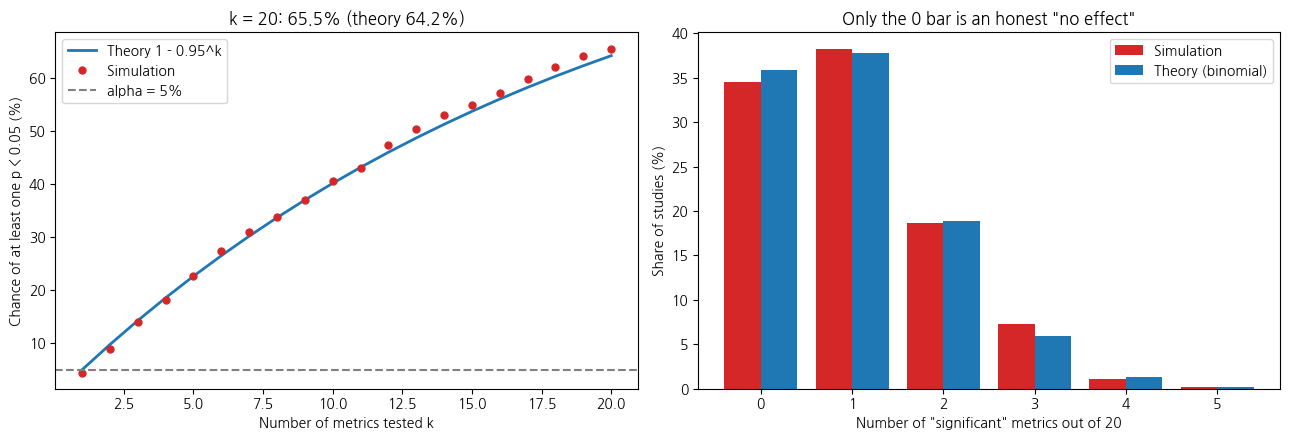

In [14]:
# 문제 3 · Q3 · 해킹 ② — 지표를 20개 재서 하나만 보고하면
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import unicodedata

rng = np.random.default_rng(SEED)
N_METRIC, n, alpha = 20, 20, 0.05

success = []                                  # 하나라도 유의했는가
pmat = np.zeros((N_SIM, N_METRIC))            # 그래프용 p-값 기록
for i in range(N_SIM):                        # 바깥: 시뮬레이션 반복
    ps = []
    for j in range(N_METRIC):                 # 안쪽: 지표 20개
        a = rng.normal(0, 1, n)
        b = rng.normal(0, 1, n)
        ps.append(stats.ttest_ind(a, b).pvalue)
    pmat[i] = ps
    success.append(any(p < alpha for p in ps))
sim_rate = np.mean(success)
theory = 1 - (1 - alpha) ** N_METRIC

print("[개념]")
print("▸지표 20개 모두 진짜 차이는 0 → 유의한 지표는 전부 우연(제1종 오류)")
print("▸지표 하나가 우연히 유의할 확률 5%, 하나도 안 걸릴 확률 0.95")
print("▸20개 모두 안 걸릴 확률 0.95^20 → 하나라도 걸릴 확률 = 1 − 0.95^20 (다중비교 문제)\n")

def width(t):
    return sum(2 if unicodedata.east_asian_width(c) in 'WF' else 1 for c in t)

def show(rows):
    W = [max(width(r[j]) for r in rows) + 2 for j in range(len(rows[0]))]
    line = "+" + "+".join("-" * w for w in W) + "+"
    print(line)
    for i, r in enumerate(rows):
        cells = [(" " + r[j] + " " * (W[j] - width(r[j]) - 1)) if j == 0
                 else (" " * (W[j] - width(r[j]) - 1) + r[j] + " ") for j in range(len(r))]
        print("|" + "|".join(cells) + "|")
        if i == 0:
            print(line)
    print(line)

print("[시뮬레이션 vs 이론]")
show([["구분", "성공률(오류율)"],
      ["시뮬레이션 (%d번)" % N_SIM, "%.1f%%" % (sim_rate * 100)],
      ["이론값 1 − 0.95^20", "%.1f%%" % (theory * 100)],
      ["차이", "%+.1f%%p" % ((sim_rate - theory) * 100)]])

q1 = rate * 100 if 'rate' in globals() else 5.0
q2 = hack_rate * 100 if 'hack_rate' in globals() else float('nan')
print("\n[해킹 방법별 제1종 오류율]")
show([["방법", "오류율"],
      ["Q1 정직한 분석 (검정 1번)", "%.1f%%" % q1],
      ["Q2 보면서 표본 추가", "%.1f%%" % q2],
      ["Q3 지표 20개 중 골라 보고", "%.1f%%" % (sim_rate * 100)]])

print("\n▸결론: 지표 20개를 재서 유의한 것만 보고하면, 차이가 전혀 없어도 약 %.0f%%의 연구가" % (sim_rate * 100))
print("   '유의한 발견'을 보고하게 된다. 시뮬레이션이 이론값과 거의 일치한다.")
print("   → 무엇을 검정할지 미리 정하고, 검정한 것은 모두 보고해야 한다 (또는 Bonferroni 등 보정).")

# 그래프
ks = np.arange(1, N_METRIC + 1)
sim_k = [np.mean((pmat[:, :k] < alpha).any(axis=1)) * 100 for k in ks]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ks, (1 - 0.95 ** ks) * 100, 'C0', lw=2, label='Theory 1 - 0.95^k')
axes[0].plot(ks, sim_k, 'o', color='C3', ms=5, label='Simulation')
axes[0].axhline(5, color='gray', ls='--', label='alpha = 5%')
axes[0].set_xlabel('Number of metrics tested k')
axes[0].set_ylabel('Chance of at least one p < 0.05 (%)')
axes[0].set_title('k = 20: %.1f%% (theory %.1f%%)' % (sim_rate * 100, theory * 100))
axes[0].legend()

cnt = (pmat < alpha).sum(axis=1)
xs = np.arange(0, 6)
axes[1].bar(xs - 0.2, [np.mean(cnt == x) * 100 for x in xs], 0.4, color='C3', label='Simulation')
axes[1].bar(xs + 0.2, stats.binom.pmf(xs, N_METRIC, alpha) * 100, 0.4, color='C0', label='Theory (binomial)')
axes[1].set_xlabel('Number of "significant" metrics out of 20')
axes[1].set_ylabel('Share of studies (%)')
axes[1].set_title('Only the 0 bar is an honest "no effect"')
axes[1].legend()

plt.tight_layout()
plt.show()

### Q4 · 세 결과를 나란히 놓고, 보정 효과까지 확인해 봅시다

- Q3의 방식에 **본페로니 보정**을 적용하면 오류율이 어떻게 되는지 계산하세요.
  (지표가 20개이므로 각 검정의 기준을 `0.05 / 20`으로 낮춥니다)

- Q1 ~ Q3 결과와 보정 후 결과, 총 **네 개를 막대그래프**로 그리세요.

- **α = 5% 기준선**을 수평선으로 함께 표시해 어느 것이 선을 넘는지 한눈에 보이게 하세요.

- `💡 힌트` 보정 후 계산도 `rng = np.random.default_rng(SEED)`로 시작하세요.
  Q3의 코드에서 기준값만 `0.05 / 20`으로 바꾸면 됩니다.

- `💡 힌트` `plt.bar(라벨리스트, 값리스트)` / `plt.axhline(5, color='red', linestyle='--')`

[개념]
▸본페로니 보정: 검정을 m번 하면 각 검정의 기준을 α/m으로 낮춘다
▸지표 20개 → 각 기준 0.05/20 = 0.0025 → 전체에서 하나라도 걸릴 확률이 다시 약 5%가 된다
▸이론값: 1 − (1 − 0.0025)^20 = 4.9%

[네 가지 결과 비교]
+------------------------+--------------+-----------+
| 방법                   | 제1종 오류율 | α=5% 대비 |
+------------------------+--------------+-----------+
| Q1 정직한 분석         |         4.9% |     1.0배 |
| Q2 보면서 표본 추가    |        13.5% |     2.7배 |
| Q3 지표 20개 골라 보고 |        65.5% |    13.1배 |
| Q3 + 본페로니 보정     |         4.9% |     1.0배 |
+------------------------+--------------+-----------+

[해석]
▸Q2·Q3처럼 절차를 어기면 오류율이 5%를 크게 넘는다 (Q3는 약 13배)
▸본페로니 보정 후 오류율은 4.9% → 다시 α = 5% 수준으로 돌아온다
▸단, 기준이 엄격해진 만큼 진짜 효과를 놓칠 위험(β)은 커진다 → 검정력 손해를 감수하는 보정
▸가장 좋은 방법은 보정보다, 무엇을 몇 번 검정할지 미리 정하고 모두 보고하는 것이다


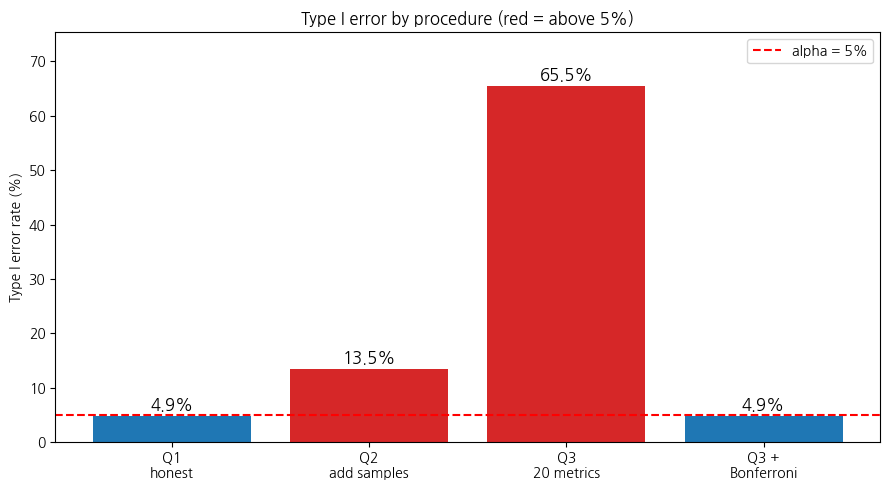

In [15]:
# 문제 3 · Q4 · 세 결과 비교 + 본페로니 보정
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import unicodedata

# 1) 본페로니 보정: Q3와 같은 방식, 기준만 0.05 / 20
rng = np.random.default_rng(SEED)
N_METRIC, n = 20, 20
alpha_b = 0.05 / N_METRIC

success_b = []
for i in range(N_SIM):
    ps = []
    for j in range(N_METRIC):
        a = rng.normal(0, 1, n)
        b = rng.normal(0, 1, n)
        ps.append(stats.ttest_ind(a, b).pvalue)
    success_b.append(any(p < alpha_b for p in ps))
bonf_rate = np.mean(success_b)
bonf_theory = 1 - (1 - alpha_b) ** N_METRIC

print("[개념]")
print("▸본페로니 보정: 검정을 m번 하면 각 검정의 기준을 α/m으로 낮춘다")
print("▸지표 20개 → 각 기준 0.05/20 = %.4f → 전체에서 하나라도 걸릴 확률이 다시 약 5%%가 된다" % alpha_b)
print("▸이론값: 1 − (1 − 0.0025)^20 = %.1f%%\n" % (bonf_theory * 100))

# 2) 네 결과 모으기 (Q1~Q3 셀을 먼저 실행해야 함)
names = ["Q1 정직한 분석", "Q2 보면서 표본 추가", "Q3 지표 20개 골라 보고", "Q3 + 본페로니 보정"]
vals = [rate * 100, hack_rate * 100, sim_rate * 100, bonf_rate * 100]

def width(t):
    return sum(2 if unicodedata.east_asian_width(c) in 'WF' else 1 for c in t)

rows = [["방법", "제1종 오류율", "α=5% 대비"]]
for nm, v in zip(names, vals):
    rows.append([nm, "%.1f%%" % v, "%.1f배" % (v / 5)])
W = [max(width(r[j]) for r in rows) + 2 for j in range(3)]
line = "+" + "+".join("-" * w for w in W) + "+"
print("[네 가지 결과 비교]")
print(line)
for i, r in enumerate(rows):
    cells = [" " + r[0] + " " * (W[0] - width(r[0]) - 1)]
    cells += [" " * (W[j] - width(r[j]) - 1) + r[j] + " " for j in (1, 2)]
    print("|" + "|".join(cells) + "|")
    if i == 0:
        print(line)
print(line)

print("\n[해석]")
print("▸Q2·Q3처럼 절차를 어기면 오류율이 5%%를 크게 넘는다 (Q3는 약 %.0f배)" % (vals[2] / 5))
print("▸본페로니 보정 후 오류율은 %.1f%% → 다시 α = 5%% 수준으로 돌아온다" % vals[3])
print("▸단, 기준이 엄격해진 만큼 진짜 효과를 놓칠 위험(β)은 커진다 → 검정력 손해를 감수하는 보정")
print("▸가장 좋은 방법은 보정보다, 무엇을 몇 번 검정할지 미리 정하고 모두 보고하는 것이다")

# 3) 막대그래프
labels = ['Q1\nhonest', 'Q2\nadd samples', 'Q3\n20 metrics', 'Q3 +\nBonferroni']
colors = ['C3' if v > 5 + 1.96 * np.sqrt(0.05 * 0.95 / N_SIM) * 100 else 'C0' for v in vals]
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, vals, color=colors)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, '%.1f%%' % v, ha='center', fontsize=12)
ax.axhline(5, color='red', linestyle='--', label='alpha = 5%')
ax.set_ylabel('Type I error rate (%)')
ax.set_ylim(0, max(vals) * 1.15)
ax.set_title('Type I error by procedure (red = above 5%)')
ax.legend()
plt.tight_layout()
plt.show()

### 💬 정리 · 결과를 말로 설명해 보기

- Q1의 값은 5%에 가까웠습니다. 이것이 뜻하는 바는 무엇인가요?
  **가설검정은 원래 무엇을 보장해 주는 도구**인가요?

- Q2와 Q3에서 오류율이 뛴 이유를 **각각** 설명해 보세요. 두 해킹의 메커니즘은 같나요, 다른가요?

- Q3의 결과는 무엇을 뜻하나요? "지표 20개를 재고 유의한 하나만 보고한다"는 연구를
  여러분은 신뢰할 수 있나요?

- 강의에 나온 **HARKing**(결과를 본 뒤에 가설을 만드는 행위)은 Q2·Q3 중 어느 쪽과 닮아 있나요?

- **사전 등록(Preregistration)**은 Q2와 Q3를 각각 어떻게 막아 주나요?
  두 해킹에 대해 따로 설명해 보세요.

- 문제 2에서 배운 '표본수 사전 설계'는 Q2를 막는 데 어떤 역할을 하나요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 가설검정이 보장하는 것은 **"정해진 절차를 지켰을 때 제1종 오류가 α 이하"**입니다.
  Q1은 그 보장이 지켜지는 모습이고, Q2·Q3는 절차를 어겼을 때 보장이 무너지는 모습입니다.
  같은 t-검정 함수를 썼는데 결과가 갈렸다는 점에 주목하세요 — 문제는 도구가 아니라 **쓰는 방식**입니다.

- Q2는 **같은 가설을 여러 번 물어본** 것이고, Q3는 **여러 가설을 물어보고 하나만 골라 보고한**
  것입니다. 표현은 다르지만 둘 다 "우연에게 기회를 여러 번 준" 셈입니다.

- 동전 던지기로 생각해 보세요. 앞면이 나올 확률은 1/2이지만, **20번 던져 한 번이라도**
  앞면이 나올 확률은 거의 1입니다. Q3의 숫자가 이 계산입니다.

- 강의 9장은 **가설검증형 연구 vs 탐색형 연구**를 구분합니다. Q3처럼 지표 20개를 훑는 일 자체가
  잘못은 아닙니다. 잘못은 그것을 **가설검증형인 척 보고**하는 데 있습니다.
  탐색에서 찾은 것은 **새 데이터로 다시 확인**해야 가설검증이 됩니다.

- p-값의 한계를 다루는 또 다른 접근으로 **베이즈 인수(Bayes Factor)**가 있습니다.
  강의 9장이 "11장 학습 후 진행 예정"으로 남겨 둔 주제입니다.

</details>

① Q1의 값이 5%에 가깝다는 것의 의미
   약속한 α = 5%, 실제 오류율 4.9% (우연 범위 3.6~6.4%)
   → 가설검정은 '이번 결론이 맞다'를 보장하지 않는다.
   → 정해진 절차를 지키면, 차이가 없을 때 틀리는 비율이 장기적으로 α 이하라는 것을 보장하는 도구다.
   → 그 보장은 '표본크기 고정 + 미리 정한 검정 한 번'이라는 약속이 지켜질 때만 유효하다.

② Q2와 Q3에서 오류율이 뛴 이유
   공통점: 둘 다 '유의할 기회'를 여러 번 만들고, 한 번이라도 걸리면 그것을 결론으로 삼았다.
   Q2: 같은 데이터에 표본을 덧붙여 검정을 반복 → p-값이 출렁이다 우연히 0.05 아래로 내려간 순간 멈춤
       검정끼리 데이터를 공유해 서로 비슷하므로, 기회가 늘어도 오류율은 비교적 천천히 증가
   Q3: 서로 독립인 지표를 여러 개 검정 → 각자 5%씩 걸릴 기회가 그대로 쌓여 1 − 0.95^k로 증가
   → 메커니즘은 '다중 기회'로 같지만, Q2는 시간축(언제 멈출지), Q3는 대상축(무엇을 보고할지)을 조작한다.
   검정 5번 기준 비교: Q2 13.5%, Q3 22.7%, 독립 이론 22.6%

③ Q3 결과의 의미와 신뢰 여부
   진짜 차이가 하나도 없는데 연구의 65.5%가 '유의한 지표'를 하나 이상 찾았다 (평균 1.03개).
   → '20개 중 유의한 하나만 보고'한 연구는 그 발견이 진짜인지 우연인지 구분할 수 없다.
   → 신뢰하기 어렵다. 몇 개를 쟀는지 모두 공개하고, 본페로니 등으로 보정했을 때만 믿을 수 있다
     (보정 후 오류율 4.9%).

④ HARKing은 Q2·Q3 중 어느 쪽과 닮았나?
   Q3와 닮았다. 여러 결과를 먼저 보고, 유의하게 나온 것을 골라 '원래 이걸 검증하려 했다'고 가설을 세운다.
   보고되지 않은 나머지 19개 검정이 숨겨진다는 점에서 Q3의 '골라 보고'와 같은 구조다.

⑤ 사전 등록은 두 해킹을 각각 어떻게 막나?
   해킹    

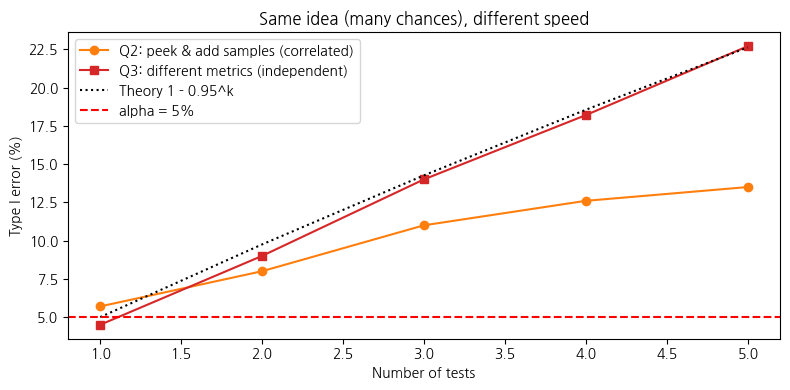

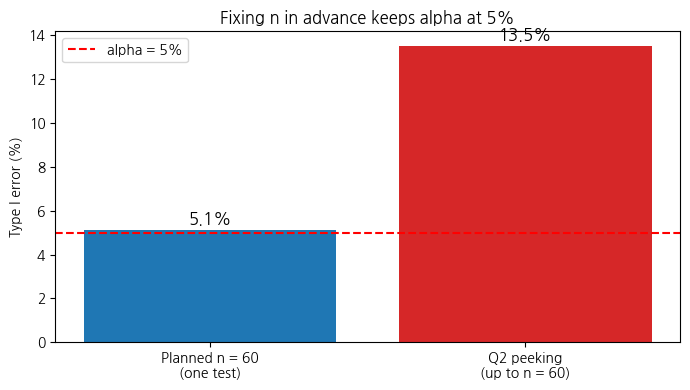

In [16]:
# 문제 3 · 💬 정리 (①~⑥ 통합)  ※ Q1~Q4를 먼저 실행하세요
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import unicodedata

ci = 1.96 * np.sqrt(0.05 * 0.95 / N_SIM) * 100
print("① Q1의 값이 5%에 가깝다는 것의 의미")
print("   약속한 α = 5%%, 실제 오류율 %.1f%% (우연 범위 %.1f~%.1f%%)" % (rate*100, 5-ci, 5+ci))
print("   → 가설검정은 '이번 결론이 맞다'를 보장하지 않는다.")
print("   → 정해진 절차를 지키면, 차이가 없을 때 틀리는 비율이 장기적으로 α 이하라는 것을 보장하는 도구다.")
print("   → 그 보장은 '표본크기 고정 + 미리 정한 검정 한 번'이라는 약속이 지켜질 때만 유효하다.\n")

ks = np.arange(1, 6)
q2_cum = [np.mean((found_at > 0) & (found_at <= k)) * 100 for k in ks]
q3_cum = [np.mean((pmat[:, :k] < 0.05).any(axis=1)) * 100 for k in ks]
print("② Q2와 Q3에서 오류율이 뛴 이유")
print("   공통점: 둘 다 '유의할 기회'를 여러 번 만들고, 한 번이라도 걸리면 그것을 결론으로 삼았다.")
print("   Q2: 같은 데이터에 표본을 덧붙여 검정을 반복 → p-값이 출렁이다 우연히 0.05 아래로 내려간 순간 멈춤")
print("       검정끼리 데이터를 공유해 서로 비슷하므로, 기회가 늘어도 오류율은 비교적 천천히 증가")
print("   Q3: 서로 독립인 지표를 여러 개 검정 → 각자 5%씩 걸릴 기회가 그대로 쌓여 1 − 0.95^k로 증가")
print("   → 메커니즘은 '다중 기회'로 같지만, Q2는 시간축(언제 멈출지), Q3는 대상축(무엇을 보고할지)을 조작한다.")
print("   검정 5번 기준 비교: Q2 %.1f%%, Q3 %.1f%%, 독립 이론 %.1f%%\n" % (q2_cum[-1], q3_cum[-1], (1-0.95**5)*100))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks, q2_cum, 'o-', color='C1', label='Q2: peek & add samples (correlated)')
ax.plot(ks, q3_cum, 's-', color='C3', label='Q3: different metrics (independent)')
ax.plot(ks, (1 - 0.95 ** ks) * 100, 'k:', label='Theory 1 - 0.95^k')
ax.axhline(5, color='red', ls='--', label='alpha = 5%')
ax.set_xlabel('Number of tests'); ax.set_ylabel('Type I error (%)')
ax.set_title('Same idea (many chances), different speed'); ax.legend()
plt.tight_layout(); plt.show()

cnt = (pmat < 0.05).sum(axis=1)
print("③ Q3 결과의 의미와 신뢰 여부")
print("   진짜 차이가 하나도 없는데 연구의 %.1f%%가 '유의한 지표'를 하나 이상 찾았다 (평균 %.2f개)." % (sim_rate*100, cnt.mean()))
print("   → '20개 중 유의한 하나만 보고'한 연구는 그 발견이 진짜인지 우연인지 구분할 수 없다.")
print("   → 신뢰하기 어렵다. 몇 개를 쟀는지 모두 공개하고, 본페로니 등으로 보정했을 때만 믿을 수 있다")
print("     (보정 후 오류율 %.1f%%).\n" % (bonf_rate*100))

print("④ HARKing은 Q2·Q3 중 어느 쪽과 닮았나?")
print("   Q3와 닮았다. 여러 결과를 먼저 보고, 유의하게 나온 것을 골라 '원래 이걸 검증하려 했다'고 가설을 세운다.")
print("   보고되지 않은 나머지 19개 검정이 숨겨진다는 점에서 Q3의 '골라 보고'와 같은 구조다.\n")

print("⑤ 사전 등록은 두 해킹을 각각 어떻게 막나?")
rows = [("해킹", "사전 등록에 미리 적는 것", "막히는 이유"),
        ("Q2 표본 추가", "표본크기 n, 검정 시점(한 번)", "중간에 보고 늘리면 등록과 달라 드러남"),
        ("Q3 골라 보고", "주 지표 1개(또는 전체 목록), 보정 방법", "다른 지표를 주인공으로 바꿀 수 없음")]
W = [max(sum(2 if unicodedata.east_asian_width(c) in 'WF' else 1 for c in r[j]) for r in rows) for j in range(3)]
for r in rows:
    print("   " + " | ".join(r[j] + " " * (W[j] - sum(2 if unicodedata.east_asian_width(c) in 'WF' else 1 for c in r[j])) for j in range(3)))
print("   → 결과를 보기 전에 '언제(n)'와 '무엇을(지표)'을 고정해 두므로, 결과에 맞춰 절차를 바꿀 수 없다.\n")

rng = np.random.default_rng(SEED)
fixed = stats.ttest_ind(rng.normal(0, 1, (N_SIM, 60)), rng.normal(0, 1, (N_SIM, 60)), axis=1).pvalue < 0.05
print("⑥ 문제 2의 '표본수 사전 설계'가 Q2를 막는 역할")
print("   검정력 분석으로 필요한 n을 미리 계산해 두면, '조금만 더 모아볼까'라는 여지가 사라진다.")
print("   같은 최대 60명이라도: 처음부터 60명으로 한 번 검정 %.1f%% vs 보면서 늘리기(Q2) %.1f%%" % (fixed.mean()*100, hack_rate*100))
print("   → 표본수 설계는 검정력(β)을 확보하는 동시에, 멈출 시점을 고정해 제1종 오류(α)도 지켜준다.")
fig, ax = plt.subplots(figsize=(7, 4))
v = [fixed.mean() * 100, hack_rate * 100]
ax.bar(['Planned n = 60\n(one test)', 'Q2 peeking\n(up to n = 60)'], v, color=['C0', 'C3'])
for i, x in enumerate(v):
    ax.text(i, x + 0.3, '%.1f%%' % x, ha='center', fontsize=12)
ax.axhline(5, color='red', ls='--', label='alpha = 5%')
ax.set_ylabel('Type I error (%)'); ax.set_title('Fixing n in advance keeps alpha at 5%'); ax.legend()
plt.tight_layout(); plt.show()

---

# 인과와 상관

> 상관을 인과로 착각하게 만드는 것은 무엇이며, 그것을 어떻게 걷어내는지를 봅니다.

## 문제 4 · 교란요인을 지우는 두 가지 방법 — 통제와 무작위화

`난이도 중` · `예상 30분`

**📖 상황**

- 7장 문제 1에서 이상한 것을 봤습니다. 펭귄 부리는 **전체로 보면 길수록 얇은데,
  종별로 나눠 보면 길수록 두꺼웠습니다.** 그때 "이 현상에는 이름이 붙어 있고,
  다음 시간 인과추론에서 다시 만난다"고 적어 두었습니다. **이제 그 이름을 붙입니다.**

- 원인은 **중첩요인(교란변수, Confounder)** — '종'이 부리 길이와 두께 양쪽에 영향을 주고
  있었습니다. 여기서 생겨난 가짜 음의 관계를 **허위상관(Spurious Correlation)**이라 부릅니다.

- 교란요인을 지우는 길은 두 갈래입니다.
  - **① 통제** — 층별로 나눠 보거나, 회귀식에 함께 넣기 (강의 10.3)
  - **② 무작위화** — 애초에 동전을 던져 배정하기, 즉 **무작위 통제 실험(RCT)** (강의 10.2)

- 이번 문제는 두 방법을 나란히 써 보고, **왜 무작위화가 더 강력한지** 확인합니다.

**🎯 이 문제로 배우는 것**

- 실제 데이터로 허위상관을 진단하고 통제로 걷어낸 뒤, 시뮬레이션으로 **무작위 배정의 힘**을
  확인합니다. 그리고 두 방법의 **결정적 차이**를 이해합니다.

In [22]:
# 문제 4 · 데이터 준비 (1/2) — 실행만 하세요
# 펭귄 부리 데이터: 7장 문제 1에서 봤던 그 데이터입니다.
bills = penguins.dropna(subset=['bill_length_mm', 'bill_depth_mm', 'species'])

print("분석에 사용할 데이터: %d 행\n" % len(bills))
print("종별 부리 평균 —— '종'이 두 변수 모두에 영향을 주고 있다는 단서")
print(bills.groupby('species')[['bill_length_mm', 'bill_depth_mm']].mean().round(2))

분석에 사용할 데이터: 342 행

종별 부리 평균 —— '종'이 두 변수 모두에 영향을 주고 있다는 단서
           bill_length_mm  bill_depth_mm
species                                 
Adelie              38.79          18.35
Chinstrap           48.83          18.42
Gentoo              47.50          14.98


### Q1 · 전체 데이터로 부리 길이와 두께의 관계를 회귀로 확인해 봅시다

- `bill_depth_mm`(반응변수)을 `bill_length_mm`(설명변수)으로 설명하는 **단순회귀**를 적합하세요.

- 기울기 계수와 p-값을 출력하세요.

- **이 결과만 보고했다면 어떤 결론이 되는지** 한 줄로 적으세요.

- `💡 힌트` `smf.ols(formula='...', data=bills).fit()` — 7장에서 쓴 방식과 같습니다.

- `📖 용어` **적합(fit)** — 모형의 **형태**만 정해 주면 절편과 기울기는 아직 빈칸입니다.
  그 빈칸을 데이터로부터 채워 넣는 것, 즉 흩어진 점들 사이로 **가장 잘 들어맞는 직선을 찾아내는 작업**이
  '적합'입니다. 코드에서는 `.fit()`이 그 순간이며, 메서드 이름 자체가 fit(적합)입니다.
  **"적합하세요" = "`.fit()`을 호출해 계수를 추정하세요"** 로 읽으면 됩니다.
  ('적용'과 다릅니다 — 적합이 먼저고, 적합해 둔 모형을 새 데이터에 쓰는 것이 적용입니다.)

▸모형: bill_depth = β0 + β1 × bill_length   (단순회귀)
▸β1(기울기): 부리 길이가 1mm 길어질 때 부리 두께가 평균 몇 mm 변하는가
▸H0: β1 = 0 (관계 없음) / H1: β1 ≠ 0 (관계 있음), α = 0.05

[적합 결과]  n = 342
절편 β0     = 20.8855
기울기 β1   = -0.0850
기울기 p-값 = 1.12e-05
R²          = 0.0552

[이 결과만 보고했다면]
▸부리가 1mm 길어질수록 두께는 0.085mm 얇아진다 (p = 1.1e-05, 유의)
→ 결론: '펭귄은 부리가 길수록 부리가 얇다(음의 관계)'


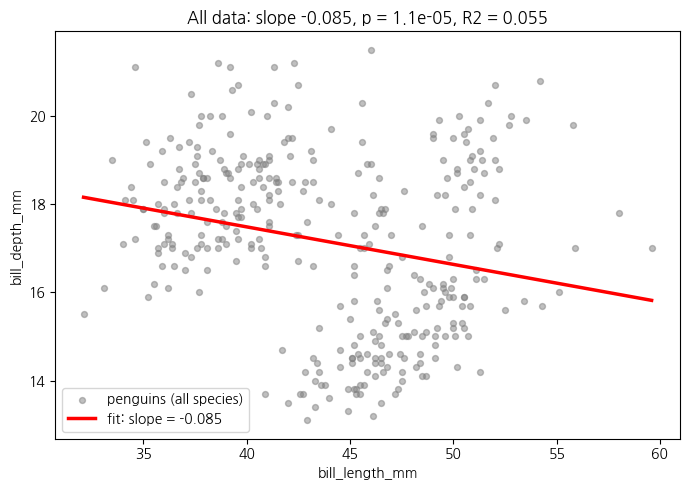

In [23]:
# 문제 4 · Q1 · 전체 데이터로 부리 길이와 두께의 관계를 회귀로 확인
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import numpy as np

print("▸모형: bill_depth = β0 + β1 × bill_length   (단순회귀)")
print("▸β1(기울기): 부리 길이가 1mm 길어질 때 부리 두께가 평균 몇 mm 변하는가")
print("▸H0: β1 = 0 (관계 없음) / H1: β1 ≠ 0 (관계 있음), α = 0.05\n")

model = smf.ols(formula='bill_depth_mm ~ bill_length_mm', data=bills).fit()
b0 = model.params['Intercept']
b1 = model.params['bill_length_mm']
p1 = model.pvalues['bill_length_mm']

print("[적합 결과]  n = %d" % int(model.nobs))
print("절편 β0     = %.4f" % b0)
print("기울기 β1   = %.4f" % b1)
print("기울기 p-값 = %.2e" % p1)
print("R²          = %.4f" % model.rsquared)

print("\n[이 결과만 보고했다면]")
print("▸부리가 1mm 길어질수록 두께는 %.3fmm %s (p = %.1e, 유의)"
      % (abs(b1), "얇아진다" if b1 < 0 else "두꺼워진다", p1))
print("→ 결론: '펭귄은 부리가 길수록 부리가 얇다(음의 관계)'")

x = np.linspace(bills['bill_length_mm'].min(), bills['bill_length_mm'].max(), 100)
plt.figure(figsize=(7, 5))
plt.scatter(bills['bill_length_mm'], bills['bill_depth_mm'], color='gray', alpha=0.5, s=18, label='penguins (all species)')
plt.plot(x, b0 + b1 * x, color='red', lw=2.5, label='fit: slope = %.3f' % b1)
plt.xlabel('bill_length_mm')
plt.ylabel('bill_depth_mm')
plt.title('All data: slope %.3f, p = %.1e, R2 = %.3f' % (b1, p1, model.rsquared))
plt.legend()
plt.tight_layout()
plt.show()

### Q2 · 종별로 층을 나눠 같은 회귀를 다시 해 봅시다

- 세 종(Adelie · Chinstrap · Gentoo) **각각에 대해** Q1과 똑같은 회귀를 적합하세요.

- 종별로 **n, 기울기 계수, p-값**을 표로 정리해 출력하세요.

- 이것은 강의 10장의 _"중학교 1·2·3학년으로 층을 나눈 후, 각 학년을 따로 해석"_ 과
  **똑같은 작업**입니다.

- `💡 힌트` `for 종, 그룹 in bills.groupby('species'):` 로 돌면서 각 그룹에 회귀를 적합하세요.

▸모형: bill_depth = β0 + β1 × bill_length   (단순회귀)
▸β1(기울기): 부리 길이가 1mm 길어질 때 부리 두께가 평균 몇 mm 변하는가
▸H0: β1 = 0 (관계 없음) / H1: β1 ≠ 0 (관계 있음), α = 0.05

[적합 결과]  n = 342
절편 β0     = 20.8855
기울기 β1   = -0.0850
기울기 p-값 = 1.12e-05
R²          = 0.0552

[이 결과만 보고했다면]
▸부리가 1mm 길어질수록 두께는 0.085mm 얇아진다 (p = 1.1e-05, 유의)
→ 결론: '펭귄은 부리가 길수록 부리가 얇다(음의 관계)'


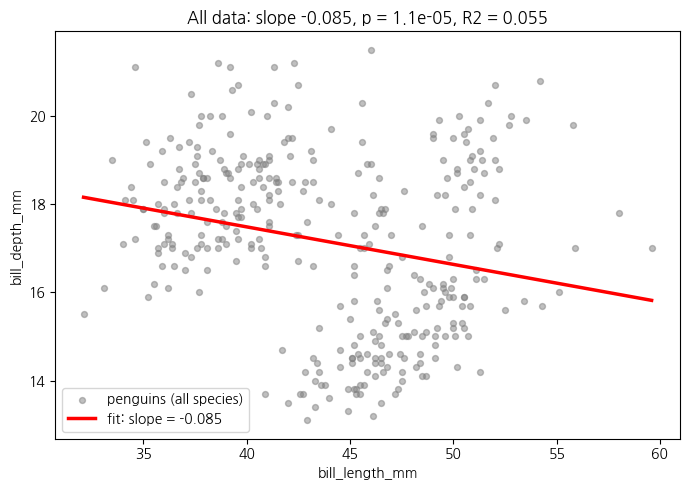

In [24]:
# 문제 4 · Q1 · 전체 데이터로 부리 길이와 두께의 관계를 회귀로 확인
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import numpy as np

print("▸모형: bill_depth = β0 + β1 × bill_length   (단순회귀)")
print("▸β1(기울기): 부리 길이가 1mm 길어질 때 부리 두께가 평균 몇 mm 변하는가")
print("▸H0: β1 = 0 (관계 없음) / H1: β1 ≠ 0 (관계 있음), α = 0.05\n")

model = smf.ols(formula='bill_depth_mm ~ bill_length_mm', data=bills).fit()
b0 = model.params['Intercept']
b1 = model.params['bill_length_mm']
p1 = model.pvalues['bill_length_mm']

print("[적합 결과]  n = %d" % int(model.nobs))
print("절편 β0     = %.4f" % b0)
print("기울기 β1   = %.4f" % b1)
print("기울기 p-값 = %.2e" % p1)
print("R²          = %.4f" % model.rsquared)

print("\n[이 결과만 보고했다면]")
print("▸부리가 1mm 길어질수록 두께는 %.3fmm %s (p = %.1e, 유의)"
      % (abs(b1), "얇아진다" if b1 < 0 else "두꺼워진다", p1))
print("→ 결론: '펭귄은 부리가 길수록 부리가 얇다(음의 관계)'")

x = np.linspace(bills['bill_length_mm'].min(), bills['bill_length_mm'].max(), 100)
plt.figure(figsize=(7, 5))
plt.scatter(bills['bill_length_mm'], bills['bill_depth_mm'], color='gray', alpha=0.5, s=18, label='penguins (all species)')
plt.plot(x, b0 + b1 * x, color='red', lw=2.5, label='fit: slope = %.3f' % b1)
plt.xlabel('bill_length_mm')
plt.ylabel('bill_depth_mm')
plt.title('All data: slope %.3f, p = %.1e, R2 = %.3f' % (b1, p1, model.rsquared))
plt.legend()
plt.tight_layout()
plt.show()

### Q3 · 종을 회귀식에 함께 넣어 통제해 봅시다

- 이번엔 층을 나누지 않고, **회귀식에 '종'을 함께 넣어** 한 번에 적합하세요.

- Q1의 결과와 **기울기·p-값·R²를 나란히 출력**해 비교하세요.

- `💡 힌트` `'bill_depth_mm ~ bill_length_mm + C(species)'`
  — `C()`는 범주형 변수를 더미로 자동 변환해 줍니다.
  (주의: `C`라는 이름의 변수를 만들면 이 기능이 가려집니다)

▸모형: bill_depth = β0 + β1 × bill_length + (종별 더미)
▸C(species): 종을 더미변수로 바꿈 (기준=Adelie, Chinstrap·Gentoo는 기준과의 높이 차이)
▸'종을 통제한다' = 같은 종 안에서 비교했을 때 부리 길이와 두께의 관계를 본다

[종 더미 계수 (Q3)]
  Intercept                         10.5922   (p = 2.4e-41)
  C(species)[T.Chinstrap]           -1.9332   (p = 2.5e-16)
  C(species)[T.Gentoo]              -5.1060   (p = 3.7e-85)
  bill_length_mm                     0.1999   (p = 8.7e-26)

[Q1 vs Q3 비교]
                       기울기 β1      p-값        R²
  Q1 (종 무시)          -0.0850    1.12e-05    0.055
  Q3 (종 통제)           0.1999    8.66e-26    0.769

[해석]
▸기울기 부호가 음(−) → 양(+) 로 뒤집혔다 (심슨의 역설)
▸같은 종 안에서는 부리가 길수록 두껍다. Q1의 음의 관계는 '종'이 만든 착시였다
▸R²도 0.055 → 0.769 로 크게 올라, 종을 넣은 모형이 데이터를 훨씬 잘 설명한다


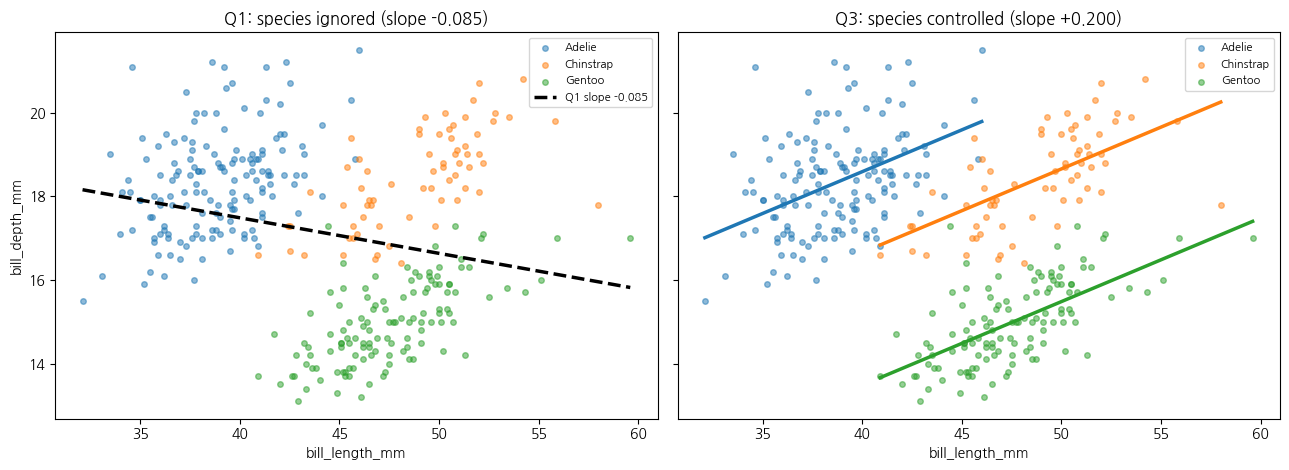

In [25]:
# 문제 4 · Q3 · 종을 회귀식에 함께 넣어 통제
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import numpy as np

print("▸모형: bill_depth = β0 + β1 × bill_length + (종별 더미)")
print("▸C(species): 종을 더미변수로 바꿈 (기준=Adelie, Chinstrap·Gentoo는 기준과의 높이 차이)")
print("▸'종을 통제한다' = 같은 종 안에서 비교했을 때 부리 길이와 두께의 관계를 본다\n")

m1 = smf.ols('bill_depth_mm ~ bill_length_mm', data=bills).fit()
m3 = smf.ols('bill_depth_mm ~ bill_length_mm + C(species)', data=bills).fit()

print("[종 더미 계수 (Q3)]")
for k, v in m3.params.items():
    print("  %-32s %8.4f   (p = %.1e)" % (k, v, m3.pvalues[k]))

print("\n[Q1 vs Q3 비교]")
print("                       기울기 β1      p-값        R²")
print("  Q1 (종 무시)         %8.4f    %.2e    %.3f" % (m1.params['bill_length_mm'], m1.pvalues['bill_length_mm'], m1.rsquared))
print("  Q3 (종 통제)         %8.4f    %.2e    %.3f" % (m3.params['bill_length_mm'], m3.pvalues['bill_length_mm'], m3.rsquared))

print("\n[해석]")
print("▸기울기 부호가 %s → %s 로 뒤집혔다 (심슨의 역설)"
      % ("음(−)" if m1.params['bill_length_mm'] < 0 else "양(+)", "양(+)" if m3.params['bill_length_mm'] > 0 else "음(−)"))
print("▸같은 종 안에서는 부리가 길수록 두껍다. Q1의 음의 관계는 '종'이 만든 착시였다")
print("▸R²도 %.3f → %.3f 로 크게 올라, 종을 넣은 모형이 데이터를 훨씬 잘 설명한다" % (m1.rsquared, m3.rsquared))

colors = {'Adelie': 'C0', 'Chinstrap': 'C1', 'Gentoo': 'C2'}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for a in ax:
    for sp, g in bills.groupby('species'):
        a.scatter(g['bill_length_mm'], g['bill_depth_mm'], color=colors[sp], alpha=0.5, s=16, label=sp)
x = np.linspace(bills['bill_length_mm'].min(), bills['bill_length_mm'].max(), 100)
ax[0].plot(x, m1.params['Intercept'] + m1.params['bill_length_mm'] * x, 'k--', lw=2.5, label='Q1 slope %.3f' % m1.params['bill_length_mm'])
ax[0].set_title('Q1: species ignored (slope %.3f)' % m1.params['bill_length_mm'])
for sp, g in bills.groupby('species'):
    xs = np.linspace(g['bill_length_mm'].min(), g['bill_length_mm'].max(), 50)
    pred = m3.predict({'bill_length_mm': xs, 'species': [sp] * len(xs)})
    ax[1].plot(xs, pred, color=colors[sp], lw=2.5)
ax[1].set_title('Q3: species controlled (slope +%.3f)' % m3.params['bill_length_mm'])
for a in ax:
    a.set_xlabel('bill_length_mm'); a.legend(fontsize=8)
ax[0].set_ylabel('bill_depth_mm')
plt.tight_layout()
plt.show()

### Q4 · 관찰연구에서 처치군과 대조군은 애초에 다릅니다

- 아래 데이터 준비 셀을 실행하면 학생 2,000명의 데이터 **두 벌**이 만들어집니다.
  같은 학생들인데 **강의 배정 방식만** 다릅니다.

- 먼저 **관찰연구(`df_obs`)**를 보세요. 성적이 좋고 열심인 학생이 스스로 신청한 상황입니다.

- ① 수강생과 비수강생의 `final_score` **단순 평균 차이**를 계산하세요.

- ② 두 집단의 **교란요인 평균**(`pre_score`, `study_hours`)도 함께 비교하세요.

- 참 효과는 **5.0점**입니다. 단순 평균 차이가 이 값과 얼마나 다른지 확인하세요.

- `💡 힌트` `df_obs.groupby('course')[['pre_score', 'study_hours', 'final_score']].mean()`

In [26]:
# 문제 4 · 데이터 준비 (2/2) — 실행만 하세요
# 같은 학생 2,000명에게 '새 온라인 강의'를 배정하는 두 가지 방식
TRUE_EFFECT = 5.0                      # 강의의 진짜 효과: 기말고사 +5점
rng = np.random.default_rng(279)
n = 2000

pre_score   = rng.normal(60, 10, n)    # 교란요인 ① 사전 성적
study_hours = rng.normal(10,  3, n)    # 교란요인 ② 주당 학습시간

# 잠재결과 — 두 교란요인은 결과(기말고사 성적)에도 직접 영향을 줍니다
Y0 = 20 + 0.7 * pre_score + 0.8 * study_hours + rng.normal(0, 5, n)  # 강의를 안 들었을 때
Y1 = Y0 + TRUE_EFFECT                                                 # 강의를 들었을 때

# (A) 관찰연구 — 성적 좋고 열심인 학생이 스스로 신청 (선택 편향)
signup_logit = -0.6 + 0.10 * (pre_score - 60) + 0.20 * (study_hours - 10)
course_obs = rng.binomial(1, 1 / (1 + np.exp(-signup_logit)))

# (B) 무작위 통제 실험 — 동전을 던져 배정
course_rct = rng.binomial(1, 0.5, n)

df_obs = pd.DataFrame({'pre_score': pre_score, 'study_hours': study_hours,
                       'course': course_obs, 'final_score': np.where(course_obs == 1, Y1, Y0)})
df_rct = pd.DataFrame({'pre_score': pre_score, 'study_hours': study_hours,
                       'course': course_rct, 'final_score': np.where(course_rct == 1, Y1, Y0)})

print("참 효과(우리가 추정해야 하는 값): %.1f점\n" % TRUE_EFFECT)
print("관찰연구 df_obs — 수강생 %d명 (%.1f%%)" % (df_obs['course'].sum(), df_obs['course'].mean()*100))
print("RCT      df_rct — 수강생 %d명 (%.1f%%)" % (df_rct['course'].sum(), df_rct['course'].mean()*100))

참 효과(우리가 추정해야 하는 값): 5.0점

관찰연구 df_obs — 수강생 751명 (37.5%)
RCT      df_rct — 수강생 1012명 (50.6%)


In [ ]:
# 문제 4 · Q4
# 여기에 코드를 작성해주세요.

### Q5 · 같은 학생들을 동전 던지기로 배정하면 어떻게 될까요

- 이제 **RCT(`df_rct`)**에 대해 Q4와 **똑같은 두 가지 계산**을 하세요.

- 단순 평균 차이를 참 효과 5.0점과 비교하세요.

- 두 방식의 **교란요인 균형**을 하나의 표로 정리하면 대비가 선명해집니다.
  (행: `pre_score`, `study_hours` / 열: 관찰연구 차이, RCT 차이)

- `💡 힌트` Q4의 코드를 `df_rct`에 대해 반복하면 됩니다.
  표는 `pd.DataFrame({'관찰연구': [...], 'RCT': [...]}, index=[...])` 형태로 만들 수 있습니다.

▸사용한 열: 처치 = 'course', 결과 = 'final_score' / 관찰연구 데이터 = df_obs

[1) 단순 평균 차이 (처치 − 대조) vs 참 효과 5.0점]
  관찰연구 :  11.34점  (참 효과와 +6.34점 차이)
  RCT      :   4.98점  (참 효과와 -0.02점 차이)

[2) 교란요인 균형: 두 집단의 평균 차이 (처치 − 대조)]
             관찰연구    RCT
pre_score       7.687  0.071
study_hours     1.382 -0.008

[해석]
▸관찰연구: 처치 집단과 대조 집단이 처음부터 다르다 (pre_score +7.69, study_hours +1.38)
  → 그 차이가 효과에 섞여 단순 차이(11.34)가 참 효과에서 +6.34점 벗어난다
▸RCT는 동전 던지기로 배정해 두 집단이 처음부터 비슷하다(교란요인 차이 ≈ 0)
  → 단순 평균 차이만으로도 참 효과 5.0점에 가깝게 나온다


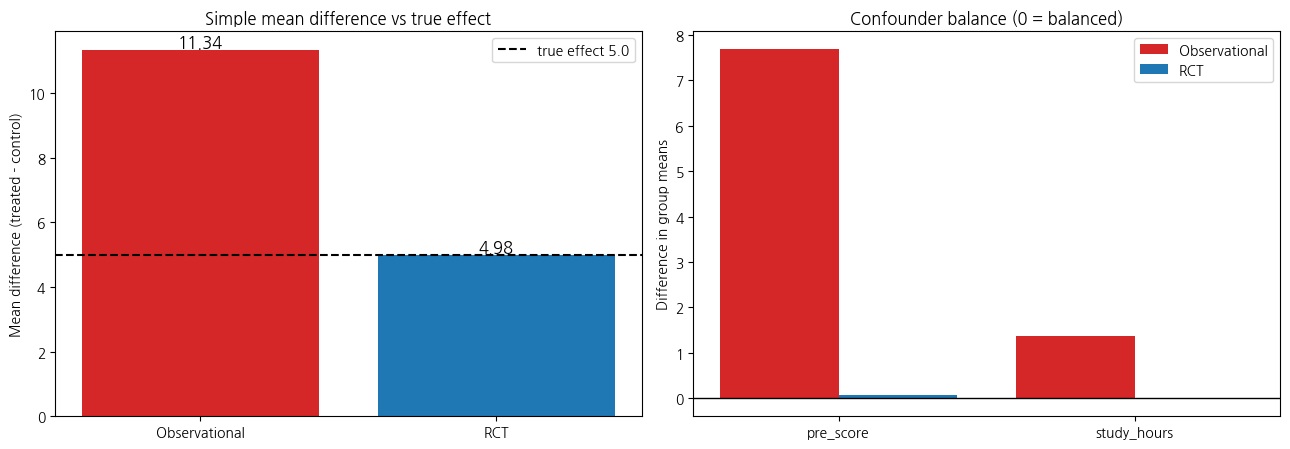

In [27]:
# 문제 5 · Q5 · 같은 학생들을 동전 던지기로 배정하면 (RCT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt

TRUE_EFFECT = 5.0
CONF = ['pre_score', 'study_hours']

# --- 열 이름 자동 찾기 (다르면 아래 두 줄에 직접 적으세요) ---
TREAT, OUTCOME = None, None
if TREAT is None:   # 0/1 두 값만 가지는 열 = 처치 여부
    TREAT = [c for c in df_rct.columns if c not in CONF and set(df_rct[c].dropna().unique()) <= {0, 1}][0]
if OUTCOME is None:  # 나머지 숫자 열 중 마지막 = 결과 점수
    OUTCOME = [c for c in df_rct.select_dtypes('number').columns if c not in CONF + [TREAT] and 'id' not in c.lower()][-1]
# Q4에서 쓴 관찰연구 데이터 찾기
obs_name = [k for k, v in list(globals().items()) if isinstance(v, pd.DataFrame) and k != 'df_rct'
            and k.startswith('df') and set(CONF + [TREAT, OUTCOME]) <= set(v.columns)][0]
df_obs = globals()[obs_name]
print("▸사용한 열: 처치 = '%s', 결과 = '%s' / 관찰연구 데이터 = %s\n" % (TREAT, OUTCOME, obs_name))

def analyze(d):
    t, c = d[d[TREAT] == 1], d[d[TREAT] == 0]
    diff = t[OUTCOME].mean() - c[OUTCOME].mean()
    bal = [t[v].mean() - c[v].mean() for v in CONF]
    return diff, bal

diff_obs, bal_obs = analyze(df_obs)
diff_rct, bal_rct = analyze(df_rct)

print("[1) 단순 평균 차이 (처치 − 대조) vs 참 효과 %.1f점]" % TRUE_EFFECT)
print("  관찰연구 : %6.2f점  (참 효과와 %+.2f점 차이)" % (diff_obs, diff_obs - TRUE_EFFECT))
print("  RCT      : %6.2f점  (참 효과와 %+.2f점 차이)" % (diff_rct, diff_rct - TRUE_EFFECT))

print("\n[2) 교란요인 균형: 두 집단의 평균 차이 (처치 − 대조)]")
table = pd.DataFrame({'관찰연구': bal_obs, 'RCT': bal_rct}, index=CONF).round(3)
print(table.to_string())

print("\n[해석]")
print("▸관찰연구: 처치 집단과 대조 집단이 처음부터 다르다 (pre_score %+.2f, study_hours %+.2f)" % tuple(bal_obs))
print("  → 그 차이가 효과에 섞여 단순 차이(%.2f)가 참 효과에서 %+.2f점 벗어난다" % (diff_obs, diff_obs - TRUE_EFFECT))
print("▸RCT는 동전 던지기로 배정해 두 집단이 처음부터 비슷하다(교란요인 차이 ≈ 0)")
print("  → 단순 평균 차이만으로도 참 효과 %.1f점에 가깝게 나온다" % TRUE_EFFECT)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].bar(['Observational', 'RCT'], [diff_obs, diff_rct], color=['C3', 'C0'])
ax[0].axhline(TRUE_EFFECT, color='black', ls='--', label='true effect %.1f' % TRUE_EFFECT)
for i, v in enumerate([diff_obs, diff_rct]):
    ax[0].text(i, v, '%.2f' % v, ha='center', va='bottom', fontsize=12)
ax[0].set_ylabel('Mean difference (treated - control)')
ax[0].set_title('Simple mean difference vs true effect'); ax[0].legend()

x = np.arange(len(CONF))
ax[1].bar(x - 0.2, bal_obs, 0.4, color='C3', label='Observational')
ax[1].bar(x + 0.2, bal_rct, 0.4, color='C0', label='RCT')
ax[1].axhline(0, color='black', lw=1)
ax[1].set_xticks(x); ax[1].set_xticklabels(CONF)
ax[1].set_ylabel('Difference in group means')
ax[1].set_title('Confounder balance (0 = balanced)'); ax[1].legend()
plt.tight_layout(); plt.show()

### 💬 정리 · 결과를 말로 설명해 보기

- Q1의 기울기는 **음수**인데 Q2·Q3의 기울기는 **양수**였습니다. 같은 데이터에서 부호가 뒤집힌
  이유는 무엇인가요? 이 현상의 이름은 무엇인가요?

- Q2(층별 분석)와 Q3(다중회귀)는 같은 결론을 줬습니다. **두 방법의 차이**는 무엇인가요?
  층이 아주 많아지면 어느 쪽이 유리할까요?

- Q4에서 관찰연구의 단순 비교값은 참 효과 5점과 크게 달랐습니다.
  **교란요인 균형 표를 근거로** 그 이유를 설명해 보세요.

- Q5의 RCT는 `pre_score`도 `study_hours`도 **통제하지 않았는데** 참값에 가까웠습니다.
  어떻게 이런 일이 가능한가요?

- 통제(Q3)와 무작위화(Q5)의 **결정적 차이**는 무엇인가요?
  **우리가 아직 모르는 교란요인**이 있다면 어느 쪽이 안전한가요?

- 그런데 현실에서 RCT가 늘 가능한가요? **불가능한 예를 두 개** 들어 보세요.

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 강의 10장은 RCT를 이렇게 설명했습니다 — _"중첩요인을 확인하지 않더라도, 그 효과를 무작위를
  이용하여 무효화할 수 있으므로, 알고자 하는 변수의 효과만 추정 가능합니다."_
  Q5의 균형 표가 이 문장의 증거입니다.

- **통제는 이름을 아는 교란요인만 지웁니다.** Q3에서 우리가 지운 것은 '종' 하나뿐입니다.
  성별·서식지·측정 연도는 그대로 남아 있습니다. 그 목록이 완전하다고 누가 보장해 줄까요?

- **무작위화는 아직 이름도 모르는 교란요인까지** 두 집단에 고르게 흩뿌립니다.
  이것이 RCT를 '인과추론의 황금 표준'이라 부르는 이유입니다.

- Q2 vs Q3 — 층별 분석은 층마다 따로 결론을 주므로 층이 많아지면 각 층의 n이 작아집니다.
  다중회귀는 모든 데이터를 한 번에 쓰지만, 대신 "층마다 기울기가 같다"는 가정을 덧붙입니다.

- 마지막 질문 — 강의는 담배와 건강을 예로 듭니다. 무작위로 흡연 집단을 만들 수 있을까요?
  윤리·비용·시간이 길을 막는 이 지점에서 **다음 문제가 시작됩니다.**

</details>

① 부호가 뒤집힌 이유와 이름
   Q1 기울기 -0.085 (종 무시) → Q3 기울기 +0.200 (종 통제)
   종마다 부리 길이·두께의 '평균 위치'가 다르다. Gentoo는 부리가 길지만 얇아서,
   세 종을 섞으면 종 간 차이가 '길수록 얇다'로 보이고, 종 안에서는 '길수록 두껍다'.
   → 이름: 심슨의 역설 (교란요인 '종'이 관계의 방향을 뒤집음)

② 층별 분석(Q2) vs 다중회귀(Q3)
   층별: 종마다 따로 회귀 → 기울기 3개 Adelie 0.179, Chinstrap 0.222, Gentoo 0.205
   회귀: 한 모형에 종 더미 → 공통 기울기 1개 0.200 (종별로 높이만 다름)
   층이 아주 많아지면(변수 여러 개 × 구간) 층마다 표본이 몇 개 안 되거나 비어 버린다
   → 모든 데이터를 한 번에 쓰는 다중회귀가 유리 (단, 모형 형태 가정이 맞아야 함)

③ 관찰연구 단순 비교 11.34점 vs 참 효과 5.0점
             관찰연구   RCT
pre_score        7.69  0.07
study_hours      1.38 -0.01
   관찰연구는 처치 집단이 원래 pre_score +7.69, study_hours +1.38만큼 달랐다.
   이 출발점 차이가 처치 효과에 섞여 단순 비교가 +6.34점 어긋났다

④ RCT는 통제 없이도 4.98점으로 참값에 가까웠다
   동전 던지기로 배정하면 처치가 학생 특성과 무관해져 두 집단이 처음부터 비슷하다
   (차이 pre_score +0.07, study_hours -0.01 ≈ 0) → 남은 차이는 처치 효과뿐

⑤ 통제 vs 무작위화
   통제: 우리가 '알고 측정한' 교란요인만 보정할 수 있다
   무작위화: 아는 것·모르는 것 모든 교란요인을 두 집단에 고르게 나눈다
   시뮬레이션(참 효과 5, 모르는 교란 U 존재): 아는 x만 통제 8.59 / RCT 4.83
   → 모르는 교란요인이 있다면 무작위화(RCT)가 안전하다


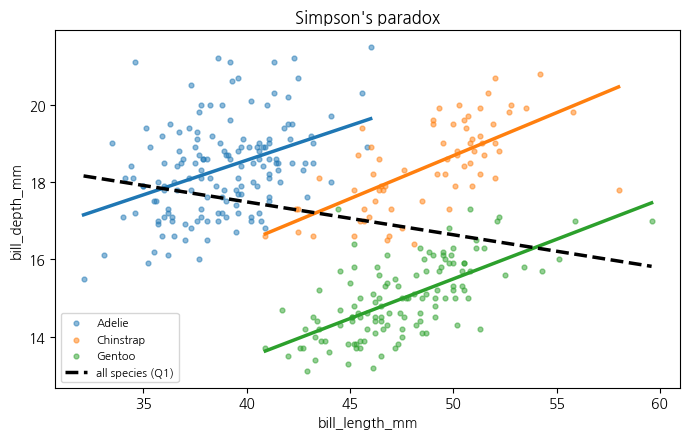

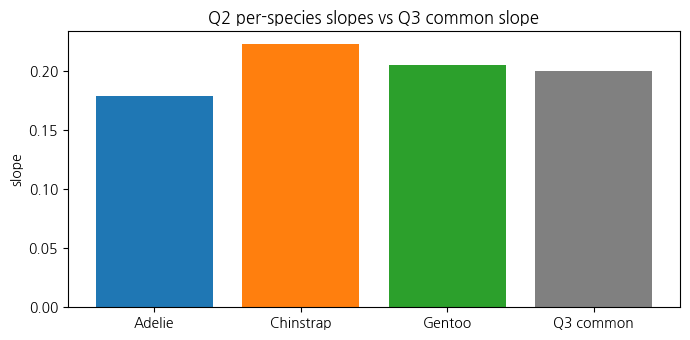

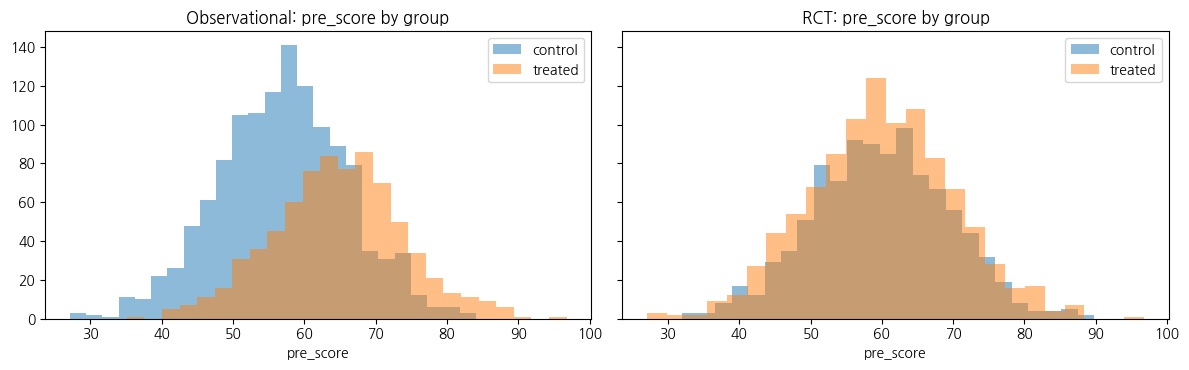

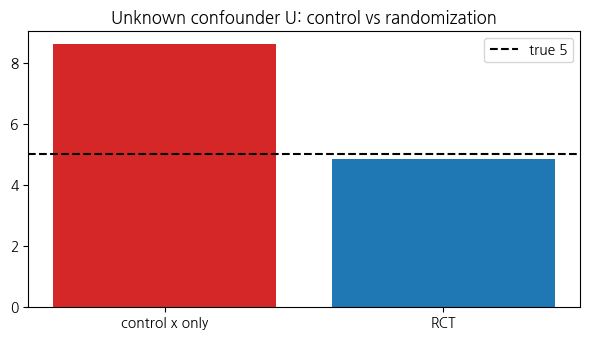

In [28]:
# 💬 정리 · 결과를 말로 설명해 보기 (①~⑥)  ※ bills, df_rct, 관찰연구 데이터가 있어야 함
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf

TRUE_EFFECT, CONF = 5.0, ['pre_score', 'study_hours']
TREAT = [c for c in df_rct.columns if c not in CONF and set(df_rct[c].dropna().unique()) <= {0, 1}][0]
OUTCOME = [c for c in df_rct.select_dtypes('number').columns if c not in CONF + [TREAT] and 'id' not in c.lower()][-1]
OBS = [v for k, v in list(globals().items()) if isinstance(v, pd.DataFrame) and k != 'df_rct'
          and k.startswith('df') and set(CONF + [TREAT, OUTCOME]) <= set(v.columns)][0]
col = {'Adelie': 'C0', 'Chinstrap': 'C1', 'Gentoo': 'C2'}

# ① 심슨의 역설
m1 = smf.ols('bill_depth_mm ~ bill_length_mm', data=bills).fit()
m3 = smf.ols('bill_depth_mm ~ bill_length_mm + C(species)', data=bills).fit()
print("① 부호가 뒤집힌 이유와 이름")
print("   Q1 기울기 %.3f (종 무시) → Q3 기울기 %+.3f (종 통제)" % (m1.params.iloc[1], m3.params['bill_length_mm']))
print("   종마다 부리 길이·두께의 '평균 위치'가 다르다. Gentoo는 부리가 길지만 얇아서,")
print("   세 종을 섞으면 종 간 차이가 '길수록 얇다'로 보이고, 종 안에서는 '길수록 두껍다'.")
print("   → 이름: 심슨의 역설 (교란요인 '종'이 관계의 방향을 뒤집음)\n")
fig, ax = plt.subplots(figsize=(7, 4.5))
for sp, g in bills.groupby('species'):
    ax.scatter(g.bill_length_mm, g.bill_depth_mm, color=col[sp], s=12, alpha=.5, label=sp)
    b = np.polyfit(g.bill_length_mm, g.bill_depth_mm, 1); xs = np.linspace(g.bill_length_mm.min(), g.bill_length_mm.max(), 2)
    ax.plot(xs, np.polyval(b, xs), color=col[sp], lw=2.5)
xs = np.linspace(bills.bill_length_mm.min(), bills.bill_length_mm.max(), 2)
ax.plot(xs, m1.params.iloc[0] + m1.params.iloc[1] * xs, 'k--', lw=2.5, label='all species (Q1)')
ax.set_xlabel('bill_length_mm'); ax.set_ylabel('bill_depth_mm'); ax.set_title("Simpson's paradox"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# ② 층별 분석 vs 다중회귀
strat = {sp: smf.ols('bill_depth_mm ~ bill_length_mm', data=g).fit().params['bill_length_mm'] for sp, g in bills.groupby('species')}
print("② 층별 분석(Q2) vs 다중회귀(Q3)")
print("   층별: 종마다 따로 회귀 → 기울기 3개 %s" % ", ".join("%s %.3f" % (k, v) for k, v in strat.items()))
print("   회귀: 한 모형에 종 더미 → 공통 기울기 1개 %.3f (종별로 높이만 다름)" % m3.params['bill_length_mm'])
print("   층이 아주 많아지면(변수 여러 개 × 구간) 층마다 표본이 몇 개 안 되거나 비어 버린다")
print("   → 모든 데이터를 한 번에 쓰는 다중회귀가 유리 (단, 모형 형태 가정이 맞아야 함)\n")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(list(strat.keys()) + ['Q3 common'], list(strat.values()) + [m3.params['bill_length_mm']],
       color=[col[k] for k in strat] + ['gray'])
ax.set_ylabel('slope'); ax.set_title('Q2 per-species slopes vs Q3 common slope'); plt.tight_layout(); plt.show()

# ③ 관찰연구 / ④ RCT
def gap(d):
    t, c = d[d[TREAT] == 1], d[d[TREAT] == 0]
    return t[OUTCOME].mean() - c[OUTCOME].mean(), [t[v].mean() - c[v].mean() for v in CONF]
do, bo = gap(OBS); dr, br = gap(df_rct)
print("③ 관찰연구 단순 비교 %.2f점 vs 참 효과 %.1f점" % (do, TRUE_EFFECT))
print(pd.DataFrame({'관찰연구': bo, 'RCT': br}, index=CONF).round(2).to_string())
print("   관찰연구는 처치 집단이 원래 pre_score %+.2f, study_hours %+.2f만큼 달랐다." % tuple(bo))
print("   이 출발점 차이가 처치 효과에 섞여 단순 비교가 %+.2f점 어긋났다\n" % (do - TRUE_EFFECT))
print("④ RCT는 통제 없이도 %.2f점으로 참값에 가까웠다" % dr)
print("   동전 던지기로 배정하면 처치가 학생 특성과 무관해져 두 집단이 처음부터 비슷하다")
print("   (차이 pre_score %+.2f, study_hours %+.2f ≈ 0) → 남은 차이는 처치 효과뿐\n" % tuple(br))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, d, nm in [(ax[0], OBS, 'Observational'), (ax[1], df_rct, 'RCT')]:
    a.hist(d.loc[d[TREAT] == 0, 'pre_score'], bins=25, alpha=.5, label='control')
    a.hist(d.loc[d[TREAT] == 1, 'pre_score'], bins=25, alpha=.5, label='treated')
    a.set_title('%s: pre_score by group' % nm); a.set_xlabel('pre_score'); a.legend()
plt.tight_layout(); plt.show()

# ⑤ 통제 vs 무작위화: 모르는 교란요인 U가 있을 때 (작은 시뮬레이션)
rng = np.random.default_rng(0); n = 20000
x, u = rng.normal(size=n), rng.normal(size=n)
t_obs = (x + u + rng.normal(size=n) > 0).astype(int)
t_rct = rng.integers(0, 2, n)
y = lambda t: 5 * t + 3 * x + 3 * u + rng.normal(size=n)
sim = pd.DataFrame({'x': x, 't': t_obs, 'y': y(t_obs)})
ctrl = smf.ols('y ~ t + x', data=sim).fit().params['t']
yr = y(t_rct)
rct = yr[t_rct == 1].mean() - yr[t_rct == 0].mean()
print("⑤ 통제 vs 무작위화")
print("   통제: 우리가 '알고 측정한' 교란요인만 보정할 수 있다")
print("   무작위화: 아는 것·모르는 것 모든 교란요인을 두 집단에 고르게 나눈다")
print("   시뮬레이션(참 효과 5, 모르는 교란 U 존재): 아는 x만 통제 %.2f / RCT %.2f" % (ctrl, rct))
print("   → 모르는 교란요인이 있다면 무작위화(RCT)가 안전하다\n")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(['control x only', 'RCT'], [ctrl, rct], color=['C3', 'C0']); ax.axhline(5, color='k', ls='--', label='true 5')
ax.set_title('Unknown confounder U: control vs randomization'); ax.legend(); plt.tight_layout(); plt.show()

print("⑥ RCT가 불가능한 예")
print("   ▸흡연이 폐암에 미치는 영향: 사람에게 흡연을 무작위로 시킬 수 없다 (윤리)")
print("   ▸펭귄의 종이 부리에 미치는 영향: 종을 무작위로 배정할 수 없다 (물리적으로 불가능)")
print("   ▸그 밖에 성별·학력·국가 정책처럼 바꿀 수 없거나 비용이 너무 큰 경우")
print("   → 이럴 땐 관찰연구 + 통제(회귀)로 최선을 다하되, 모르는 교란요인의 한계를 함께 밝힌다")

## 문제 5 · 미니 프로젝트 — 실험할 수 없을 때

`난이도 상` · `예상 40분`

**📖 상황**

- 문제 4에서 확인했습니다. 무작위 배정만 되면 인과효과는 **단순 평균 차이**로 구해집니다.
  문제는 **대부분의 현실에서 무작위 배정이 불가능**하다는 것입니다.

- 그래서 관찰 데이터만 놓고 인과효과에 다가가는 방법들이 있습니다. 강의 10.3의 두 가지를 씁니다.

- **① 경향점수 짝짓기(PSM)** — 처치를 받을 '경향'이 비슷한 사람끼리 짝지어
  **'통계적 쌍둥이'** 집단을 만듭니다.

- **② 이중차분법(DiD)** — 시간축을 도입해, 통제군의 변화를 '정책이 없었다면 일어났을 변화'로
  삼고 실험군의 변화에서 빼냅니다.

- 두 방법 모두 **가정 위에 서 있습니다.** 그래서 이 문제의 진짜 목표는 추정값을 구하는 것이 아니라,
  **그 가정을 검증하는 절차까지 해 보는 것**입니다.

**🎯 이 문제로 배우는 것**

- PSM으로 선택편향을 보정하고 **공변량 균형**으로 검증하며,
  DiD로 정책효과를 추정하고 **평행추세 확인·플라시보 검정**으로 반증을 시도합니다.

In [ ]:
# 문제 5 · 데이터 준비 (1/2) — 실행만 하세요
# 문제 4에서 만든 관찰연구 데이터(df_obs)를 그대로 이어서 씁니다.
print("관찰연구 데이터 df_obs: %d행" % len(df_obs))
print("  수강생 %d명 / 비수강생 %d명" % ((df_obs['course']==1).sum(), (df_obs['course']==0).sum()))
print("  단순 평균 비교(문제 4 Q4): %+.2f점" % (
    df_obs.loc[df_obs['course']==1, 'final_score'].mean()
    - df_obs.loc[df_obs['course']==0, 'final_score'].mean()))
print("  우리가 되찾아야 하는 참 효과: %+.1f점" % TRUE_EFFECT)

### Q1 · 경향점수를 추정해 봅시다

- **로지스틱 회귀**로 각 학생이 강의를 신청할 확률(= 경향점수)을 추정하세요.
  설명변수는 `pre_score`, `study_hours`이고 반응변수는 `course`입니다.

- 추정한 경향점수를 `df_obs['ps']` 열에 저장하세요. **Q2·Q3에서 계속 씁니다.**

- 수강생과 비수강생의 **경향점수 분포를 히스토그램으로 겹쳐 그려**,
  두 집단이 겹치는 구간이 있는지 확인하세요. (겹치는 구간이 있어야 짝을 찾을 수 있습니다)

- `💡 힌트` `sm.Logit(y, sm.add_constant(X)).fit(disp=0)` 으로 적합하고 `.predict()`로 확률을 얻습니다.
  히스토그램은 `plt.hist(..., alpha=0.5, label=...)`를 두 번 호출하면 겹쳐 그려집니다.

In [ ]:
# 문제 5 · Q1
# 여기에 코드를 작성해주세요.

### Q2 · 1:1 짝짓기로 ATT를 추정해 봅시다

- 수강생(실험군) 한 명마다, **경향점수가 가장 가까운 비수강생(대조군) 1명**을 찾아 짝지으세요.

- 짝지어진 두 집단의 `final_score` 평균 차이를 계산하세요.
  이것이 **ATT**(처치집단에 대한 평균 처치효과)입니다.

- 세 값을 **나란히 출력**해 비교하세요.
  **① 단순 평균 비교(문제 4) ② PSM 이후 ATT ③ 참 효과 5.0점**

- `💡 힌트` `NearestNeighbors(n_neighbors=1).fit(대조군[['ps']])` 로 학습한 뒤
  `.kneighbors(실험군[['ps']])`를 호출하면 `(거리, 인덱스)`를 돌려줍니다.
  인덱스로 대조군을 골라낼 때는 `대조군.iloc[indices.flatten()]`를 씁니다.

In [ ]:
# 문제 5 · Q2
# 여기에 코드를 작성해주세요.

### Q3 · 짝짓기가 잘 됐는지 검증해 봅시다 — 공변량 균형

- 짝짓기는 **잘 됐다고 가정하면 안 되고, 확인해야 합니다.**
  이 확인 절차를 **공변량 균형(Covariate Balance)** 점검이라 부릅니다.

- `pre_score`와 `study_hours`에 대해, 두 집단의 평균 차이를
  **짝짓기 전 / 짝짓기 후**로 나누어 표로 만드세요.

- 짝짓기 후 차이가 0에 가까워졌다면 성공입니다.

- `💡 힌트` 표는 `pd.DataFrame({'짝짓기 전': [...], '짝짓기 후': [...]}, index=['pre_score', 'study_hours'])`

In [ ]:
# 문제 5 · Q3
# 여기에 코드를 작성해주세요.

### Q4 · DiD — 평행추세 가정을 **먼저** 확인해 봅시다

- 아래 데이터 준비 셀을 실행하면 서울·부산의 **2020~2025년 패널 데이터**가 만들어집니다.
  무료 공공 와이파이 정책은 **2024년 서울에만** 시행되었습니다.

- DiD를 계산하기 **전에** 가정을 확인합니다. **정책 시행 이전(2020~2023)만 잘라서**
  두 도시의 연도별 평균 데이터 사용량을 **꺾은선 그래프**로 그리세요.

- 연도별 **두 도시의 격차**(서울 − 부산)도 숫자로 출력하세요.

- 격차가 일정하게 유지되고 있다면, 평행추세 가정을 믿을 만합니다.

- `💡 힌트` `sns.lineplot(data=..., x='year', y='data_usage', hue='city', marker='o')`
  격차는 `.groupby(['year','city'])['data_usage'].mean().unstack()` 후 두 열을 빼면 구할 수 있습니다.

In [ ]:
# 문제 5 · 데이터 준비 (2/2) — 실행만 하세요
# 서울(실험군) / 부산(통제군)의 1인당 월 데이터 사용량(GB), 2020~2025년
POLICY_YEAR = 2024        # 서울시가 무료 공공 와이파이를 도입한 해
TRUE_DID    = 4.0         # 정책의 진짜 효과: +4 GB
rng = np.random.default_rng(2024)

records = []
for city, baseline, is_seoul in [('서울', 15.0, 1), ('부산', 10.0, 0)]:
    for person in range(300):
        person_effect = rng.normal(0, 2.0)                  # 사람마다 타고난 사용량 차이
        for year in range(2020, 2026):
            time_trend = 1.5 * (year - 2020)                # 두 도시에 똑같이 작용하는 시간 추세
            policy = TRUE_DID if (is_seoul and year >= POLICY_YEAR) else 0.0
            records.append((city, is_seoul, person + is_seoul * 300, year,
                            baseline + person_effect + time_trend + policy + rng.normal(0, 1.0)))

panel = pd.DataFrame(records, columns=['city', 'is_seoul', 'person_id', 'year', 'data_usage'])

print("패널 데이터: %d행 (도시 2 × 300명 × 6년)" % len(panel))
print("정책 시행: %d년, 서울만  /  참 효과: +%.1f GB\n" % (POLICY_YEAR, TRUE_DID))
print(panel.groupby(['year', 'city'])['data_usage'].mean().unstack().round(2))

In [ ]:
# 문제 5 · Q4
# 여기에 코드를 작성해주세요.

### Q5 · 2×2 DiD 회귀로 정책효과를 추정해 봅시다

- 정책 **직전 해(2023)**와 **직후 해(2024)**만 사용합니다.

- `is_post`(2024년이면 1) 변수를 만들고, 다음 세 항이 들어간 회귀를 적합하세요.
  **`is_seoul` + `is_post` + 두 변수의 상호작용**

- 결과표를 출력하고, **계수 세 개가 각각 무엇을 재고 있는지** 주석에 적으세요.

- 상호작용항 계수를 참 효과 **+4.0 GB**와 비교하세요.

- `💡 힌트` `smf.ols('data_usage ~ is_seoul * is_post', data=...)`
  — 수식의 `*`는 두 주효과와 상호작용을 **한꺼번에** 넣어 줍니다.
  결과표에서 상호작용항의 이름은 `is_seoul:is_post`입니다.

In [ ]:
# 문제 5 · Q5
# 계수 세 개의 의미
# is_seoul        의 의미:
# is_post         의 의미:
# is_seoul:is_post 의 의미:

# 여기에 코드를 작성해주세요.

### Q6 · 플라시보 검정으로 스스로 반증을 시도해 봅시다

- 우리 추정치를 **의심해 봅니다.** 정책이 **없었던 구간**에 똑같은 DiD를 적용하면
  효과가 0으로 나와야 정상입니다.

- **2022년 vs 2023년**(둘 다 정책 이전)으로 Q5와 똑같은 회귀를 돌리세요.

- 상호작용항 계수와 p-값을 출력하고, **검정을 통과했는지** 문장으로 판정하세요.

- 여기서 만약 유의한 효과가 나왔다면 **무엇을 의심해야 하는지**도 함께 적으세요.

- `💡 힌트` Q5의 코드에서 연도만 바꾸면 됩니다. `is_post`는 이제 2023년이면 1입니다.

In [ ]:
# 문제 5 · Q6
# 여기에 코드를 작성해주세요.

### Q7 · 보고 문장으로 정리해 봅시다

- 지금까지의 결과를 종합해, 두 분석을 보고서에 어떻게 적을지 **각각 한 문장**으로 쓰세요.

- 숫자만 적지 말고 **어떤 가정 위에서 얻은 값인지, 어떻게 검증했는지**를 함께 담으세요.

In [ ]:
# 문제 5 · Q7
# PSM 보고 문장 (추정값 + 사용한 방법 + 균형 검증 결과 + 남은 한계):
#
# DiD 보고 문장 (추정값 + 사용한 방법 + 평행추세 확인 + 플라시보 검정 결과):

### 💬 정리 · 결과를 말로 설명해 보기

- Q2의 ATT는 참값 5점에 가까웠고, 문제 4의 단순 비교는 크게 벗어났습니다.
  **PSM이 한 일**을 한 문장으로 설명해 보세요.

- Q3의 균형 표에서 짝짓기 후 교란요인 차이는 어떻게 변했나요?
  만약 짝짓기 **후에도** 차이가 크게 남아 있었다면 어떻게 해야 할까요?

- PSM은 **경향점수 모형에 넣은 변수만** 균형을 맞춥니다. 만약 관측하지 못한 교란요인
  (예: 학생의 타고난 이해력)이 있다면, Q2의 ATT를 인과효과라고 부를 수 있을까요?
  **문제 4의 RCT와 비교**해서 답해 보세요.

- Q4에서 정책 이전 4년간 두 도시의 격차는 거의 일정했습니다. 이것이 DiD의 **어떤 가정**을
  지지하나요? 만약 이전부터 격차가 벌어지고 있었다면 Q5의 계수를 어떻게 읽어야 할까요?

- Q5의 상호작용항이 왜 정책효과인가요? 네 개 평균값을 직접 계산해
  `(A₂ − A₁) − (B₂ − B₁)`과 일치하는지 확인해 보세요.

- Q6의 플라시보 검정이 만약 **유의하게** 나왔다면, 우리는 무엇을 의심해야 하나요?

- PSM과 DiD는 각각 어떤 상황에 쓰는 도구인가요? 두 방법의 **데이터 요구조건**
  (단면 데이터 vs 패널 데이터)은 어떻게 다른가요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 강의 10장은 DiD의 인과효과를 이렇게 적었습니다 —
  _"인과 효과 = ΔA − ΔB = (A₂ − A₁) − (B₂ − B₁)"_.
  Q5의 상호작용항 계수를 이 식과 손으로 맞춰 보면 **소수점까지 정확히 일치**합니다.
  회귀는 이 뺄셈을 대신 해 주는 도구일 뿐입니다.

- 강의 10장은 평행추세에 대해 이렇게 덧붙였습니다 — _"이 가정이 맞는지 확인하려면, 정책이
  시행되기 이전 여러 시점의 데이터를 그래프로 그려보아야 합니다."_ Q4가 정확히 그 작업입니다.
  시점이 두 개뿐이라면 이 확인 자체가 **불가능**하다는 점에 주목하세요.

- 플라시보 검정의 논리는 **"효과가 없어야 할 곳에서 효과가 나오면 방법이 틀렸다"**입니다.
  자기 결론을 스스로 반증하려 드는 습관이 통계에서 이런 모양으로 나타납니다.
  통과했다고 해서 방법이 옳음이 증명된 것은 아니라는 점도 함께 기억해 두세요.

- 세 번째 질문이 이 실습 전체의 결론입니다 — **PSM·DiD는 RCT의 대체품이 아닙니다.**
  무작위화가 자동으로 해 주던 일을, **가정을 명시적으로 걸고** 대신 해내는 차선책입니다.
  그래서 "어떤 가정을 걸었는지" 말할 수 없다면 그 추정치는 쓸 수 없습니다.

- 마지막 질문 — 시간축이 없는 데이터에서는 어느 방법을 쓸 수 없나요?
  반대로, 처치 시점이 명확한 정책이라면 어느 쪽이 더 강력한가요?

- 이 문제에서 다루지 못한 준실험 방법으로 **회귀 불연속 설계(RDD)**가 있습니다.
  "커트라인 바로 위/아래는 거의 같은 사람들"이라는 발상을 쓰는 방법으로,
  기준점이 존재하는 정책(장학금 커트라인, 정년 등)에서 강력하게 작동합니다.

</details>

In [ ]:
# 문제 5 · 정리
# 여기에 의견을 작성해주세요.